## Qual é o contexto e a motivação?

Como ajudar o cidadão a perceber mudanças, picos e períodos fora do comportamento habitual?

## Quais perguntas podem orientar a exploração?
* Como o volume de aplicações varia ao longo do período?
* Em quais meses ocorreram aumentos ou reduções relevantes?
* O pico coincide com alguma vacina específica, como a influenza?
* Como diferentes vacinas, salas ou estratégias se comportam no tempo?

## Quais critérios de aceite validam a história?
* Foram escolhidas visualizações adequadas para comparar períodos?
* O usuário consegue explorar meses, vacinas, salas e estratégias?
* Datas em mês (04/2026) e em dia (09/04/2026) foram padronizadas sem perder a rastreabilidade?
* Janeiro está no filtro do relatório, mas quase não aparece nas aplicações, e isso ficou visível?

    Nem o mês de janeiro e nem os de julho e agosto aparecem, além disso, há apenas cinco meses para análise, consistindo em poucos dados para uma análise comparatória entre diferentes períodos do ano ou entre diferentes anos.
    
* A análise explica o que os resultados podem significar?
* A interpretação evita tratar pico de aplicação como surto, cobertura da população ou necessidade de saúde?

## Informações extras de pesquisa

**População de Araranguá (IGBE 2026):** 77.625

LIMPEZA E ORGANIZAÇÃO

In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

MESES = {
    2 : 'Fev',
    3 : 'Mar',
    4 : 'Abr', 
    5 : 'Mai',
    6 : 'Jun'
}

DIAS_PT = {
    'Monday': 'Segunda',
    'Tuesday': 'Terça',
    'Wednesday': 'Quarta',
    'Thursday': 'Quinta',
    'Friday': 'Sexta',
    'Saturday': 'Sábado',
    'Sunday': 'Domingo'
}
ORDEM_DIAS = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']

df = pd.read_csv("../../data/processed/vacinas_analitico.csv")

df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 30883 entries, 0 to 30882
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   nome_do_bairro            30883 non-null  str    
 1   nome_da_vacina            30883 non-null  str    
 2   codigo_da_vacina          30883 non-null  int64  
 3   estrategia                30883 non-null  str    
 4   codigo_da_estrategia      30883 non-null  int64  
 5   dose                      30874 non-null  str    
 6   codigo_da_dose            30874 non-null  float64
 7   vacina_estrategia_e_dose  30883 non-null  str    
 8   lote                      30883 non-null  str    
 9   validade_do_lote          30883 non-null  str    
 10  data_da_aplicacao         30023 non-null  str    
 11  origem                    30023 non-null  str    
dtypes: float64(1), int64(2), str(9)
memory usage: 2.8 MB


,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,17/04/2026,02/04/2026,Tela de Aplicação


Primeiro analisamos a quantidade de vacinas por mês para ver se há alguma irregularidade ou anormalidade na quantidade de vacinas aplicadas durante o período analisado.

In [27]:
# CONVERSÃO DE TIPOS DE DADOS E ADIÇÃO DE COLUNAS RELEVANTES
df['data_da_aplicacao'] = pd.to_datetime(df['data_da_aplicacao'], format="%d/%m/%Y", errors="coerce")
df['validade_do_lote'] = pd.to_datetime(df['validade_do_lote'])
df['mes'] = df['data_da_aplicacao'].dt.to_period('M')
df['dia_semana'] = df['data_da_aplicacao'].dt.day_name().map(DIAS_PT)

df.head()

C:\Users\mirel\AppData\Local\Temp\ipykernel_9556\3549144256.py:3: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['validade_do_lote'] = pd.to_datetime(df['validade_do_lote'])


,nome_do_bairro,nome_da_vacina,codigo_da_vacina,estrategia,codigo_da_estrategia,dose,codigo_da_dose,vacina_estrategia_e_dose,lote,validade_do_lote,data_da_aplicacao,origem,mes,dia_semana
0,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,2026-04-17,2026-04-02,Tela de Aplicação,2026-04,Quinta
1,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,2026-04-17,2026-04-02,Tela de Aplicação,2026-04,Quinta
2,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,2026-04-17,2026-04-02,Tela de Aplicação,2026-04,Quinta
3,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,2026-04-17,2026-04-02,Tela de Aplicação,2026-04,Quinta
4,Arapongas,"Vacina COVID-19-RNAm, Pfizer (Comirnaty)",87,Rotina,1,REVACINAÇÃO,10.0,"Vacina COVID-19-RNAm, Pfizer (Comirnaty) (87) ...",MT7306,2026-04-17,2026-04-02,Tela de Aplicação,2026-04,Quinta


### FUNÇÕES DE PLOT

In [28]:
def get_top(df, column, top=5, ascending = True):
    #top5 = df.sort_values(column, ascending=False).head(top)
    valores_frequentes = df[column].value_counts(ascending=ascending).head(top).index
    top5 = df[df[column].isin(valores_frequentes)]
    return top5

# -------- COUNT TEMPORAL

def stacked_month_by_column(df, column, ax0, type = 'area'):
    df_pivot = df.groupby(['mes',column]).size().unstack(fill_value=0)
    ax1 = df_pivot.plot(kind=type, stacked=True, figsize=(10, 6), ax = ax0)
    labels = [MESES[m.month] for m in df_pivot.index]
    ax1.set_xticklabels(labels)

def analise_temporal(df, column, legend_title = 'Legenda', top=5, ascending = True):
    df_top = get_top(df, column, top, ascending)
    fig, axes = plt.subplots(2, 1, figsize = (24, 20))

    if ascending == False:
        ordem = 'mais'
    else:
        ordem = 'menos'

    # POR BAIRRO
    stacked_month_by_column(df_top, column, axes[0], 'bar')
    axes[0].legend(title = legend_title, loc='center right', bbox_to_anchor=(-0.1, 0.5))
    axes[0].set_title(f'{top} {ordem} frequentes', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Mês', fontsize=12)
    axes[0].set_ylabel('Quantidade', fontsize=12)

    # POR ESTRATÉGIA
    stacked_month_by_column(df_top, column, axes[1])
    axes[1].legend(title = legend_title, loc='center right', bbox_to_anchor=(-0.1, 0.5))
    axes[1].set_title(f'{top} {ordem} frequentes', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Mês', fontsize=12)
    axes[1].set_ylabel('Quantidade', fontsize=12)

    if ascending == False:
        ordem = 'Maiores'
    else:
        ordem = 'Menores'

    fig.suptitle(f'Análise da Quantitativa Mensal dos {ordem}', fontsize=16, fontweight='bold')
    plt.tight_layout()
    fig.subplots_adjust(hspace=0.6, wspace=0.3)
    plt.show()

# --------- DISTRIBUIÇÃO
    
def heatmap_by_column(df, column, index, hue, ax):
    tabela = df.pivot_table(index=index, columns=column, values='data_da_aplicacao', aggfunc='count')
    
    if column == 'dias_da_semana':
        tabela = tabela[ORDEM_DIAS]  # garante a ordem correta das colunas
    sns.heatmap(tabela, cmap='YlOrRd', annot=True, fmt='g', ax=ax)

def boxplot_by_column(df, column, ax):
    contagem_diaria = df.groupby([df['data_da_aplicacao'].dt.date, column, 'mes']).size().reset_index(name='total')

    # Boxplot: distribuição dos totais diários, agrupado por mês
    sns.boxplot(data=contagem_diaria, x='mes', y='total', hue=column, ax=ax)
    ax.set_yscale('log')
    plt.suptitle('')  # remove o título automático duplicado que o pandas adiciona


def distribuicao(df, column, hue = '', index = 'mes', legend_title = 'Legenda', top = 5, ascending = True):
    df_top = get_top(df, column, top, ascending)
    fig, axes = plt.subplots(2, 1, figsize = (24, 20))

    if ascending == False:
        ordem = 'mais'
    else:
        ordem = 'menos'

    heatmap_by_column(df_top, column, index, hue, axes[0])
    axes[0].set_title(f'{top} {ordem} frequentes', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Categoria', fontsize=12)
    axes[0].set_ylabel('Mês', fontsize=12)

    boxplot_by_column(df_top, column, axes[1])
    axes[1].legend(title = legend_title, loc='center right', bbox_to_anchor=(-0.1, 0.5))
    axes[1].set_title(f'Distribuição de vacinas', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Mês', fontsize=12)
    axes[1].set_ylabel('Vacinas por dia', fontsize=12)

    if ascending == False:
        ordem = 'Maiores'
    else:
        ordem = 'Menores'

    fig.suptitle(f'Análise da Distribuição Mensal dos {ordem}', fontsize=16, fontweight='bold')
    plt.tight_layout()
    fig.subplots_adjust(hspace=0.4, wspace=0.3)
    plt.show()

In [29]:
def media_movel_by_column(df, column):
    count = df.groupby(df[column].dt.date).size()
    media_movel = count.rolling(window=7).mean()
    return media_movel

def plot_table(df, column, ax):
    # Prepara os dados da tabela (só as mudanças relevantes)
    df.head()
    relevantes = df[df['variacao_pct'].abs() > limite].copy()
    relevantes['mes'] = relevantes['mes'].dt.strftime('%b/%Y')  # formata a data como texto
    relevantes['variacao_pct'] = relevantes['variacao_pct'].round(1).astype(str) + '%'

    tabela_dados = relevantes[['mes', column, 'variacao_pct']].values

    if len(tabela_dados) > 0:
        tabela = ax.table(cellText=tabela_dados, 
                        colLabels=['Mês', 'Categoria', 'Variação'],
                        loc='center', cellLoc='center')
        tabela.auto_set_font_size(False)
        tabela.set_fontsize(9)
        tabela.scale(1, 1.5)
    else:
        ax.text(0.5, 0.5, 'Nenhuma variação relevante encontrada', 
                ha='center', va='center', fontsize=10, style='italic')
    ax.axis('off')

def plot_line(df, column, ax):
    df.head()
    limite = 20  # ex: variação acima de 20% é "relevante"
    df['mes'] = pd.to_datetime(df['mes'], format="%Y-%m", errors="coerce")

    #mudancas_relevantes = variacao_pct[abs(variacao_pct) > limite]
    diferenca = df['total'].diff()
    cores = np.array(['green' if v > 0 else 'red' for v in diferenca.fillna(0)], dtype=object)

    sns.lineplot(data=df, x='mes', y='total', hue=column, ax=ax)
    ax.scatter(df['mes'], df['total'].values, c=cores, zorder=3)
    ax.set_title('Aumentos e Reduções')

    for _, row in df.iterrows():
        if pd.notna(row['variacao_pct']) and abs(row['variacao_pct']) > limite:
            ax.annotate(f"{row['variacao_pct']:.0f}%", 
                            xy=(row['mes'], row['total']), 
                            xytext=(0, 15), textcoords='offset points',
                            ha='center', color='red' if row['variacao_pct'] < 0 else 'green',
                            fontweight='bold')

    import matplotlib.dates as mdates
    ax.xaxis.set_major_locator(mdates.MonthLocator())  # a cada 3 meses
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b/%Y'))
    ax.tick_params(axis='x', rotation=45)
    

def plot_mensal(df, column, top = 5, ascending = True):    
    df.head()
    df_top = get_top(df, column, top, ascending)
    df_mensal = df_top.groupby(['mes', column]).size().reset_index(name='total')
    df_mensal['mes'] = df_mensal['mes'].astype(str)
    df_mensal['variacao_pct'] = df_mensal.groupby(column)['total'].pct_change() * 100
    
    fig, axes = plt.subplots(2, 1, figsize = (24, 20))

    df_mensal.head()
    plot_line(df_mensal, column, axes[0])
    plot_table(df_mensal, column, axes[1])

    if ascending == False:
        ordem = 'Maiores'
    else:
        ordem = 'Menores'


    fig.suptitle(f'Análise da Variação Mensal dos {ordem}', fontsize=16, fontweight='bold')
    plt.tight_layout()
    fig.subplots_adjust(hspace=0.4, wspace=0.3)
    plt.show()

### ANÁLISES GERAIS

(array([20485., 20513., 20544., 20574., 20605.]),
 [Text(20485.0, 0, 'Feb/2026'),
  Text(20513.0, 0, 'Mar/2026'),
  Text(20544.0, 0, 'Apr/2026'),
  Text(20574.0, 0, 'May/2026'),
  Text(20605.0, 0, 'Jun/2026')])

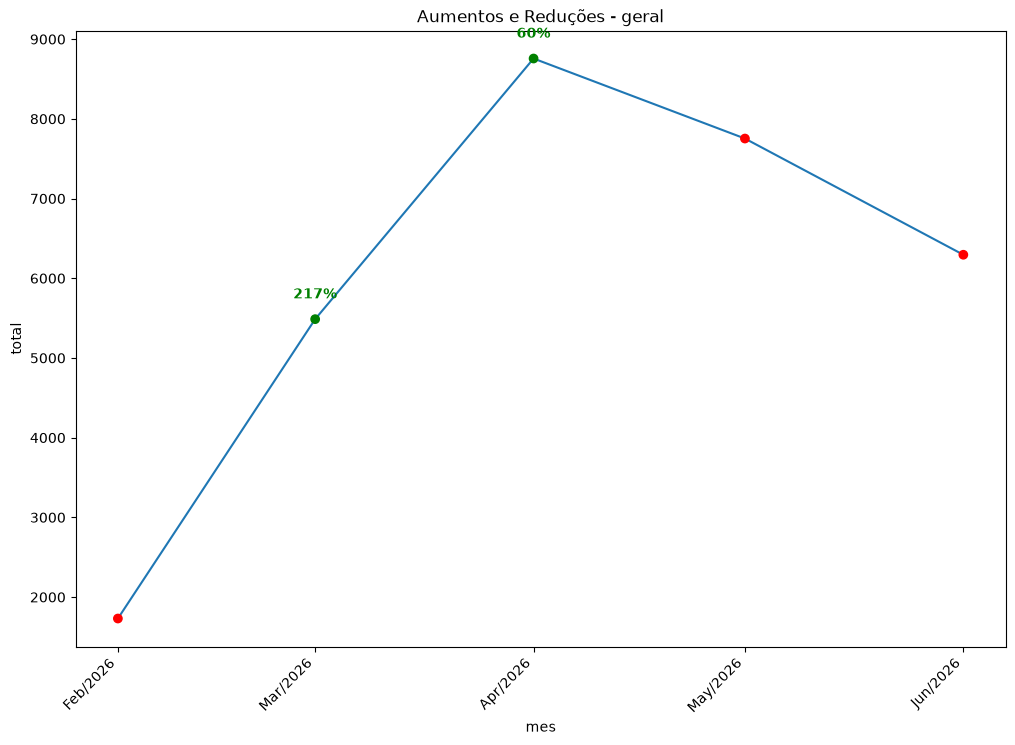

In [30]:
df_mensal = df.groupby('mes').size().reset_index(name='total')
df_mensal['mes'] = df_mensal['mes'].astype(str)
df_mensal['variacao_pct'] = df_mensal['total'].pct_change() * 100
limite = 20  # ex: variação acima de 20% é "relevante"
df_mensal['mes'] = pd.to_datetime(df_mensal['mes'], format="%Y-%m", errors="coerce")

fig = plt.figure(figsize=(12, 8))

diferenca = df_mensal['total'].diff()
cores = np.array(['green' if v > 0 else 'red' for v in diferenca.fillna(0)], dtype=object)

sns.lineplot(data=df_mensal, x='mes', y='total')
plt.scatter(df_mensal['mes'], df_mensal['total'].values, c=cores, zorder=3)
plt.title('Aumentos e Reduções - geral')

for _, row in df_mensal.iterrows():
    if pd.notna(row['variacao_pct']) and abs(row['variacao_pct']) > limite:
        plt.annotate(f"{row['variacao_pct']:.0f}%", 
                        xy=(row['mes'], row['total']), 
                        xytext=(0, 15), textcoords='offset points',
                        ha='center', color='red' if row['variacao_pct'] < 0 else 'green',
                        fontweight='bold')

import matplotlib.dates as mdates

plt.gca().xaxis.set_major_locator(mdates.MonthLocator())  # a cada 3 meses
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b/%Y'))
plt.xticks(rotation=45, ha='right')

Ao observar esse gráfico se pode ter uma ideia de aumento na vacinação no geral, entretanto quando os outros gráficos são mostrados, percebe-se que esse aumento em Abril da-se unicamente pelo aumento na vacinação da influenza para prevenir a gripe. Isso mostra que a maior anormalidade nesse gráfico já é o esperado, afinal no outono as campanhas para prevenir a gripe abrem próximo ao inverno.

No entanto, ao comparar com a população total de Araranguá (77.625 habitantes), percebe-se um número muito baixo de vacinações no geral, e essa porcentagem não aumenta tanto no inicio do inverno, como é o esperado.

Além disso, há um número muito baixo de vacinações cadastradas em Fevereiro, pode ser por dois motivos:
* Por conta das festividades a população deixa de se vacinar ou toma em outra cidade.
* Há um défit no cadastro de vacinações realizadas nesse período.

Text(0.5, 0.98, '')

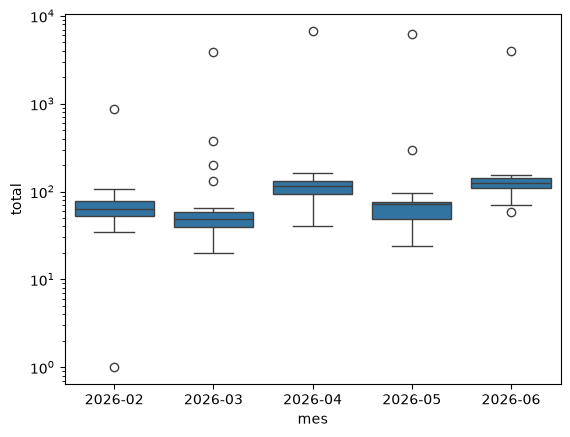

In [31]:
contagem_diaria = df.groupby([df['data_da_aplicacao'].dt.date, 'mes']).size().reset_index(name='total')

# Boxplot: distribuição dos totais diários, agrupado por mês
sns.boxplot(data=contagem_diaria, x='mes', y='total')
plt.yscale('log')
plt.suptitle('')

O gráfico mostra uma consistencia no volume de aplicações realizadas, porém a quantidade varia a cada mês, mas ainda se mantém próxima. As anormalidades que podemos observar no gráfico são os eventos que possuem maior volume de vacinação em março, uma maior quantidade geral em abril, a mediana bem alta no mês de maio que mostra uma constância mais alta e os limites inferiores longos que mostram uma tendência maior a cair o volume de vacinação.

### ANÁLISES POR CATEGORIAS

#### BAIRROS

C:\Users\mirel\AppData\Local\Temp\ipykernel_9556\3013971637.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(labels)


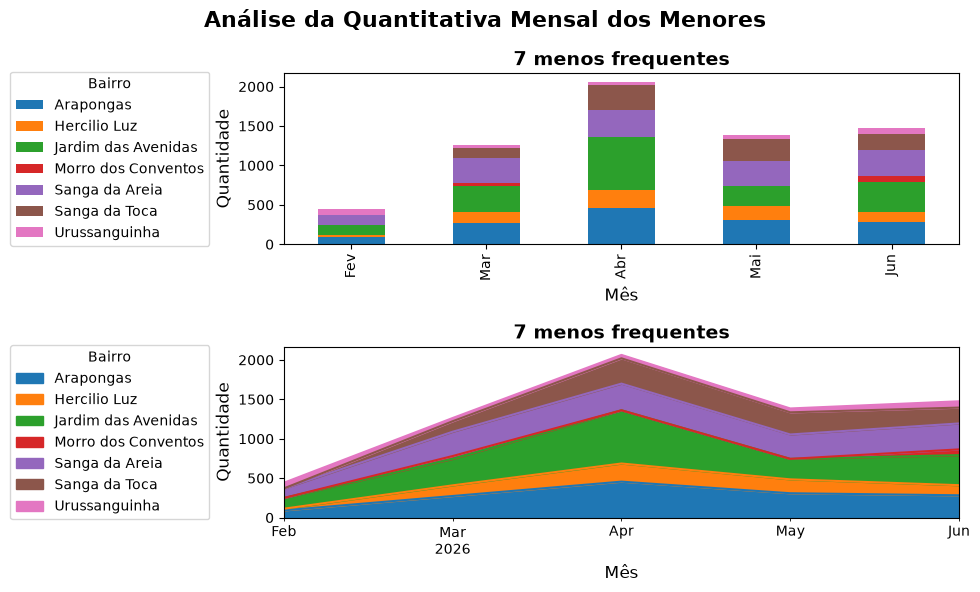

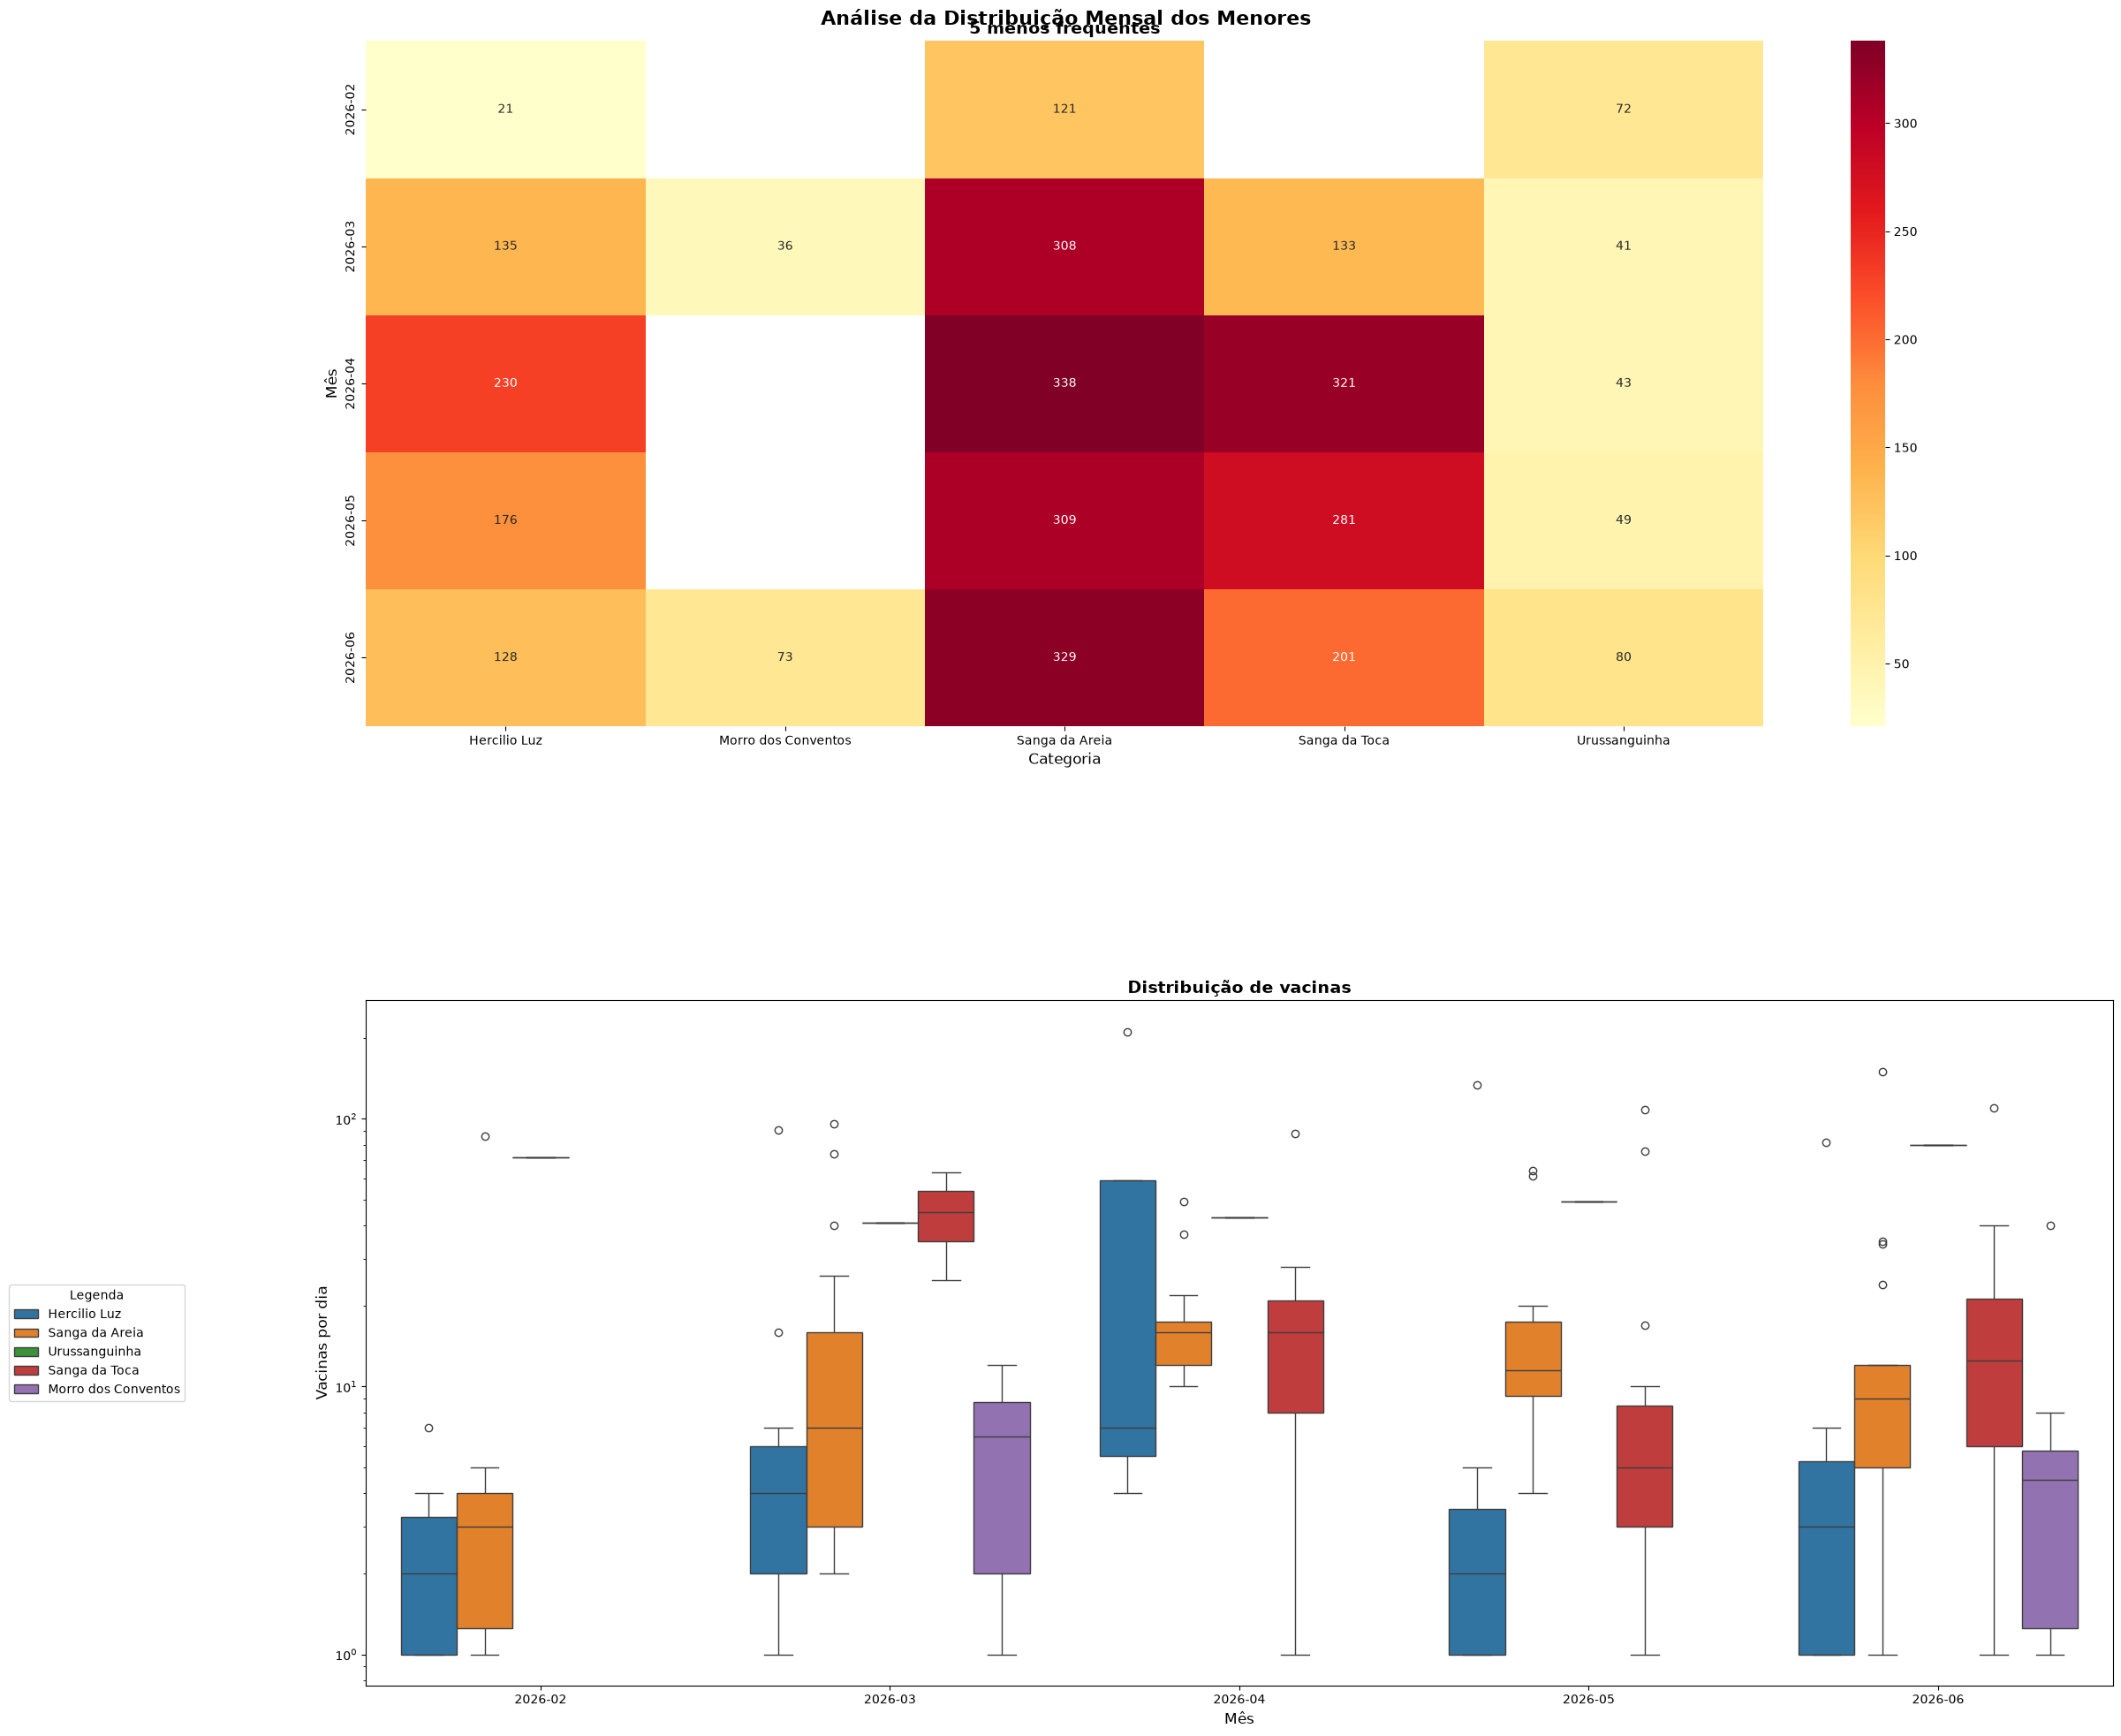

C:\Users\mirel\AppData\Local\Temp\ipykernel_9556\3013971637.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(labels)


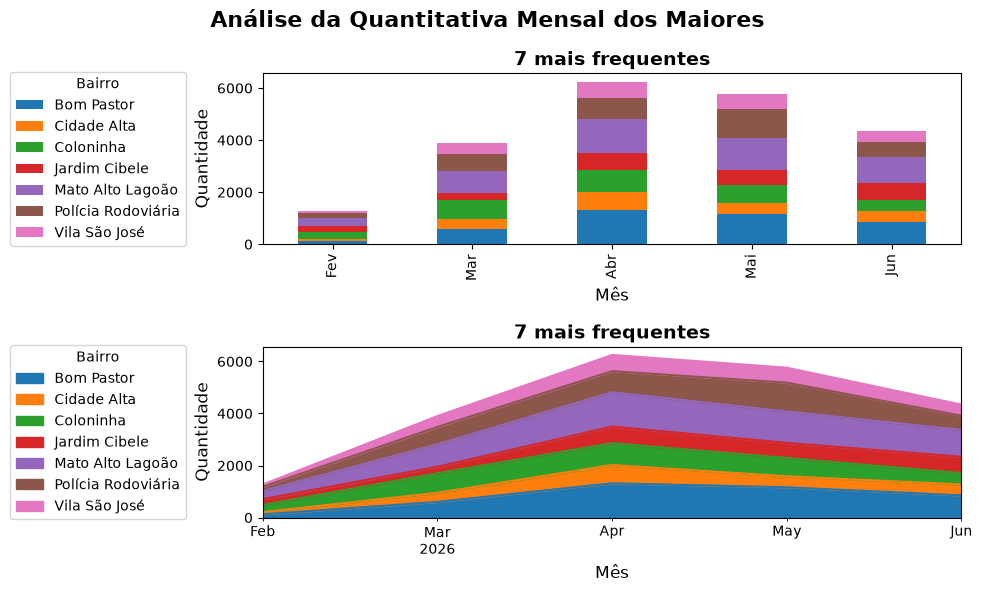

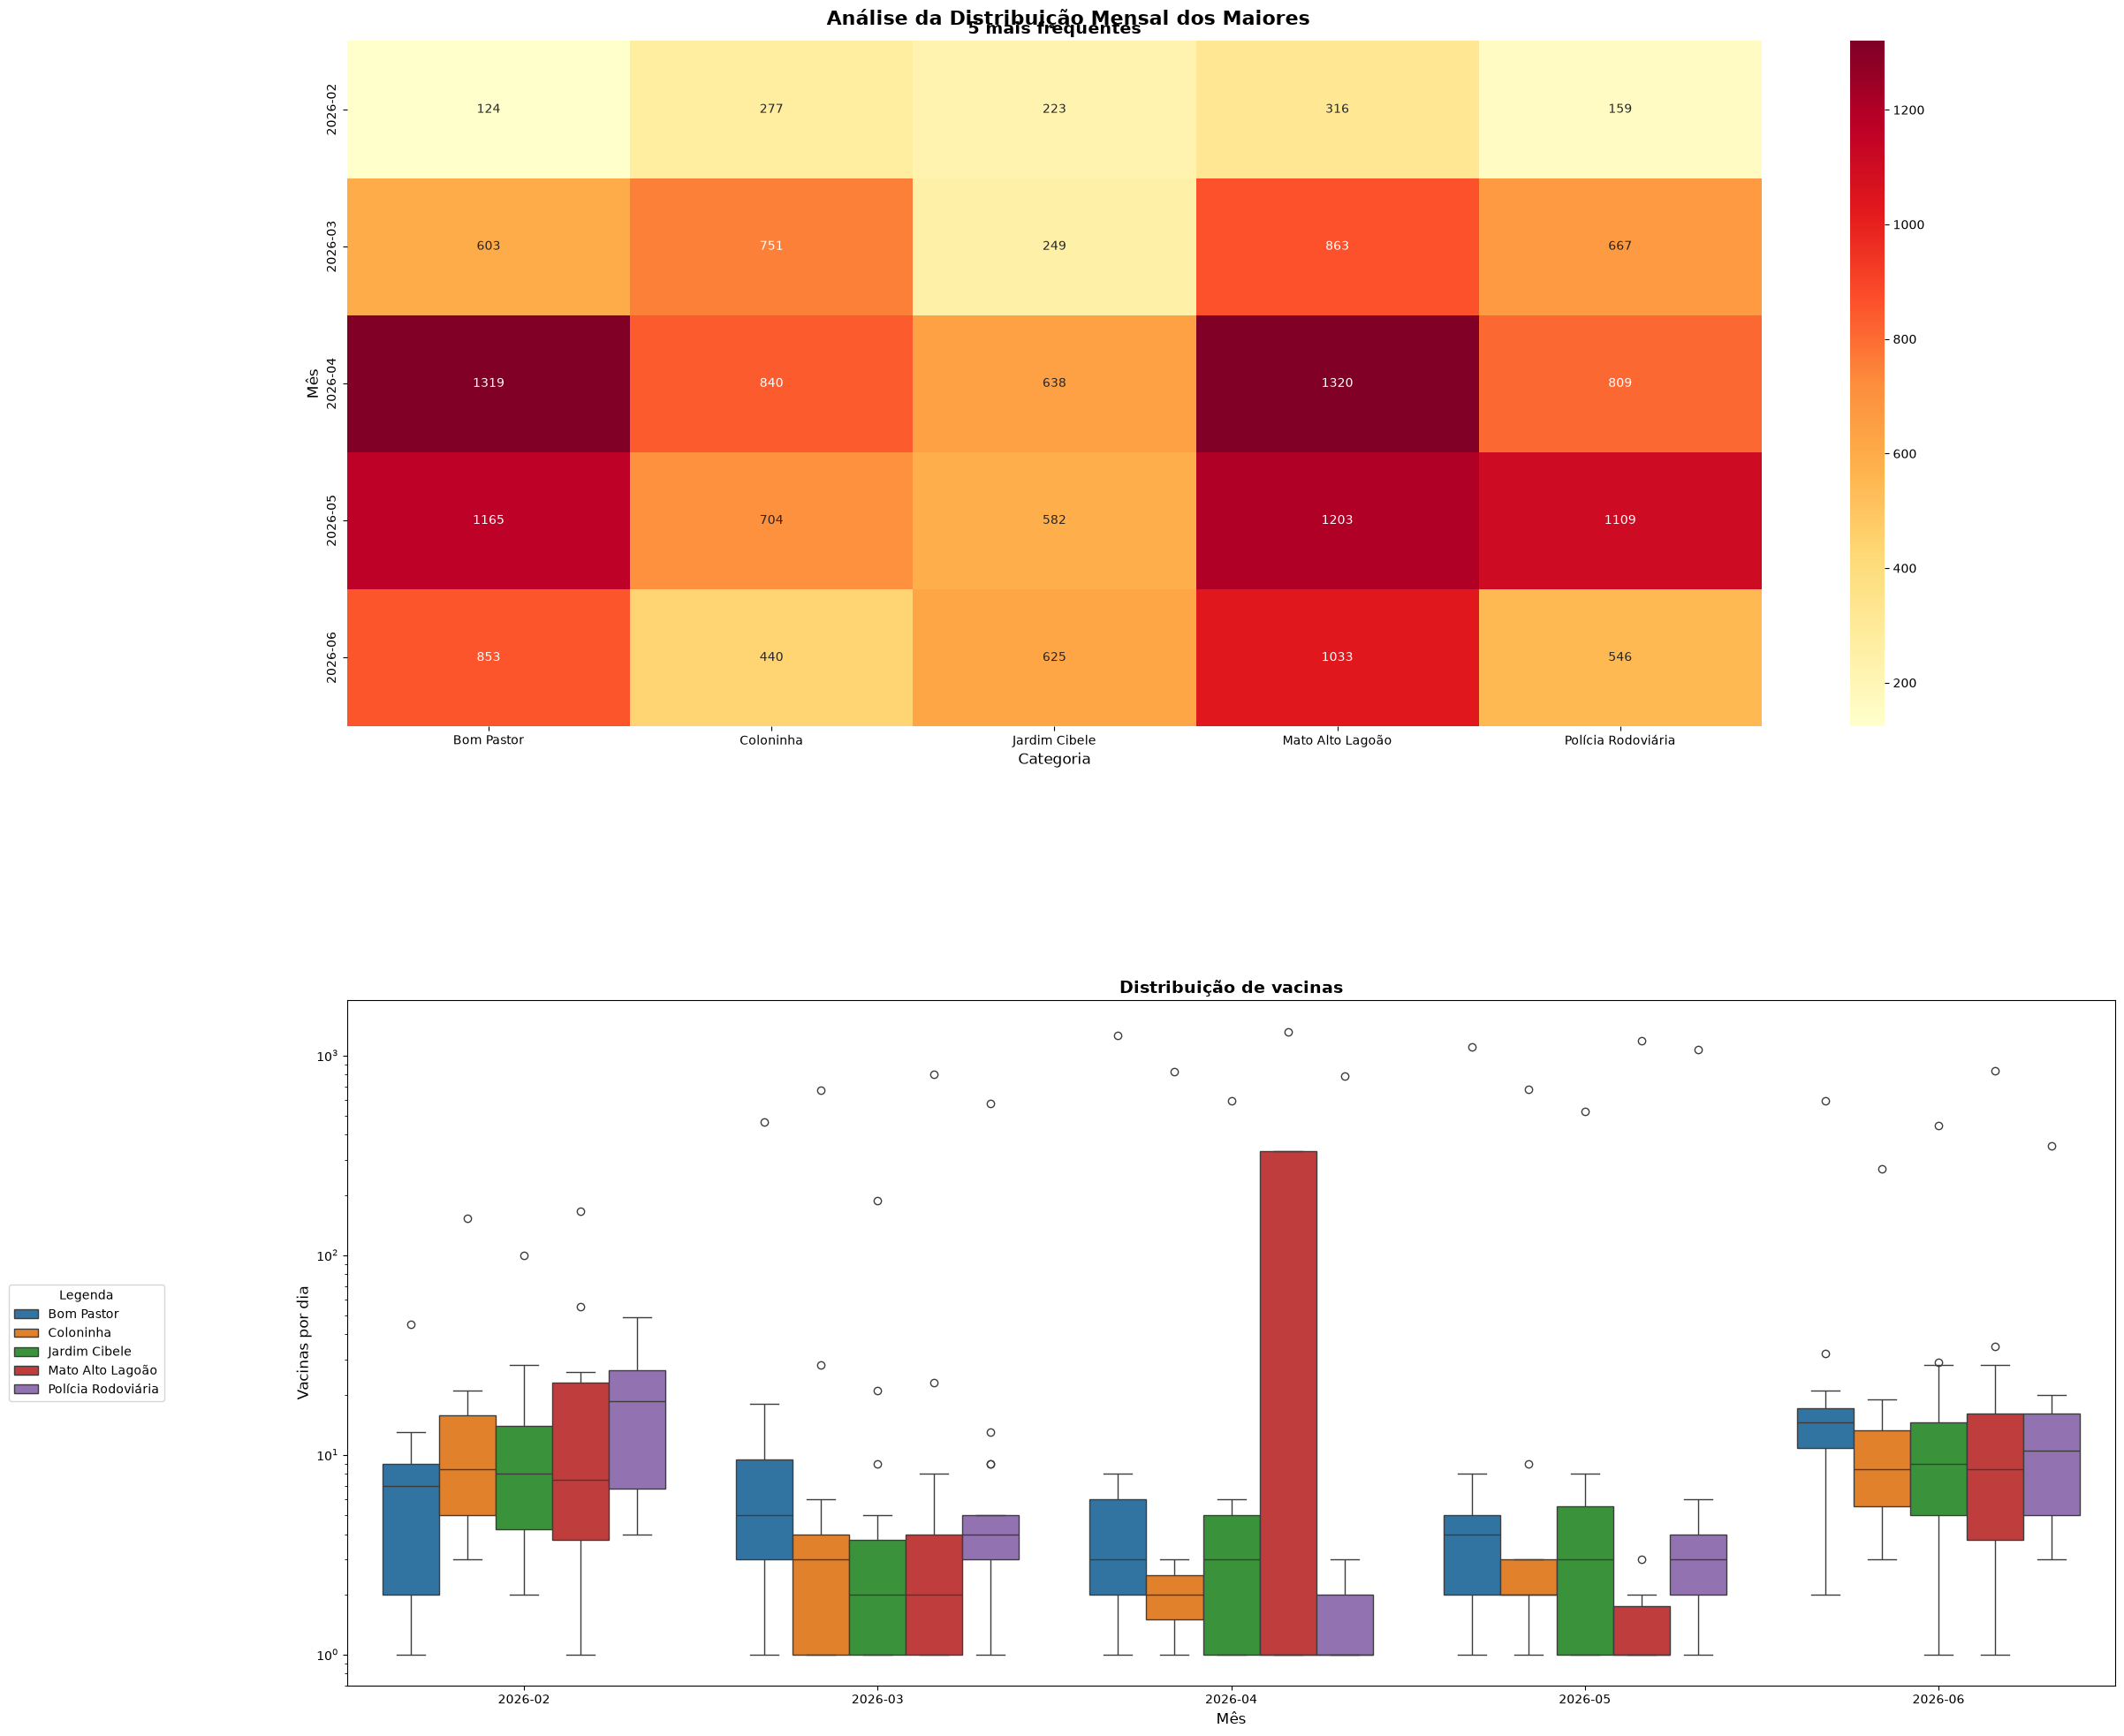

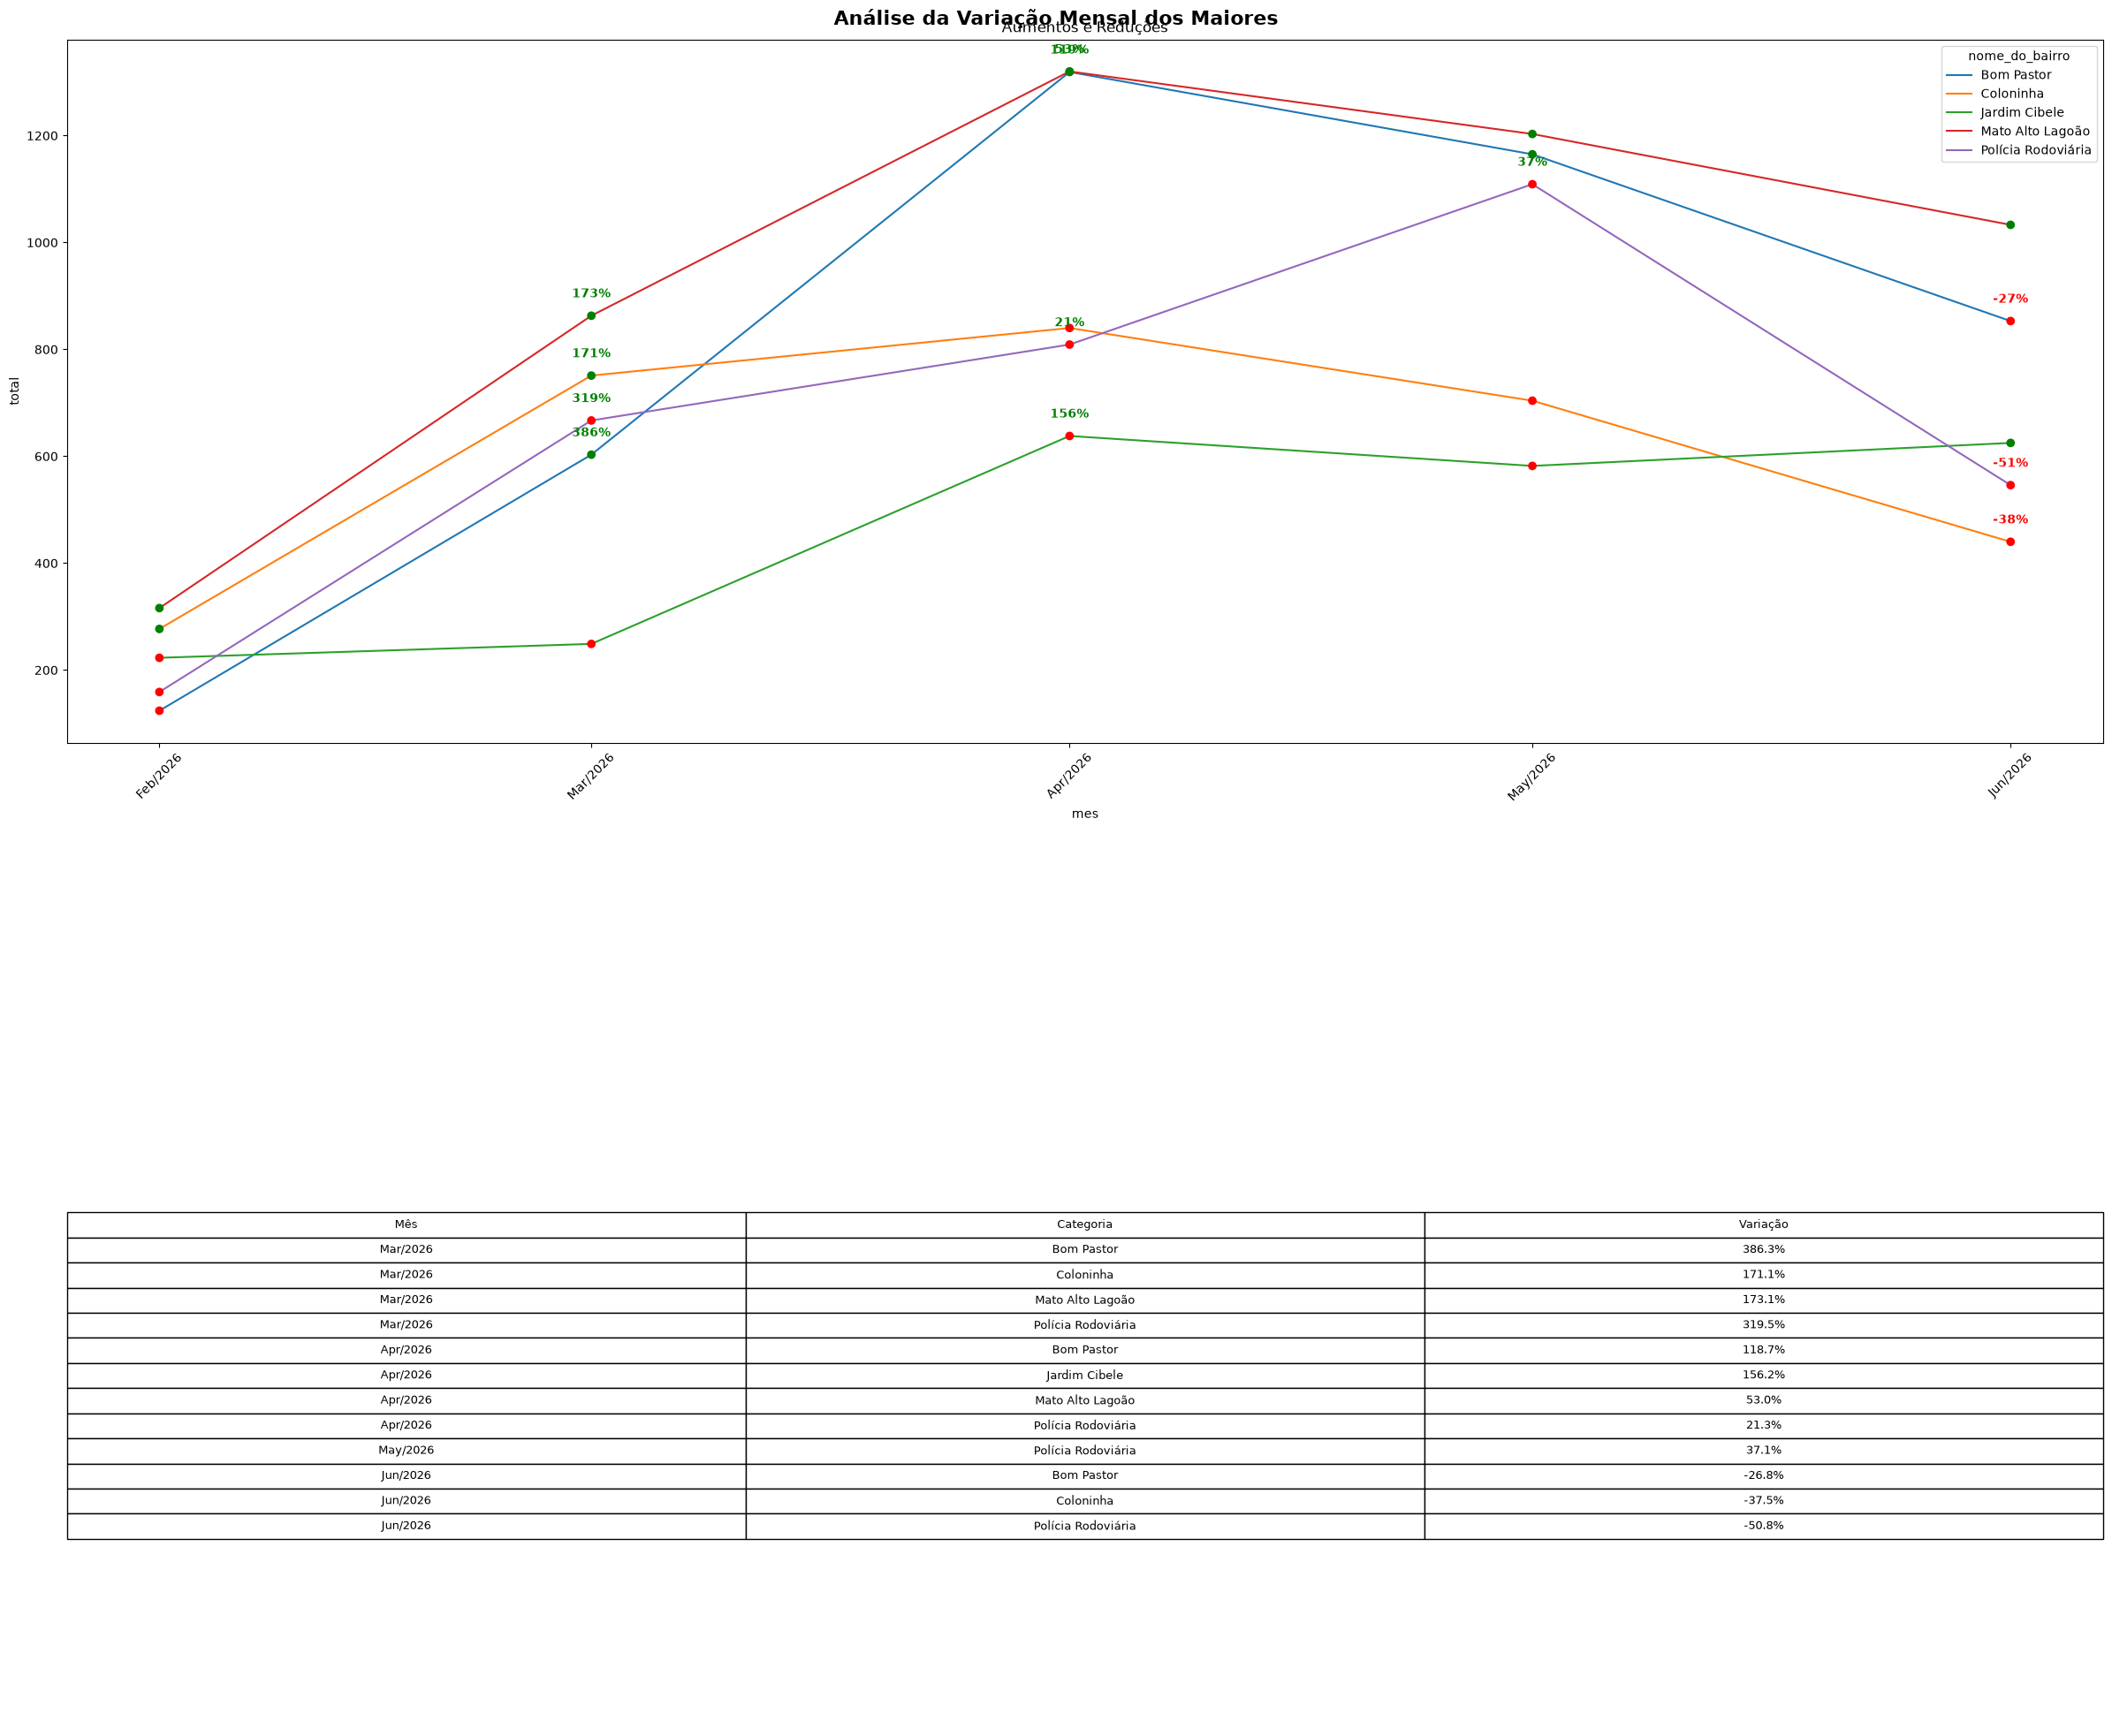

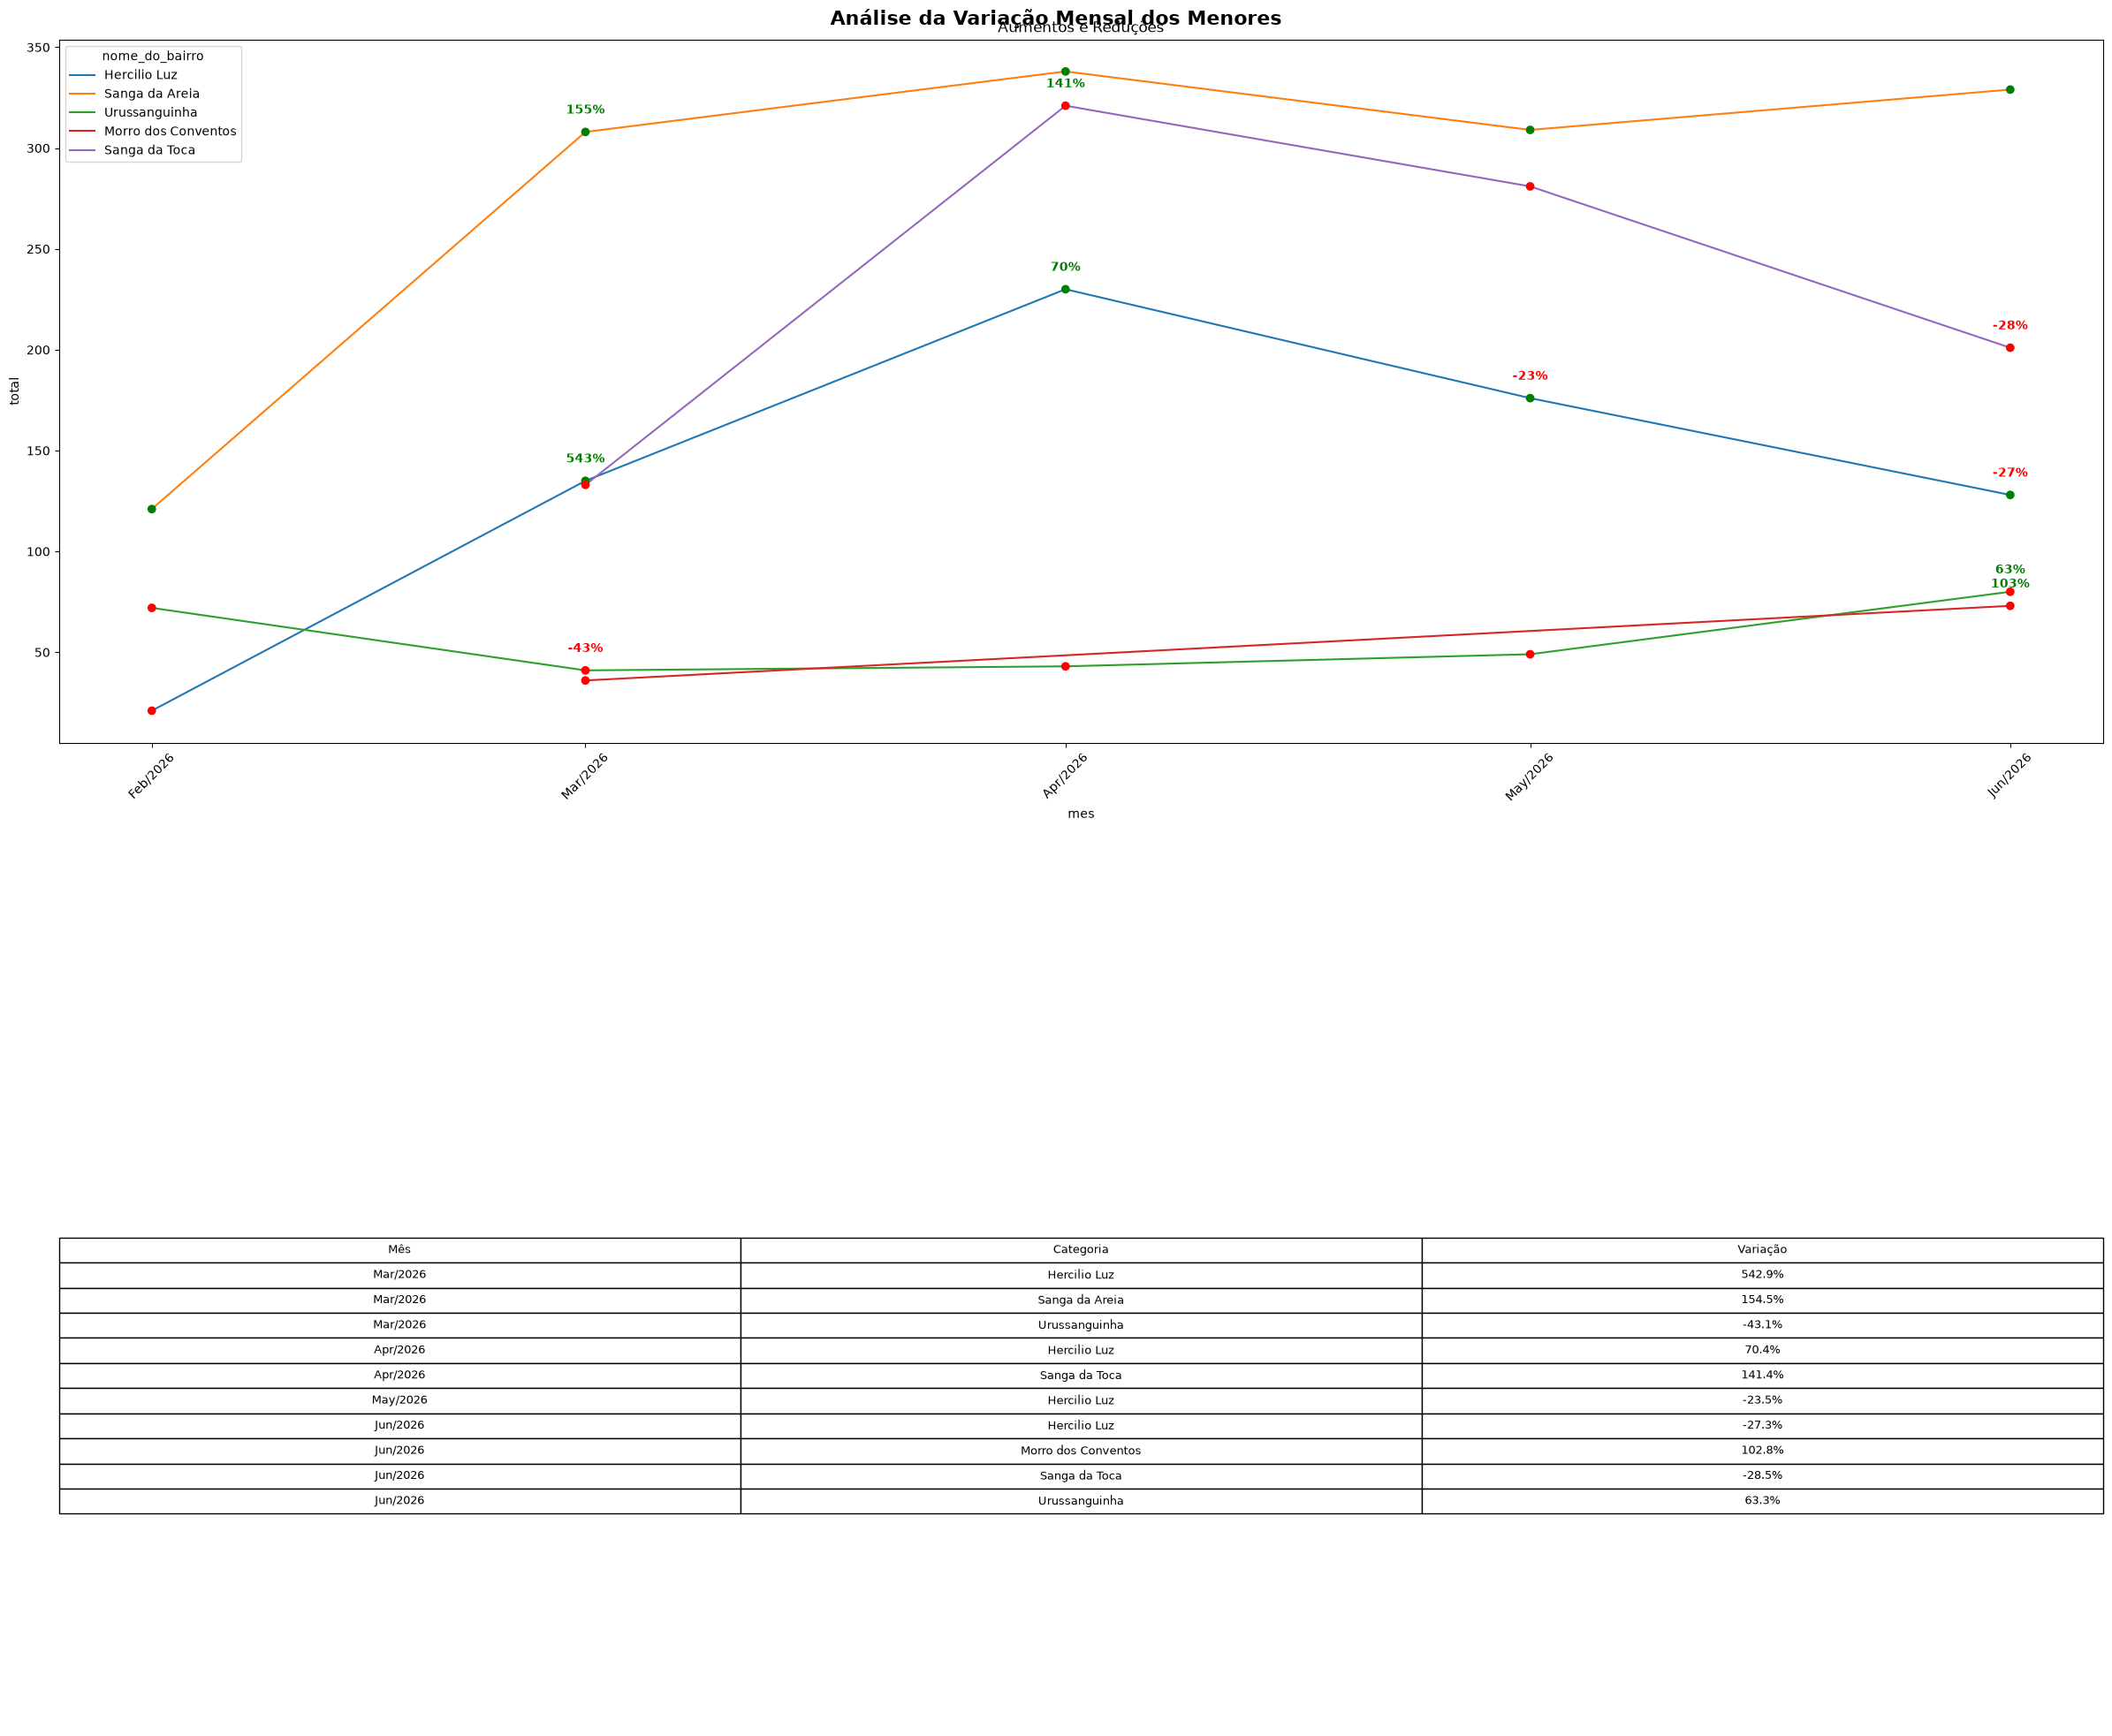

In [32]:
analise_temporal(df, 'nome_do_bairro', 'Bairro', 7)
distribuicao(df, 'nome_do_bairro', hue = '', index = 'mes', legend_title = 'Legenda', top = 5)
analise_temporal(df, 'nome_do_bairro', 'Bairro', 7, False)
distribuicao(df, 'nome_do_bairro', hue = '', index = 'mes', legend_title = 'Legenda', top = 5, ascending=False)
plot_mensal(df, 'nome_do_bairro', ascending=False)
plot_mensal(df, 'nome_do_bairro', ascending=True)

Quando comparamos os bairros com maiores e menores volumes de vacinação se observa uma diferença de 3 a 4 vzs entre eles e uma maior constância nos bairros com maior volume de vacinação. Já olhando mais para os meses os bairros que possuem o maior volume de vacinação no mês de abril (o mês que teve um aumento relevante) foram Mato Alto Lagoão e Bom Pastor. Além disso observa-se uma grande tendência em eventos de aumentos entre todos os bairros apresentados. Os bairros com menor volume de vacinação mostram uma diminuição no mês de maio e tendências a não ter cadastro de vacinação.

Tópicos:
* 3 a 4 vzs a diferença entre os bairros com maiores e menores volumes de vacinação
* Mato Alto Lagoão e Bom Pastor puxam o gráfico para cima em abril e Jardim Cibele também tem um aumento considerável


### VACINAS

C:\Users\mirel\AppData\Local\Temp\ipykernel_9556\3013971637.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(labels)


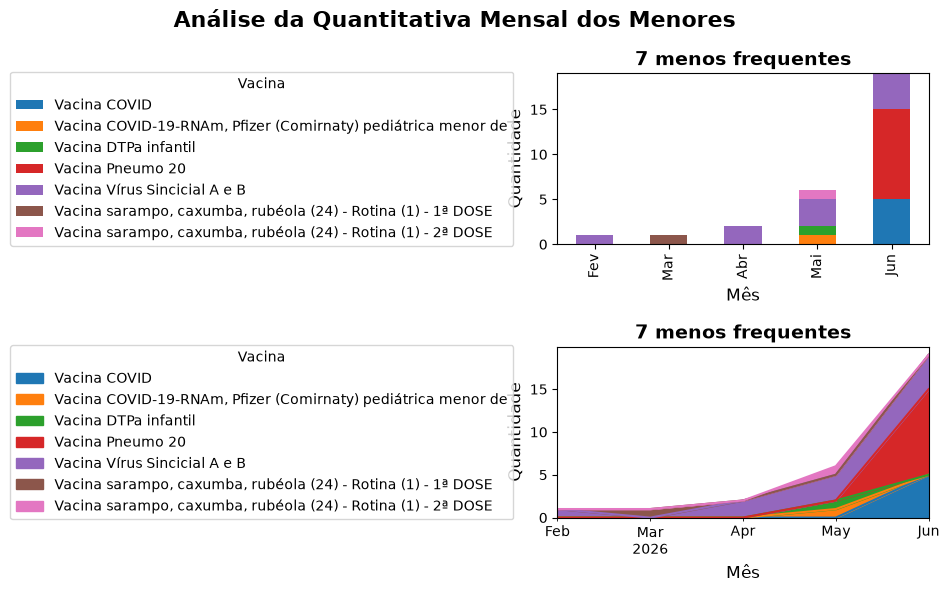

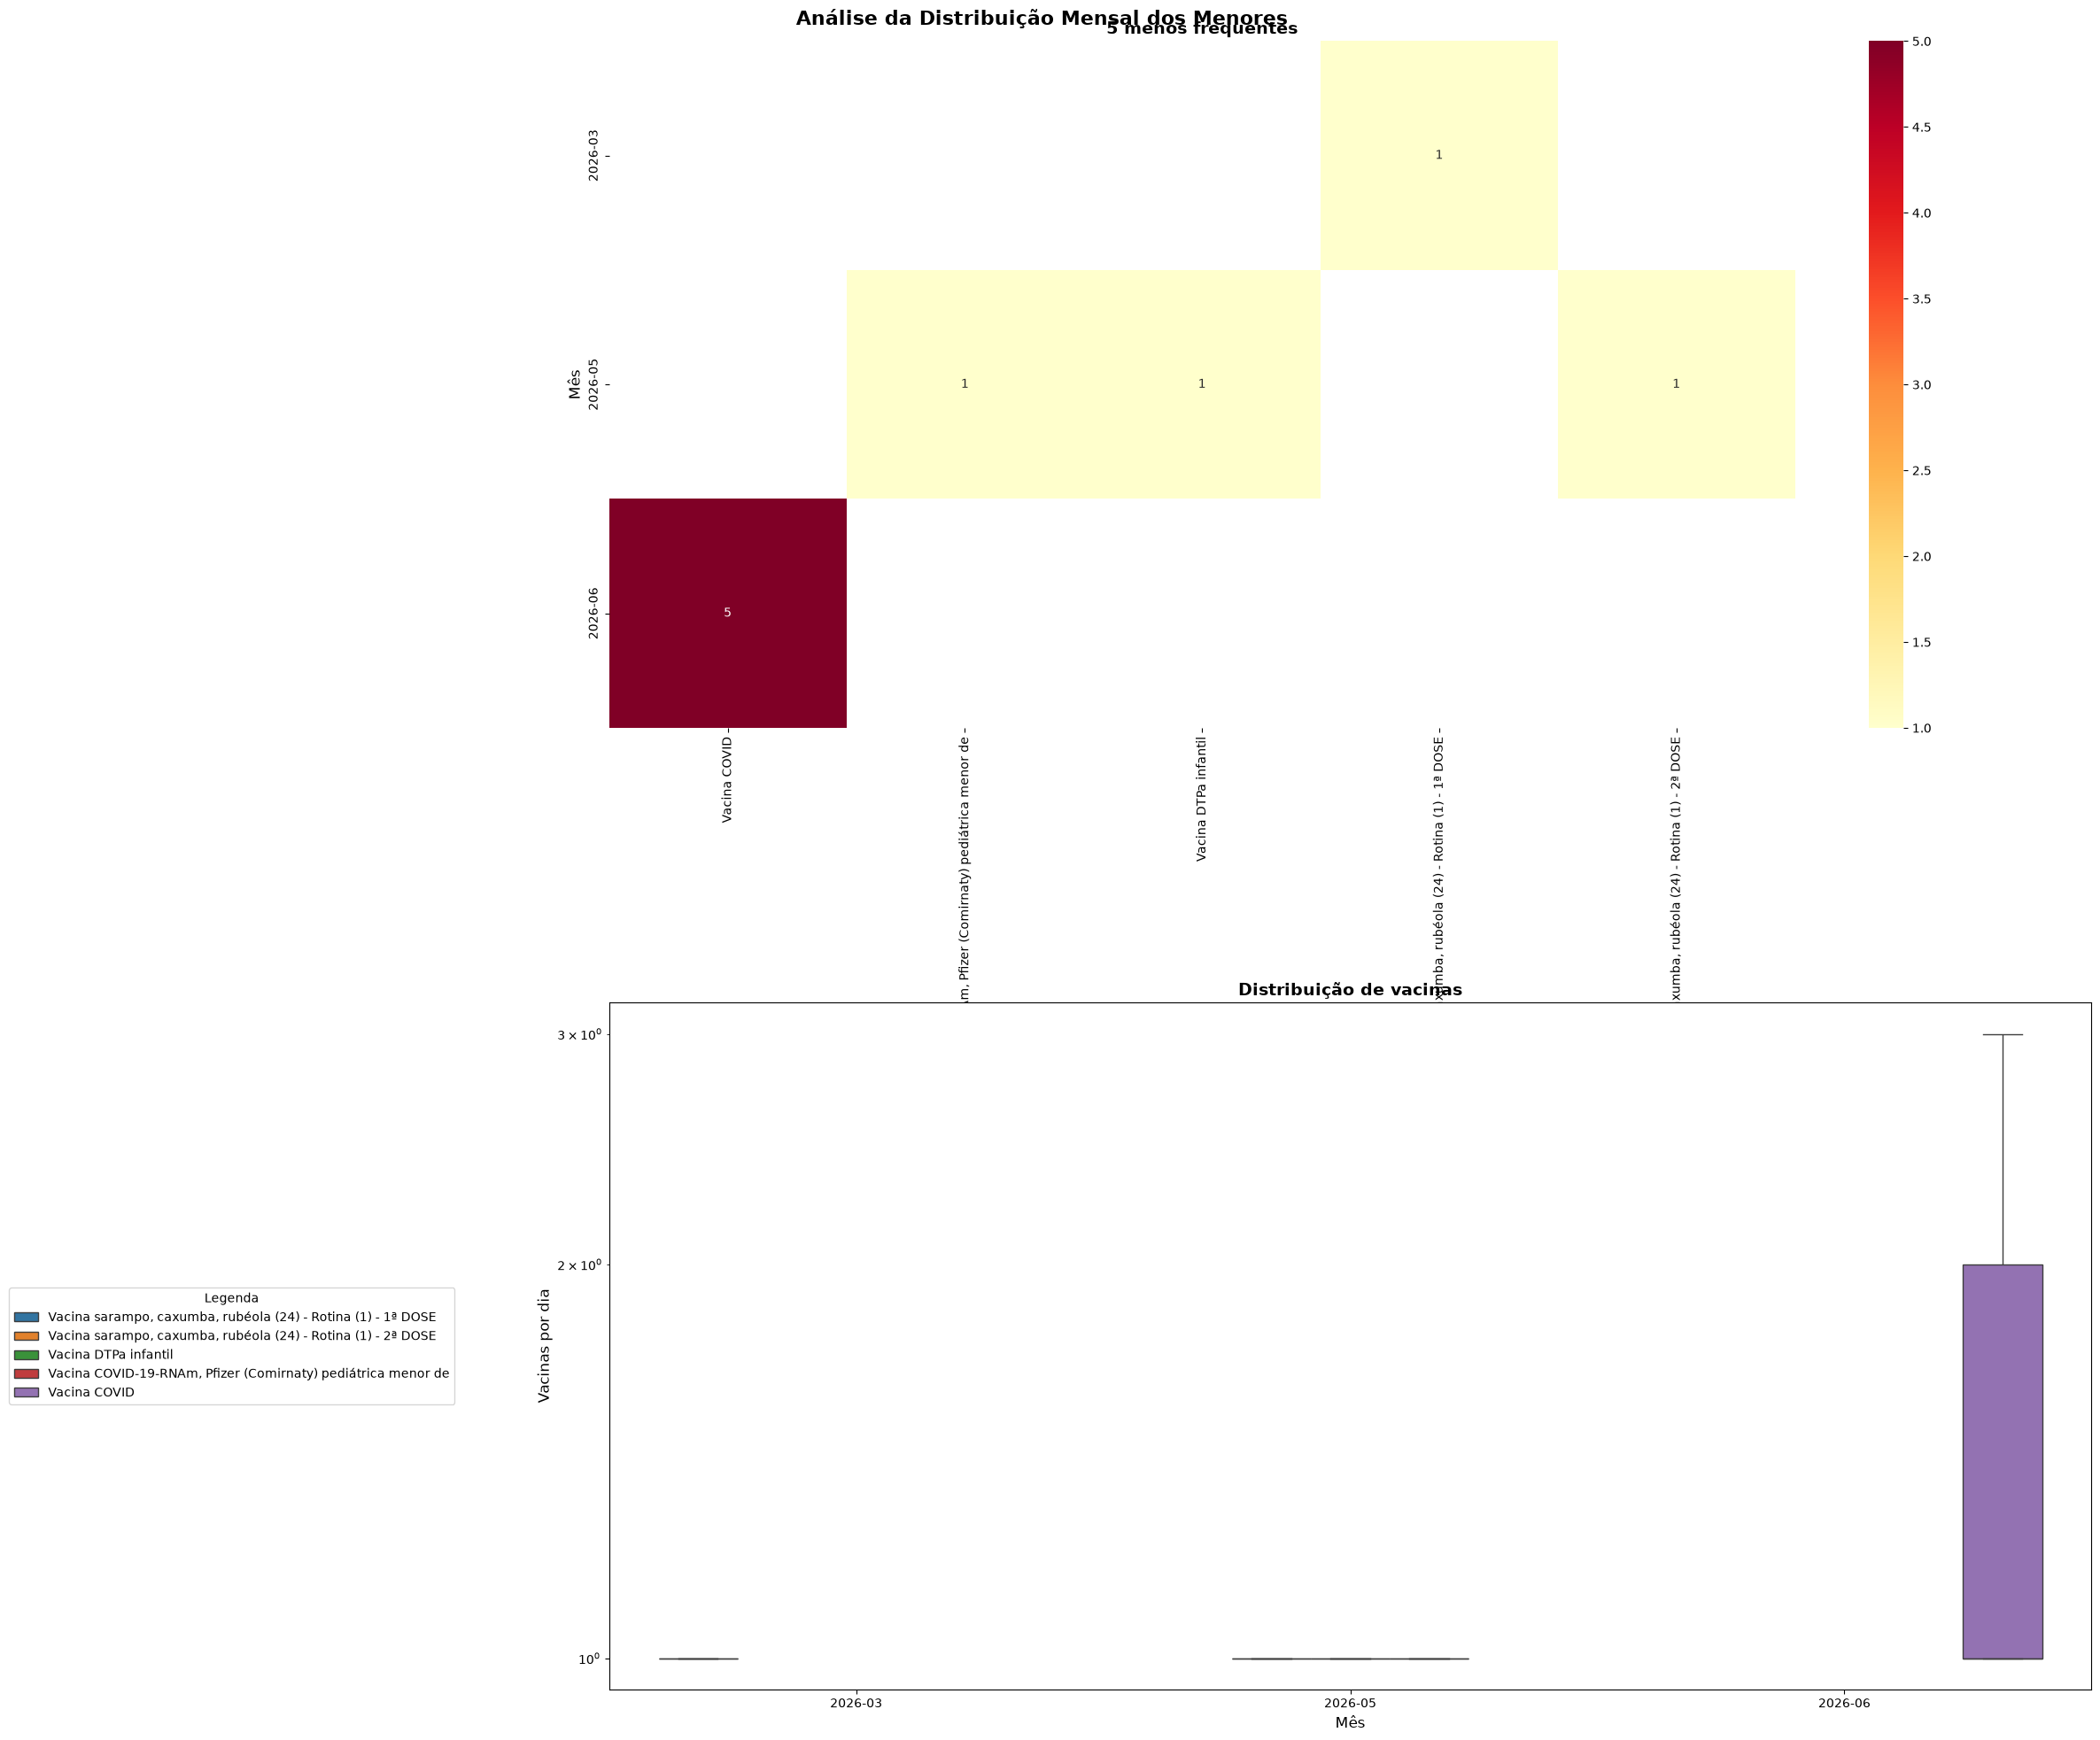

C:\Users\mirel\AppData\Local\Temp\ipykernel_9556\3013971637.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(labels)


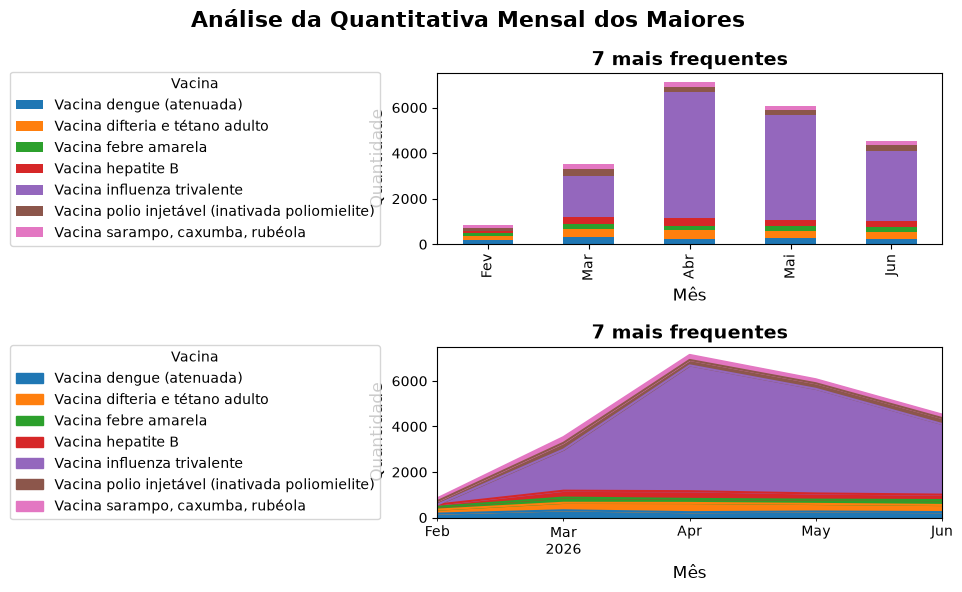

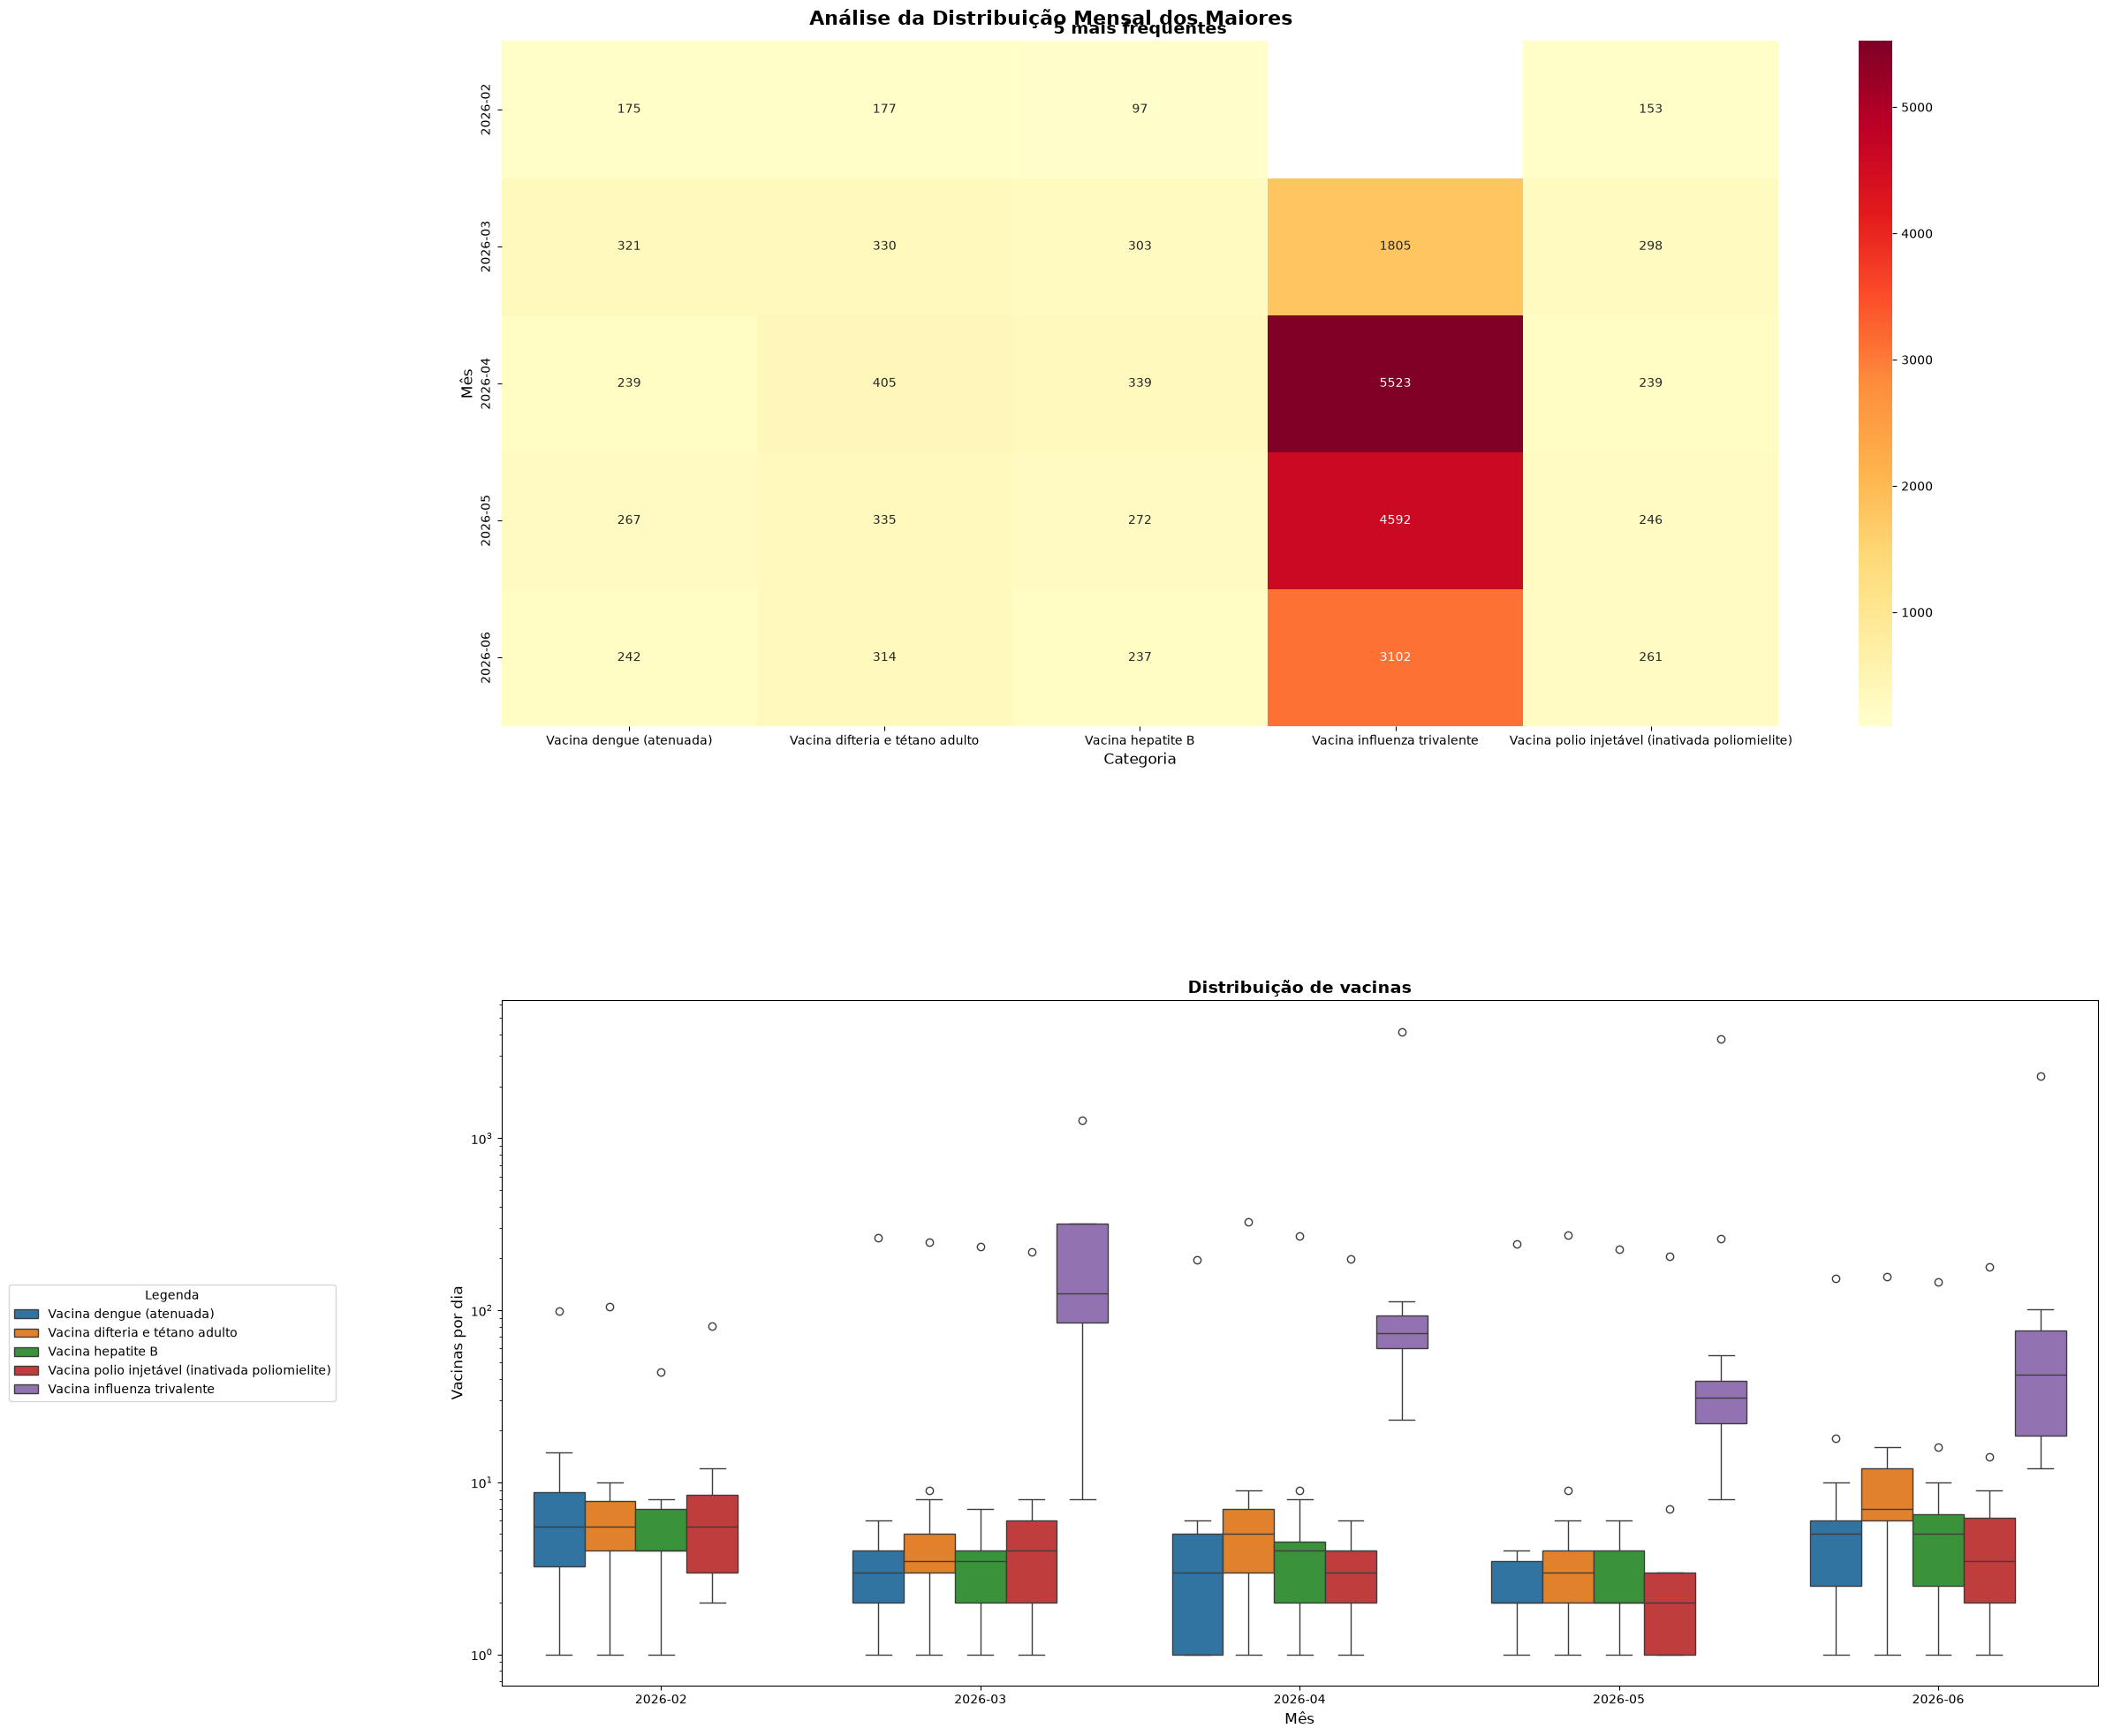

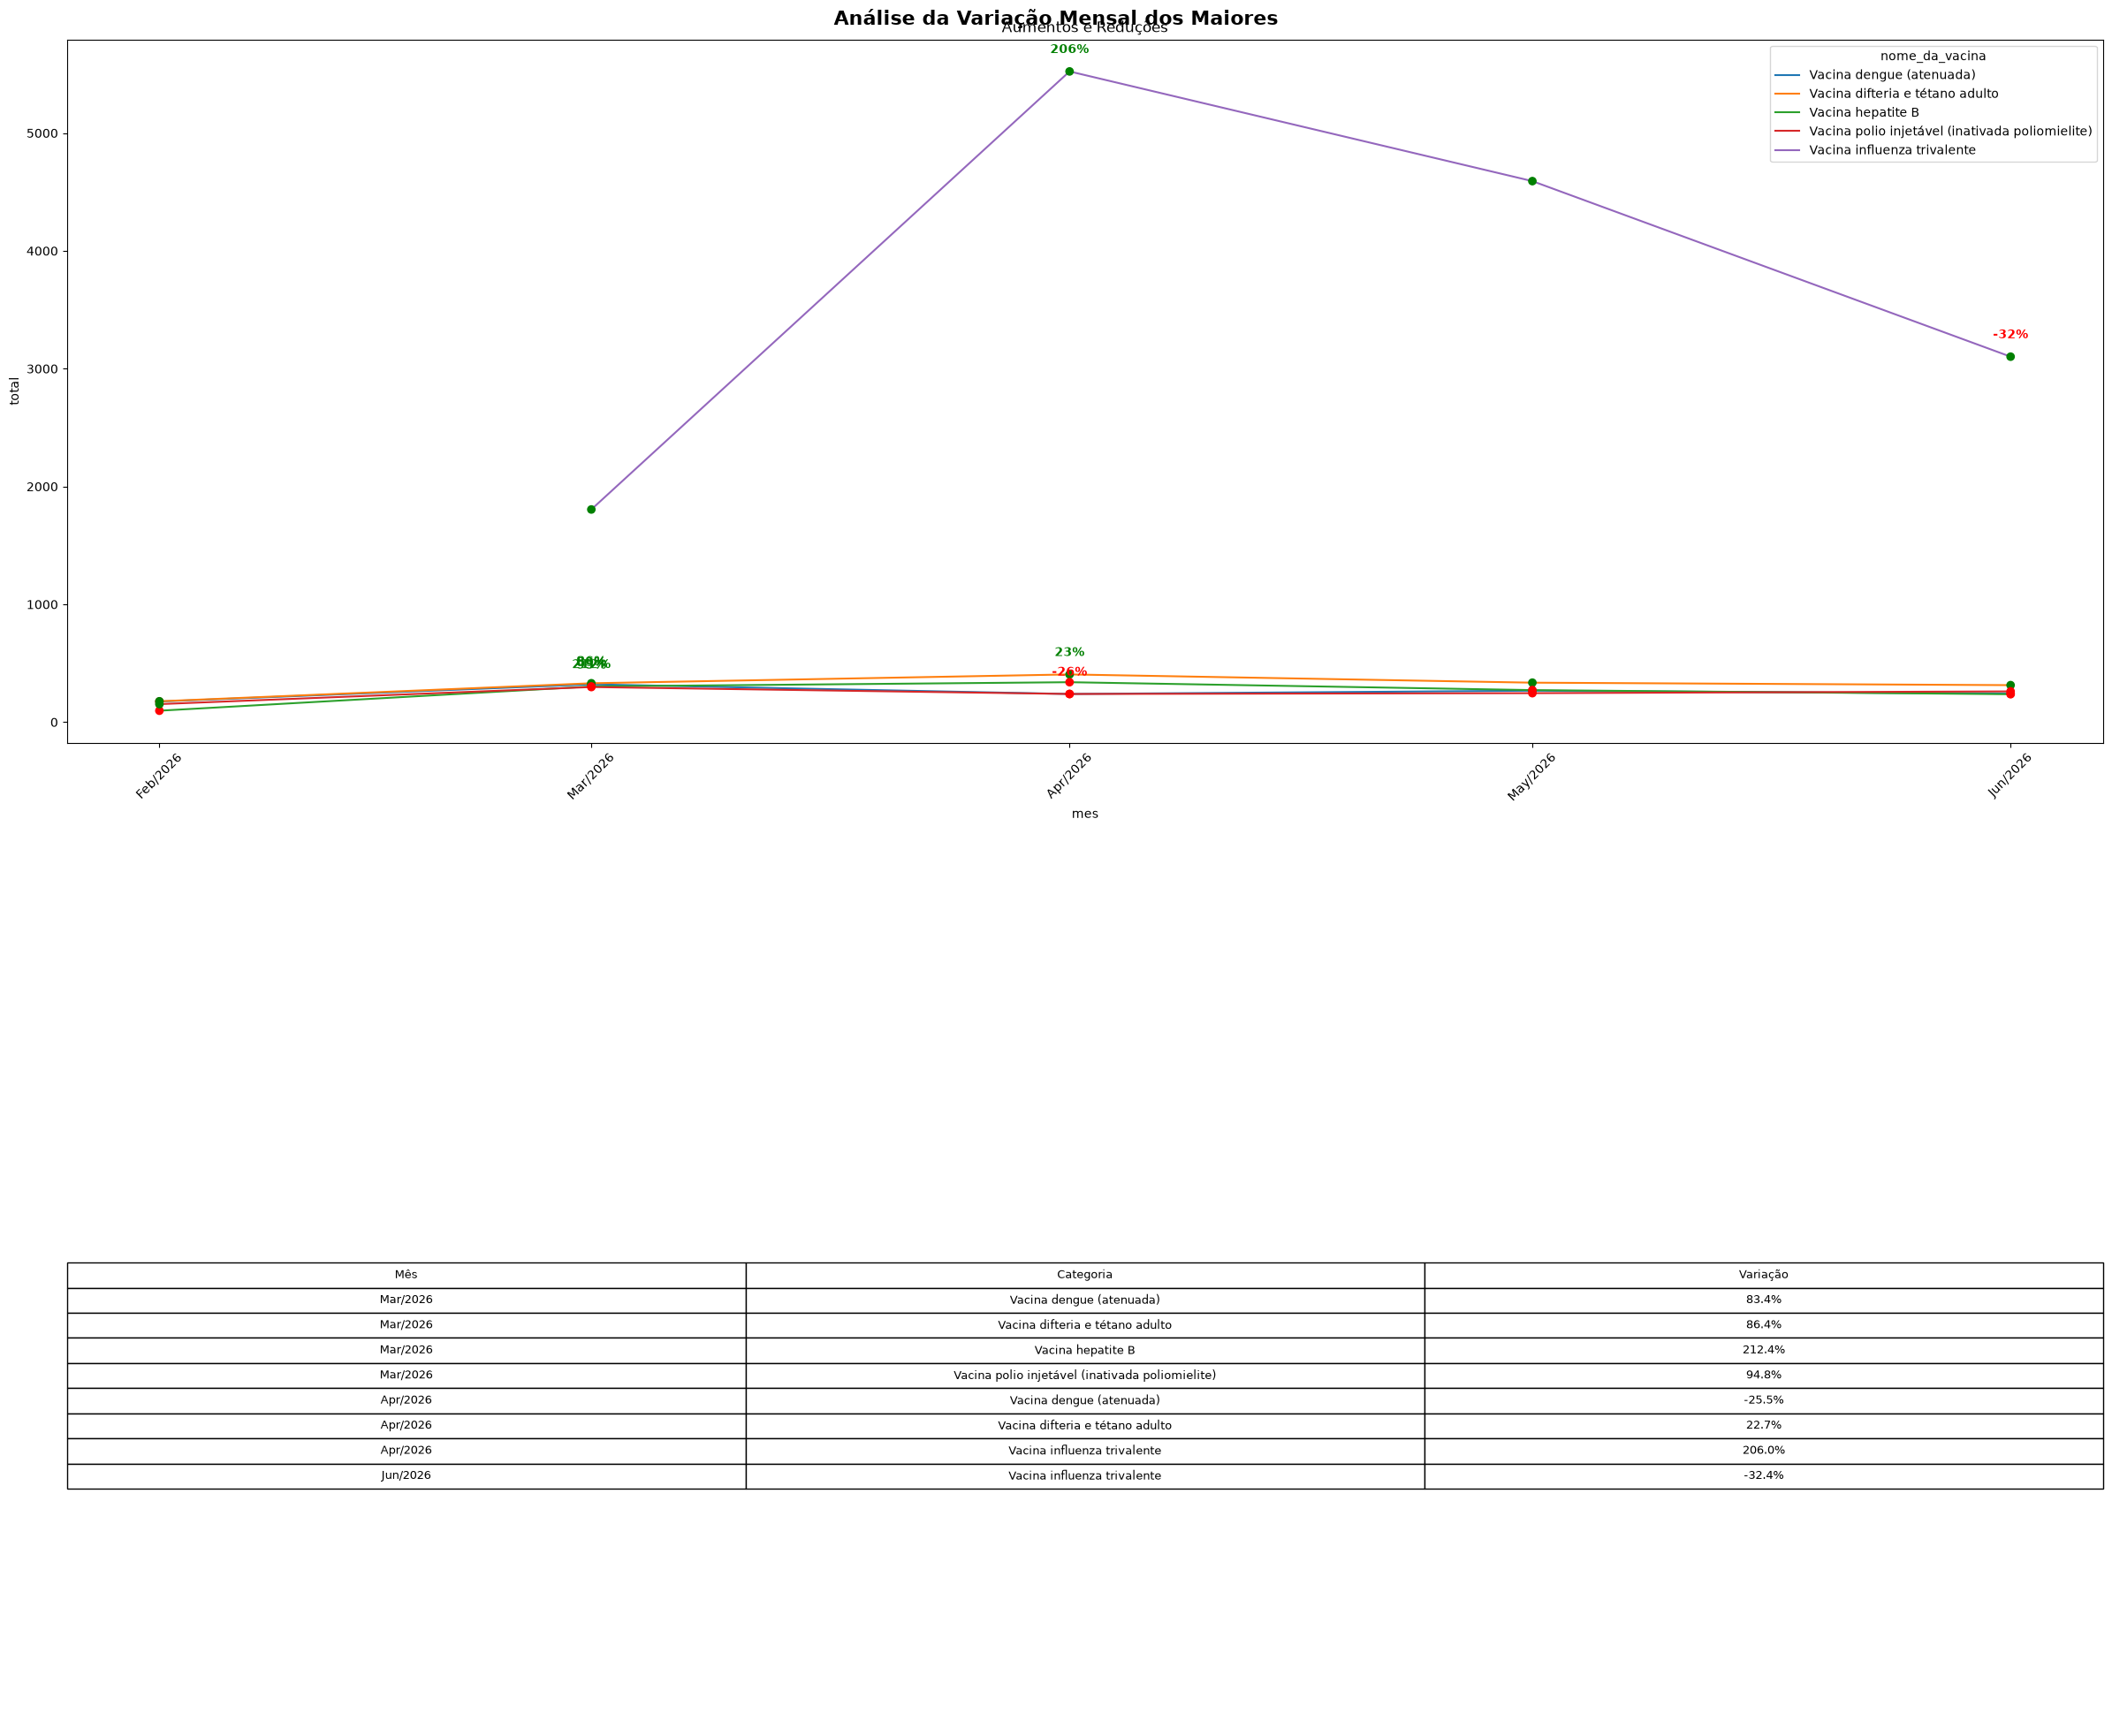

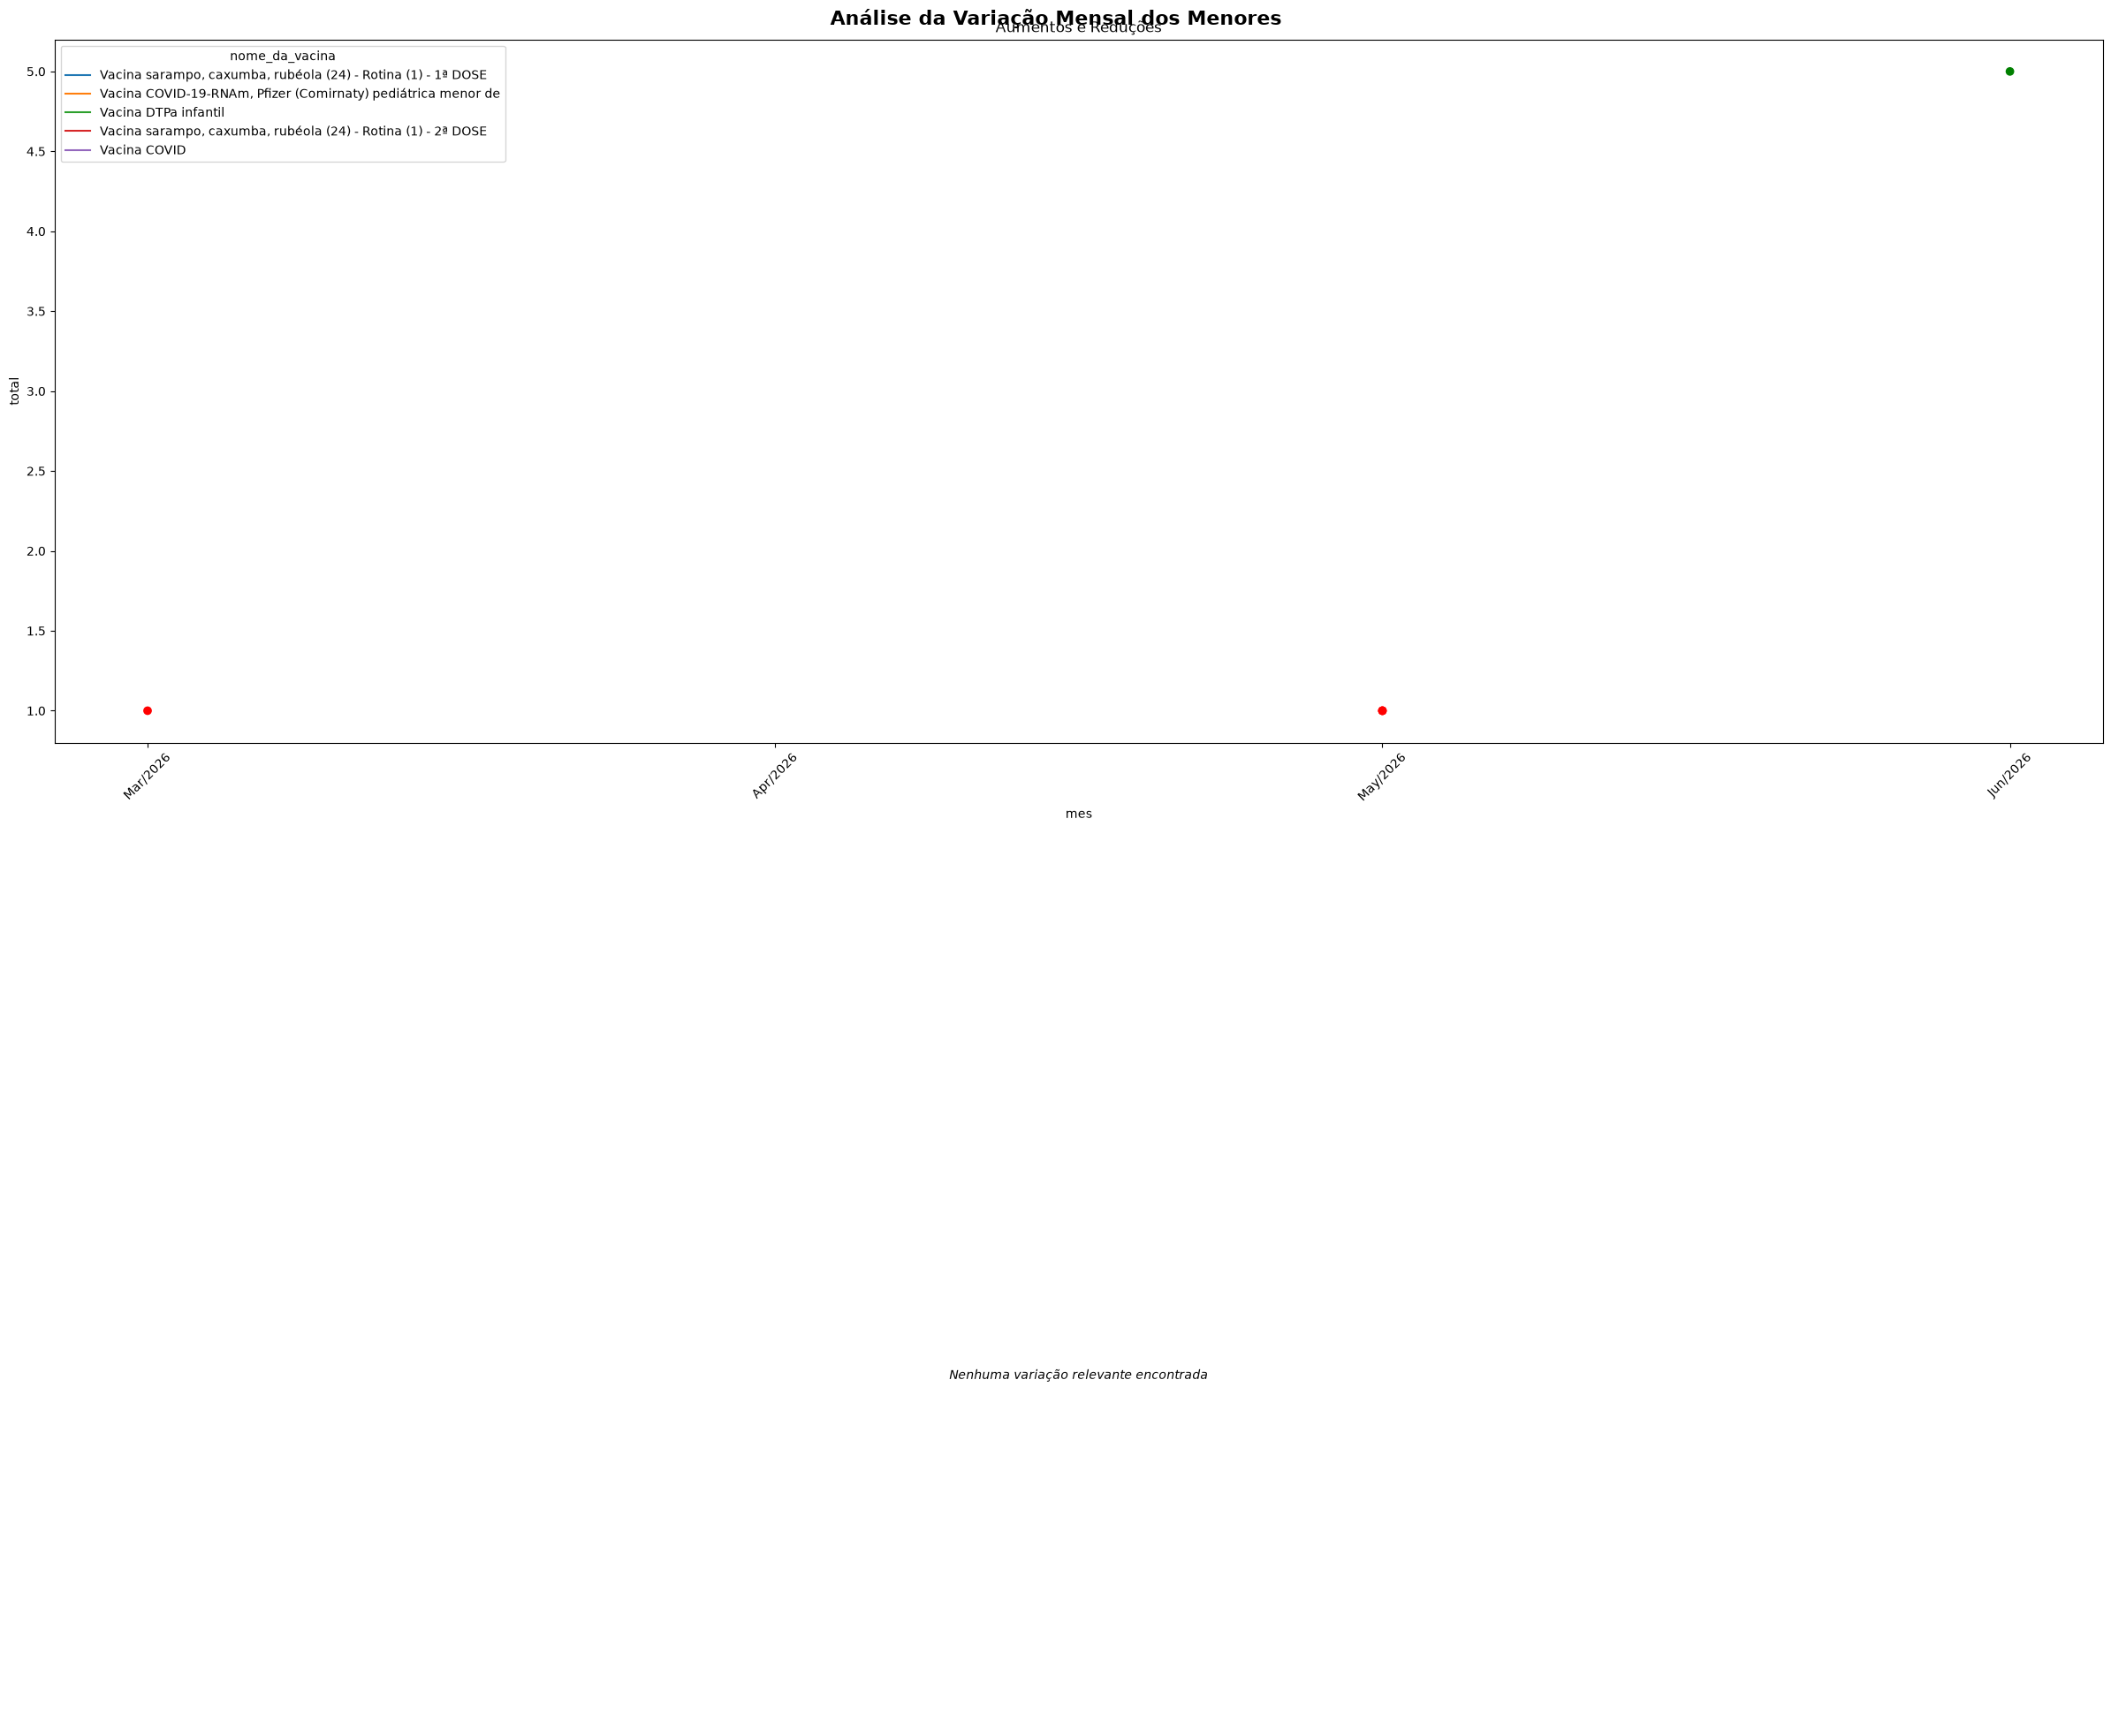

In [33]:
analise_temporal(df, 'nome_da_vacina', 'Vacina', 7)
distribuicao(df, 'nome_da_vacina', hue = '', index = 'mes', legend_title = 'Legenda', top = 5)
analise_temporal(df, 'nome_da_vacina', 'Vacina', 7, False)
distribuicao(df, 'nome_da_vacina', hue = '', index = 'mes', legend_title = 'Legenda', top = 5, ascending=False)
plot_mensal(df, 'nome_da_vacina', ascending=False)
plot_mensal(df, 'nome_da_vacina', ascending=True)

Pontos a observar:
* Vacinas infantis estão entre as que possuem menor volume de vacinação (como não há dados, não há como analisar corretamente)
* A vacina que tem a maior quantidade é a Influenza Trivalente (da gripe) que não possue dados em fevereiro, porém com o início do outono as campanhas começam e a vacinação também.
* As outras vacinas possuem um comportamente constante ao longo do período analisado. Porém, entre as maiores, as vacinas com compotamento mais inconstantes são a da dengue e da polio injetável.

### ESTRATÉGIA APLICADA

C:\Users\mirel\AppData\Local\Temp\ipykernel_9556\3013971637.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(labels)


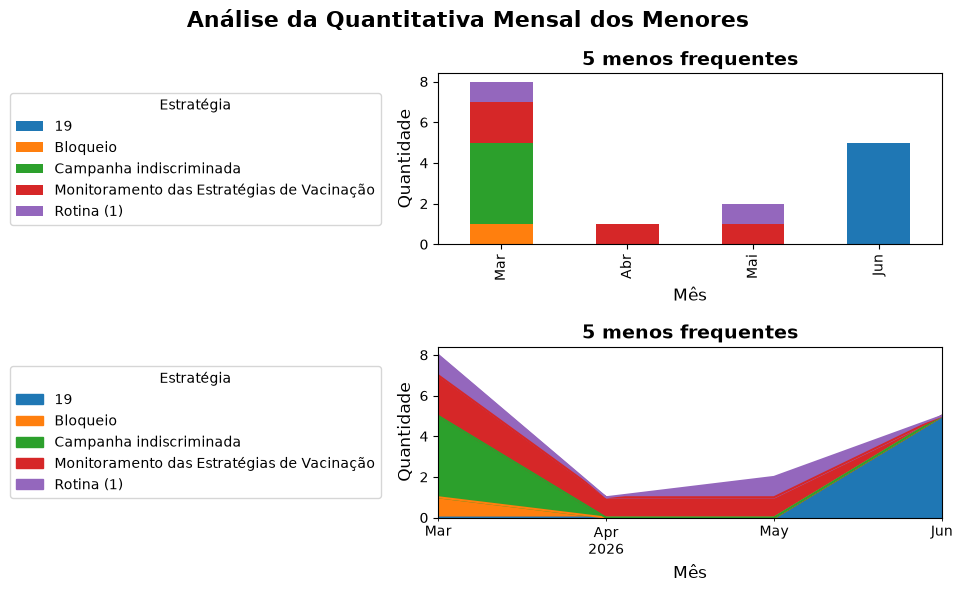

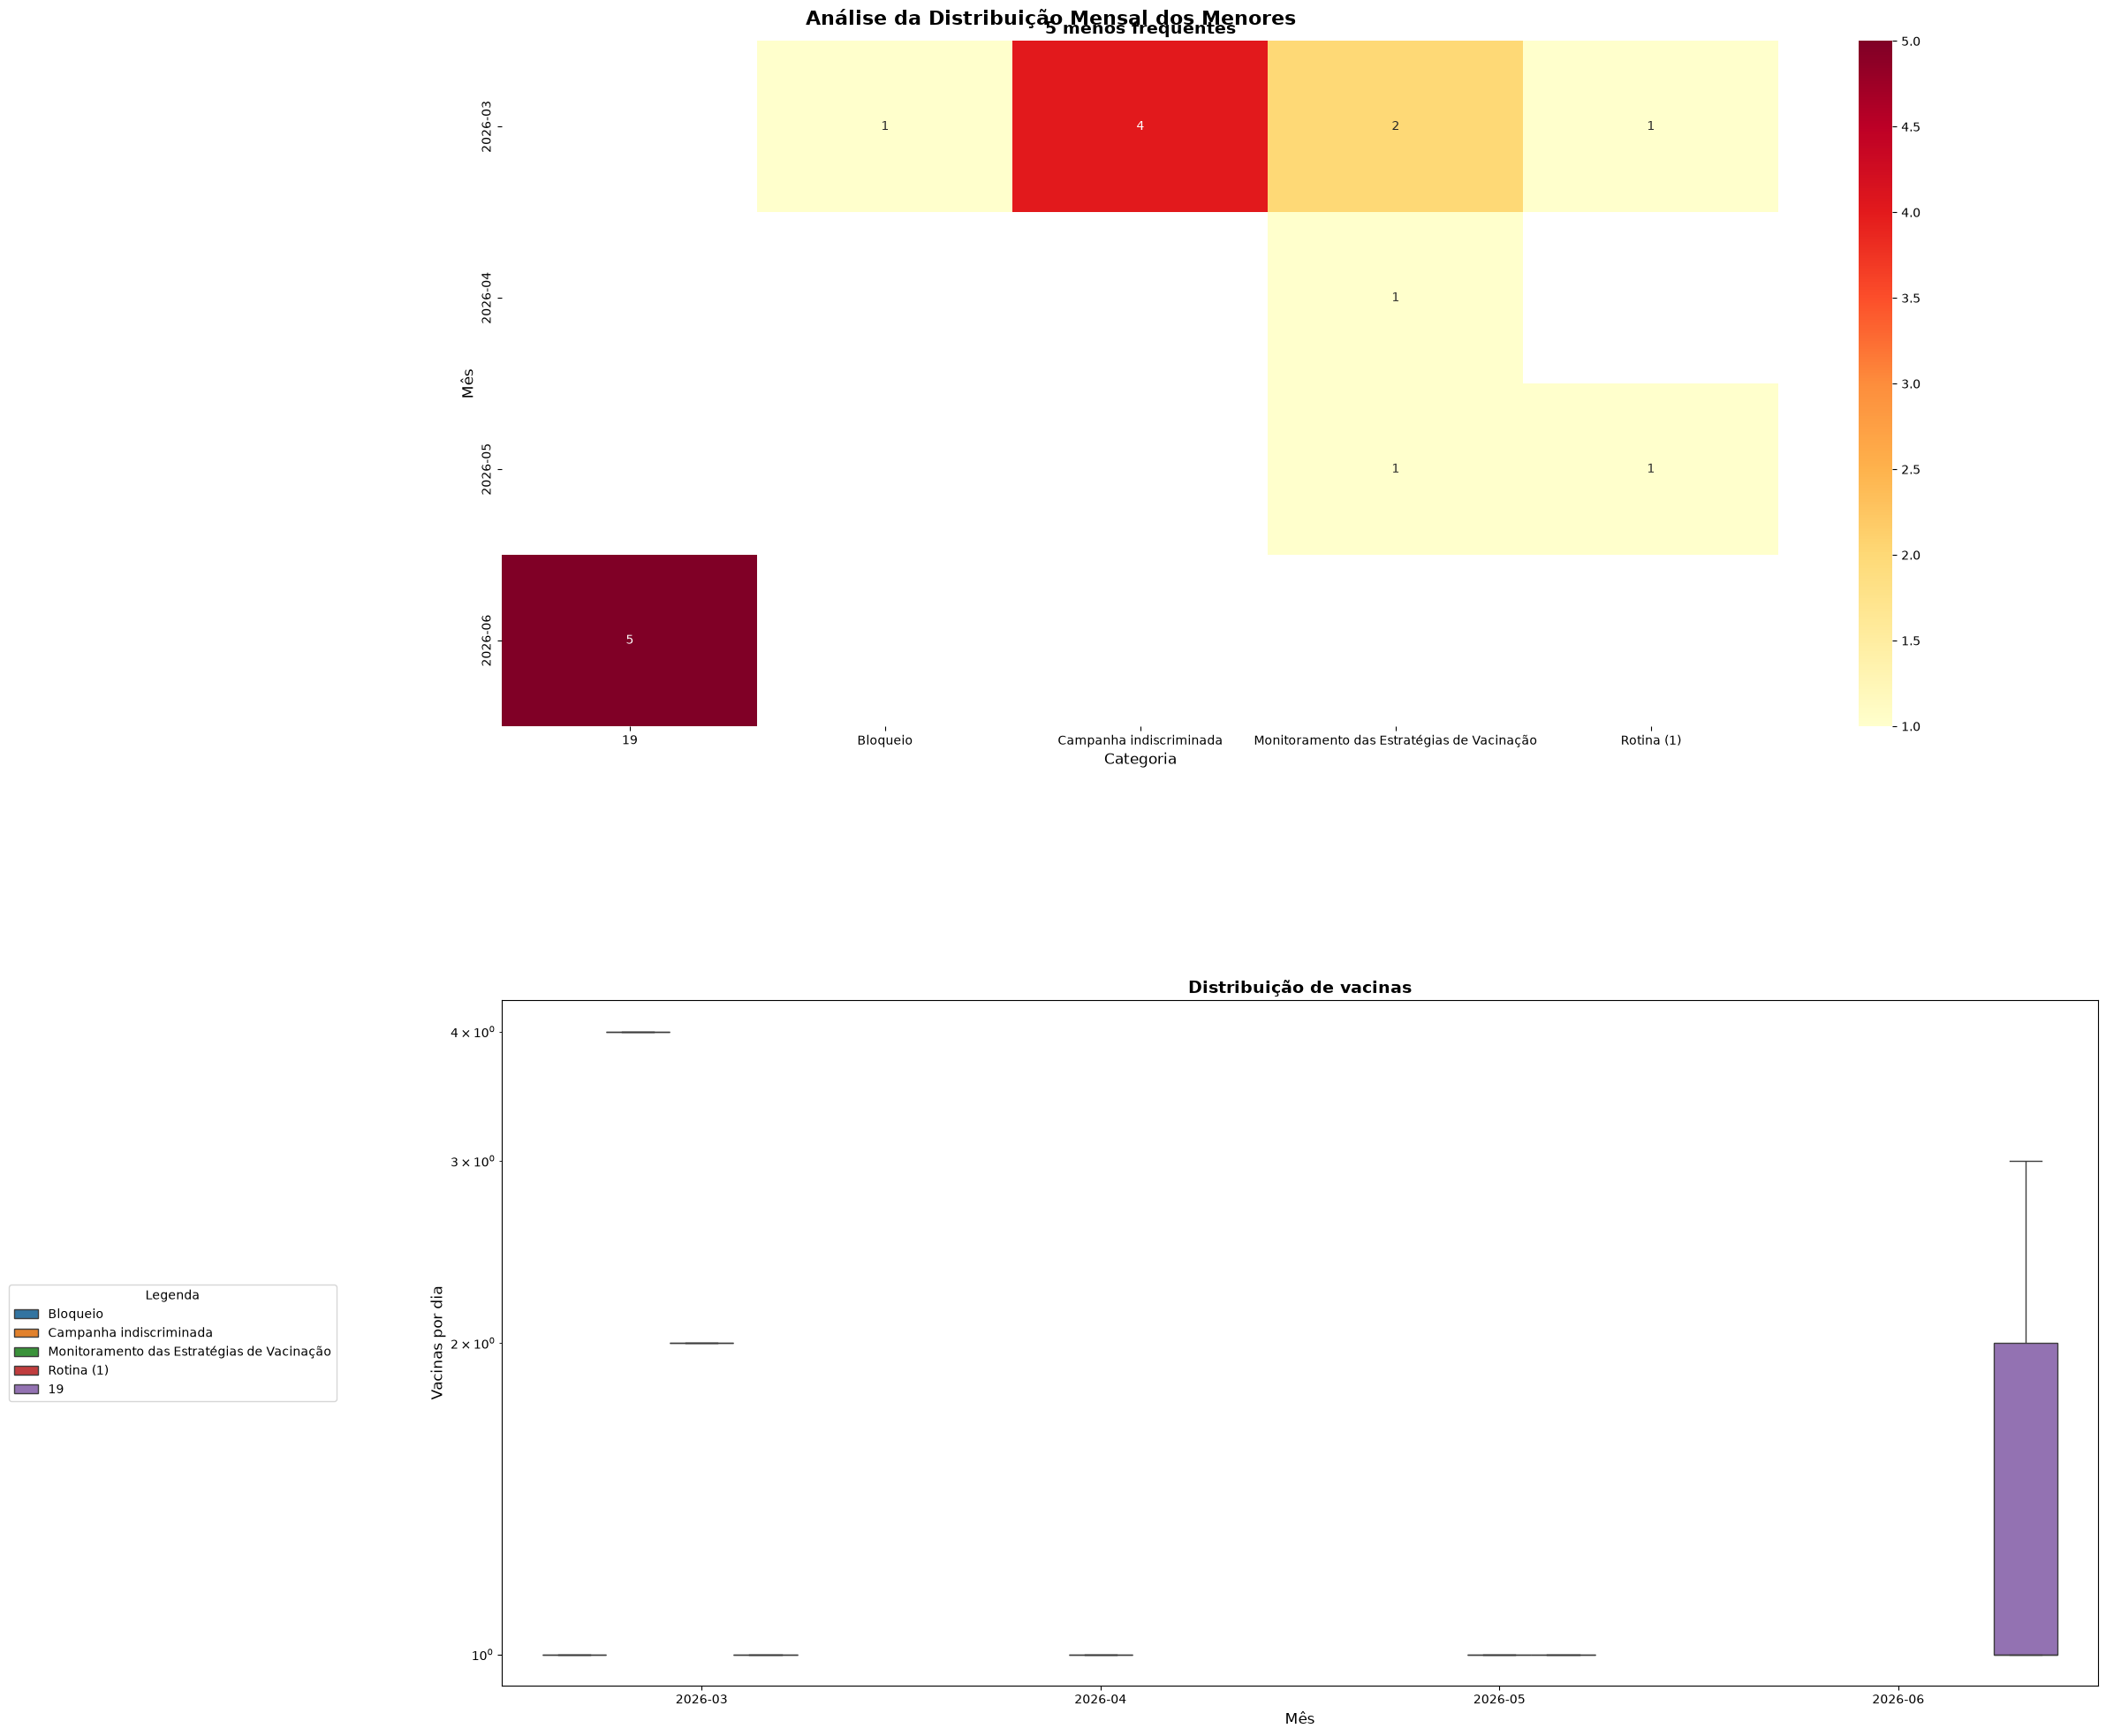

C:\Users\mirel\AppData\Local\Temp\ipykernel_9556\3013971637.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(labels)


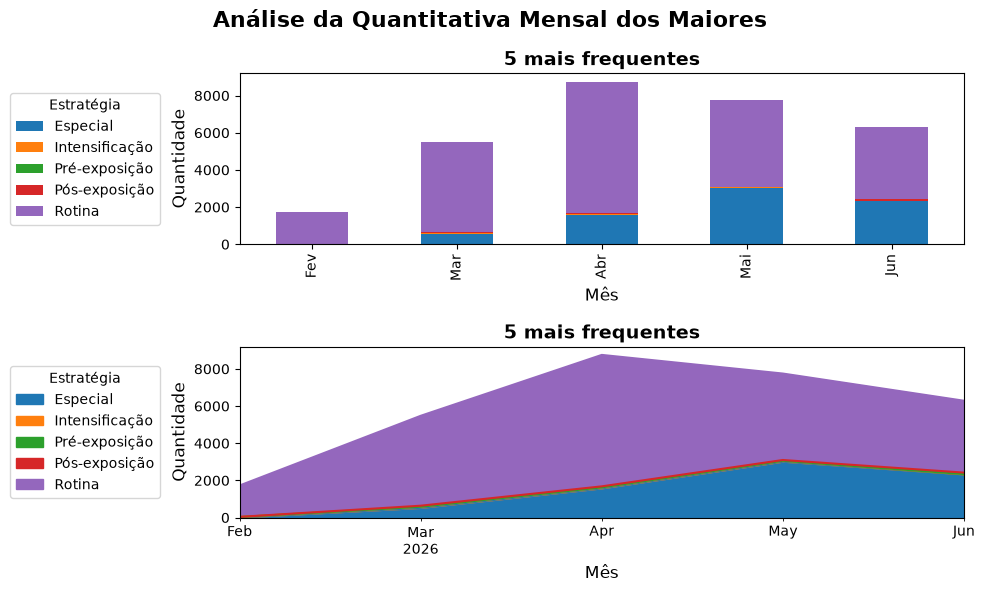

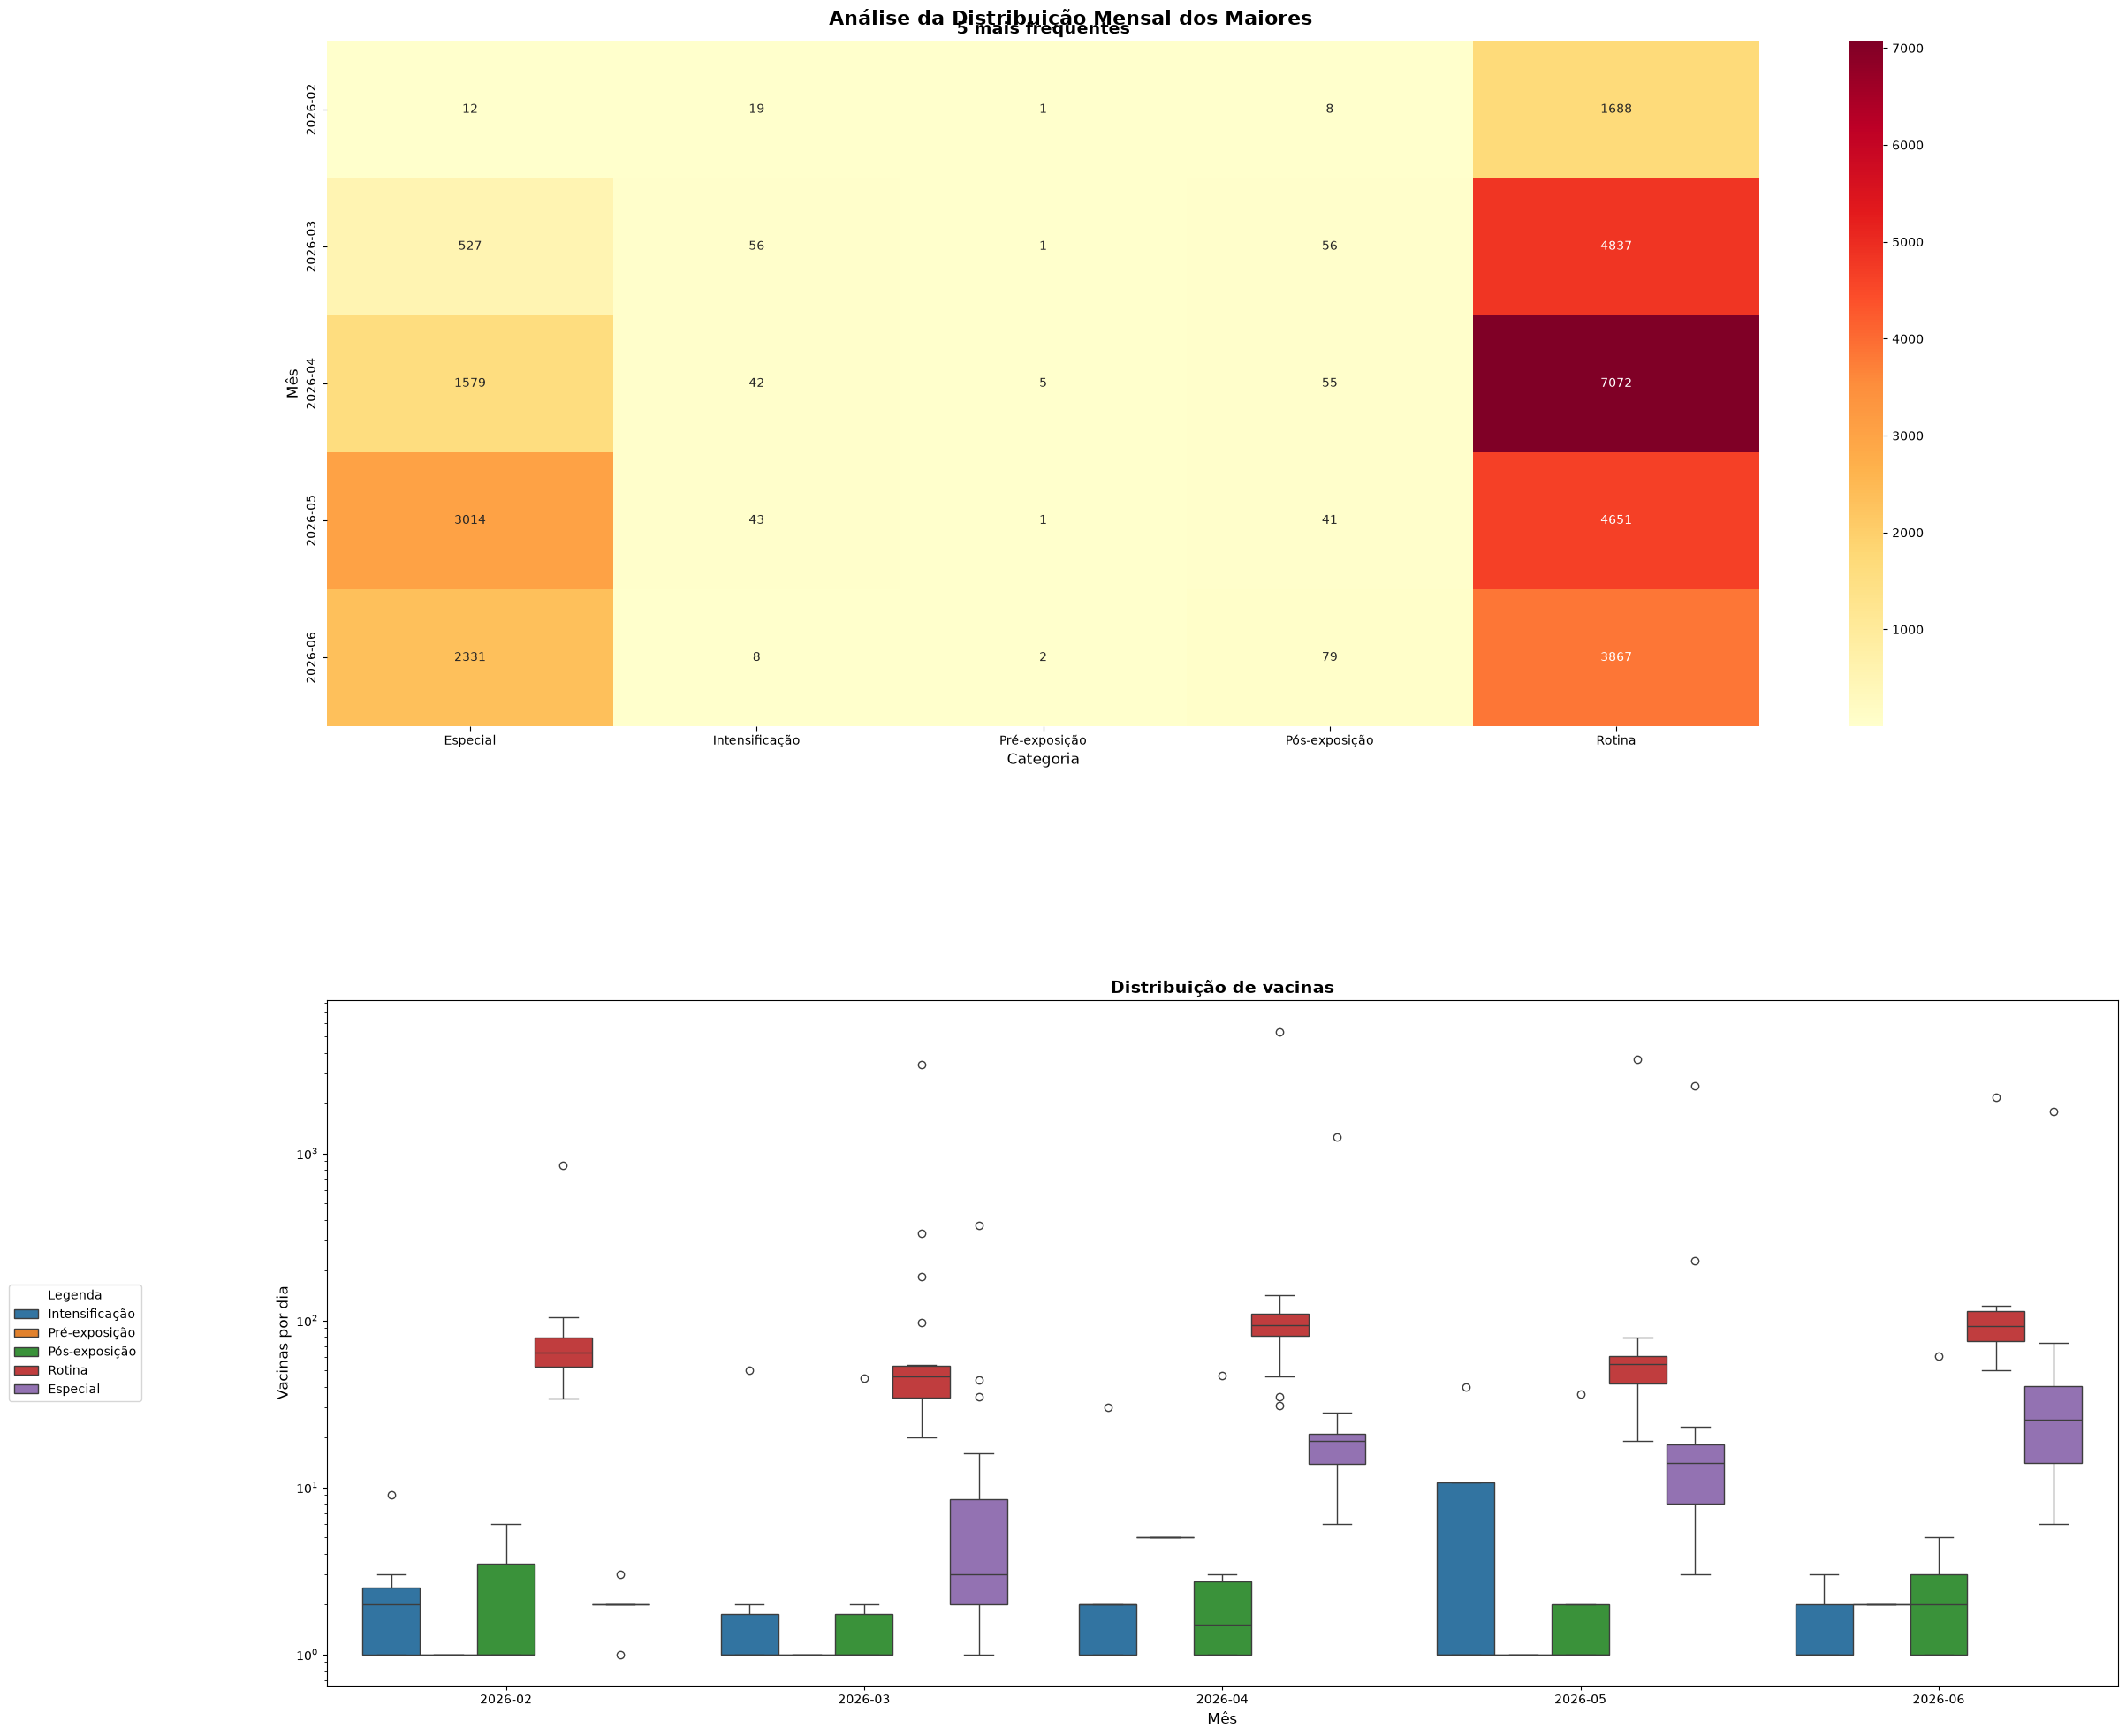

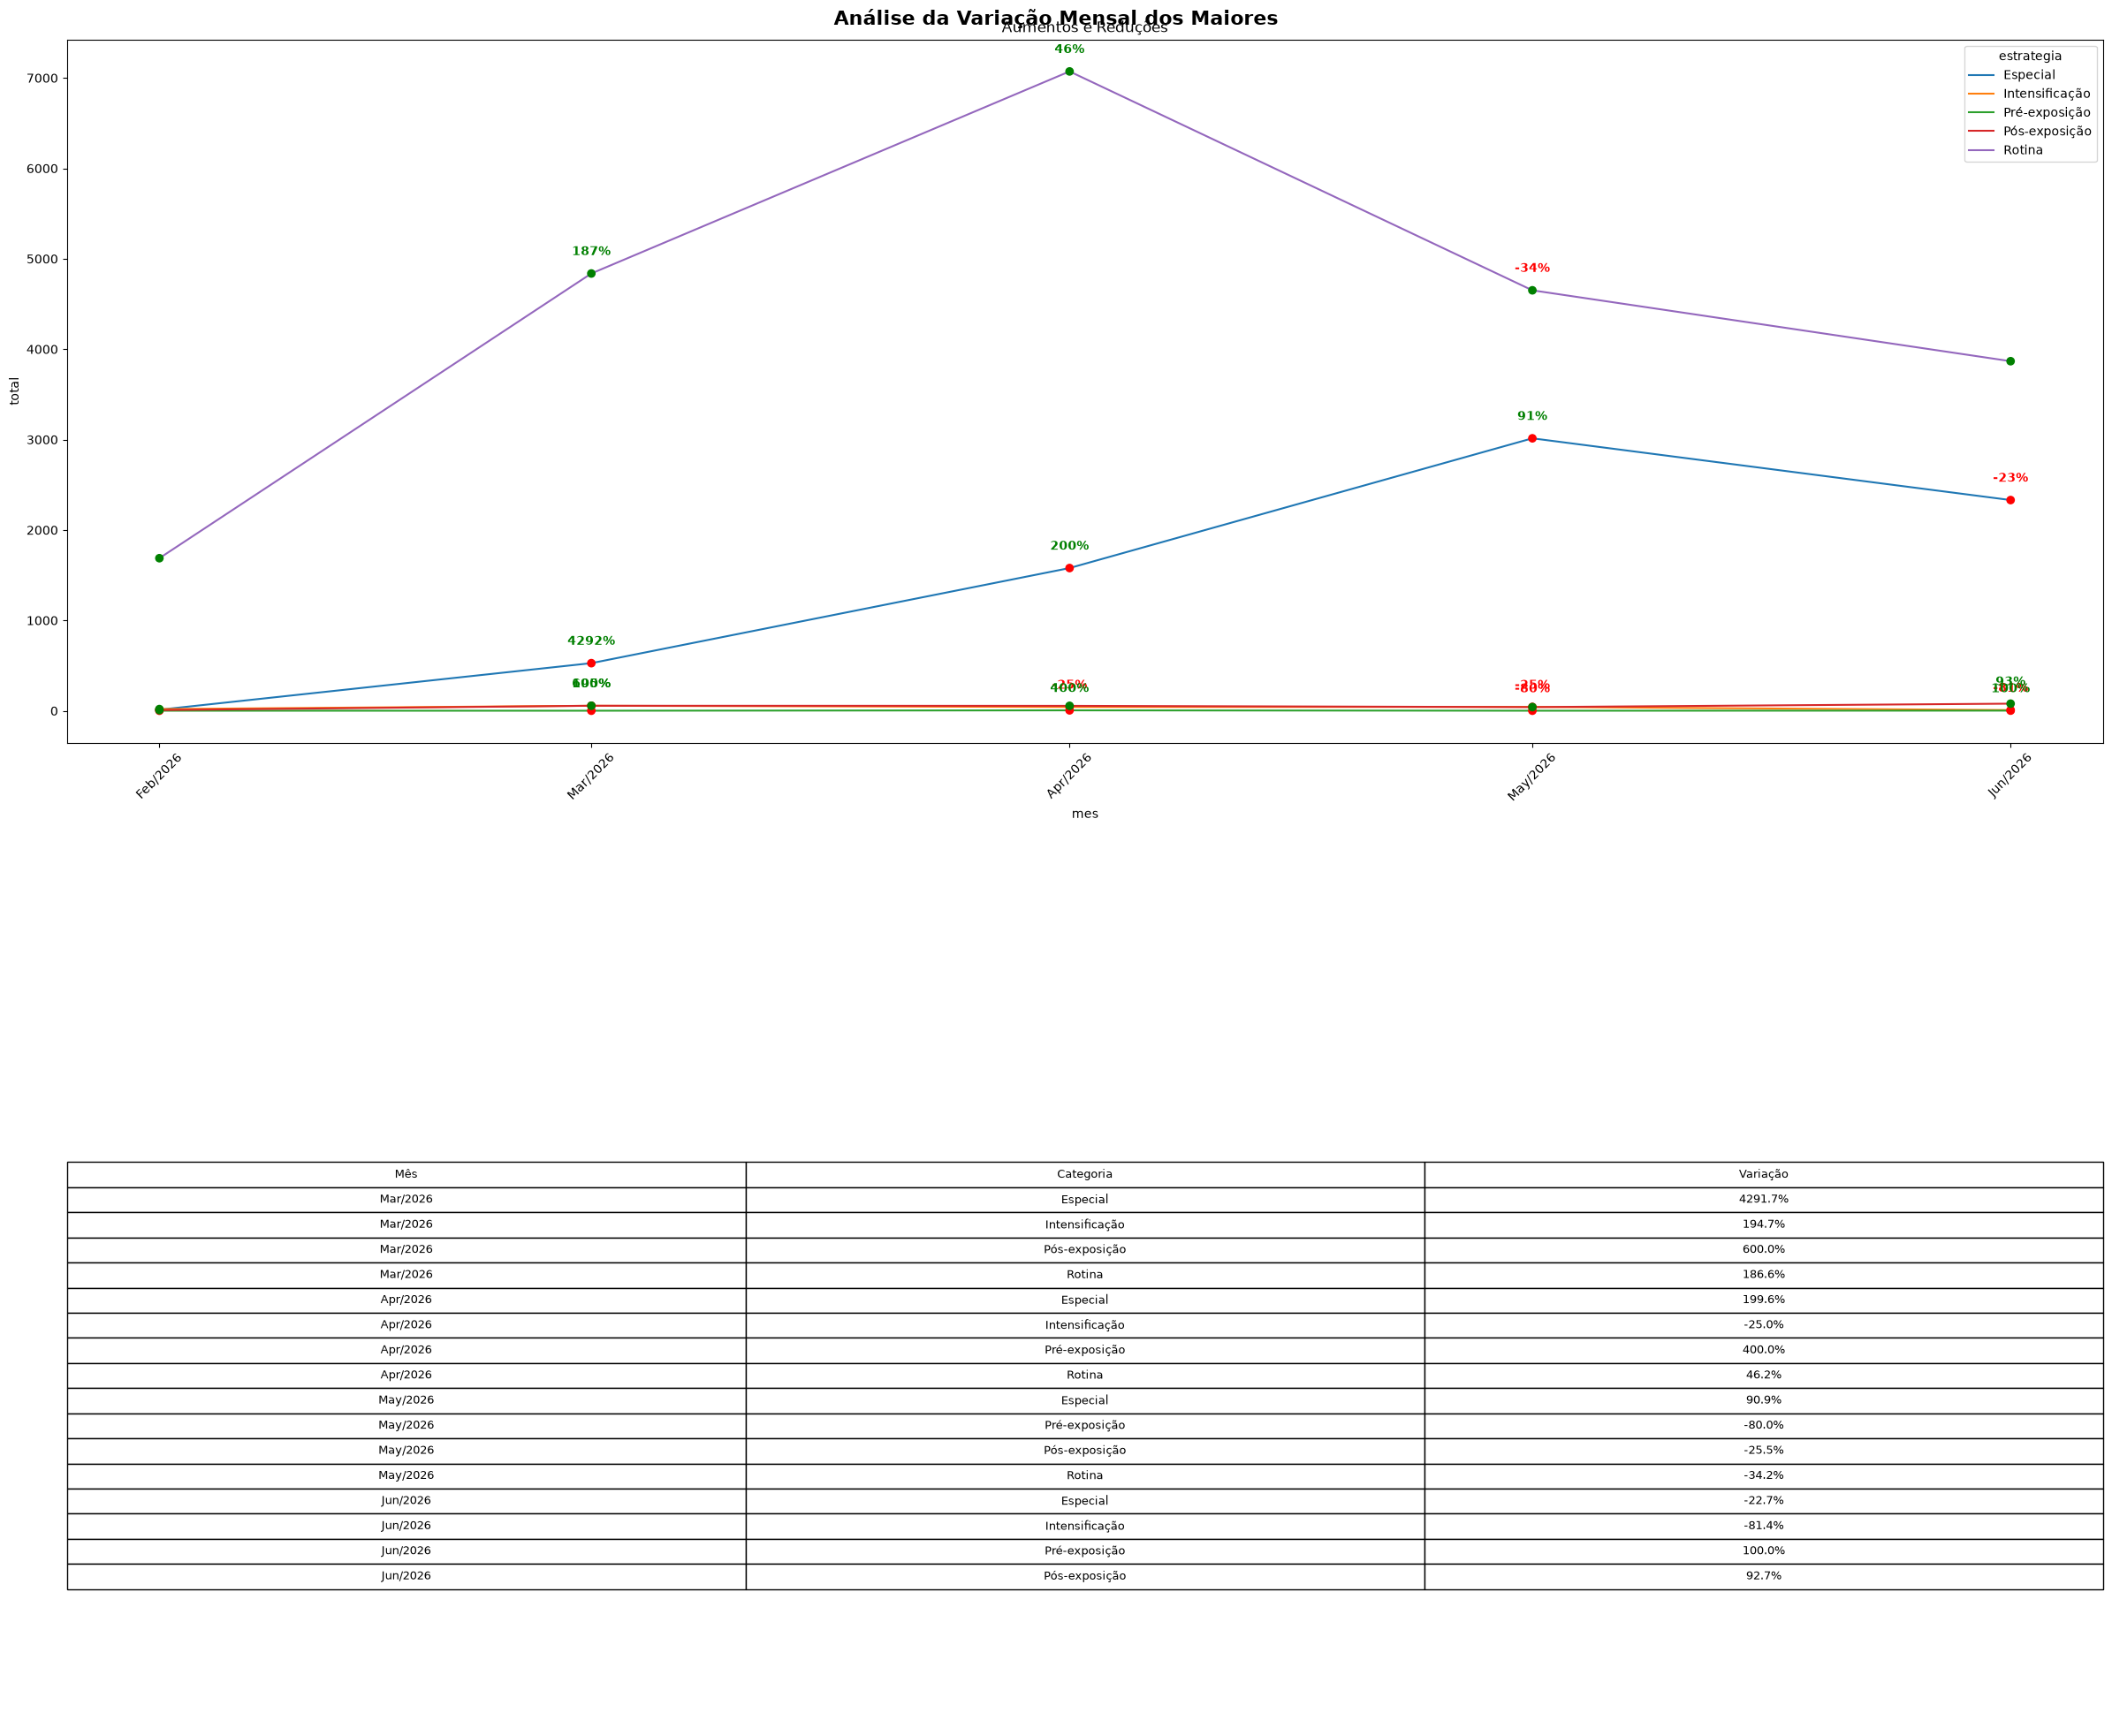

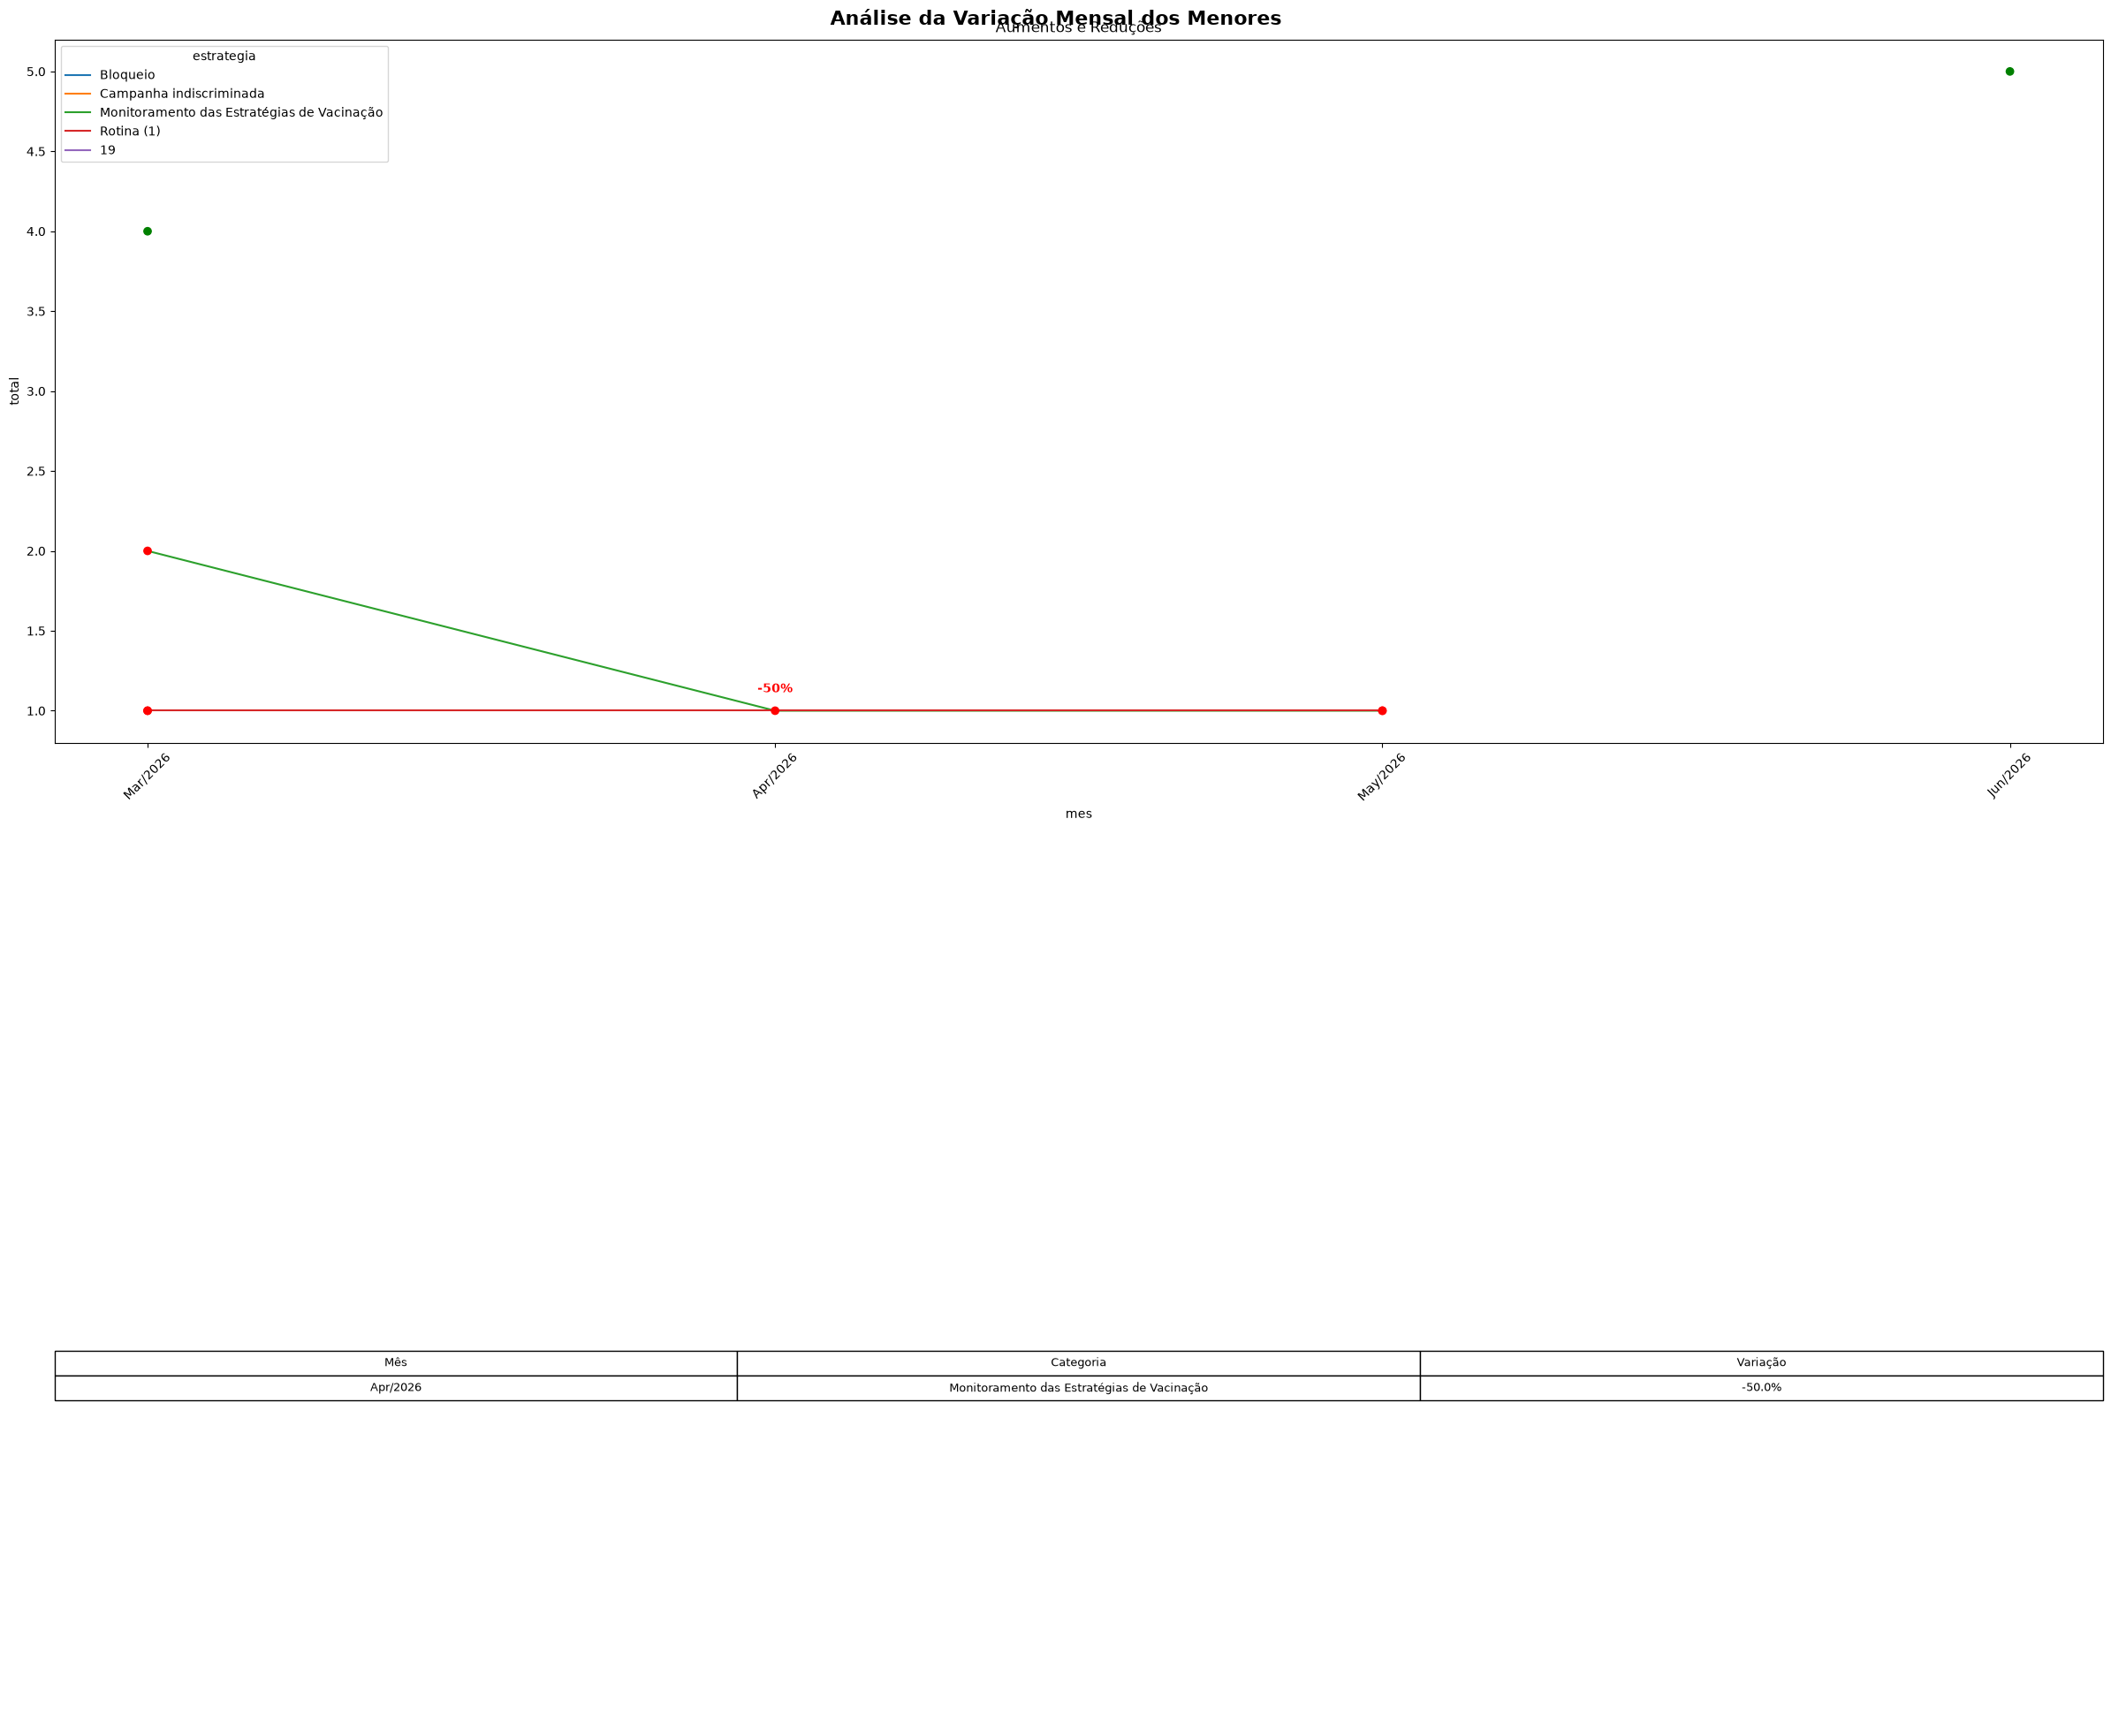

In [34]:
analise_temporal(df, 'estrategia', 'Estratégia')
distribuicao(df, 'estrategia', hue = '', index = 'mes', legend_title = 'Legenda', top = 5)
analise_temporal(df, 'estrategia', 'Estratégia', 5, False)
distribuicao(df, 'estrategia', hue = '', index = 'mes', legend_title = 'Legenda', top = 5, ascending=False)
plot_mensal(df, 'estrategia', ascending=False)
plot_mensal(df, 'estrategia', ascending=True)

Pontos a observar:
* As estratégias com menor volume de vacina possuem pouquíssimas vacinações (menos que 10).
* Observando e comparando as maiores e menores, pode se ver que as estratégias que concentram o maior volume são as de rotina (que segue o fluxo geral, normal, esperado) e especial, as outras possuem volume baixíssimo
* A rotina possue uma maior constância, apenas tem o pico em abril, quando provavelemente começam as campanhas da infuenza.
* A  especial apresentou um aumento significativo em maio.

### DOSE APLICADA

C:\Users\mirel\AppData\Local\Temp\ipykernel_9556\3013971637.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(labels)


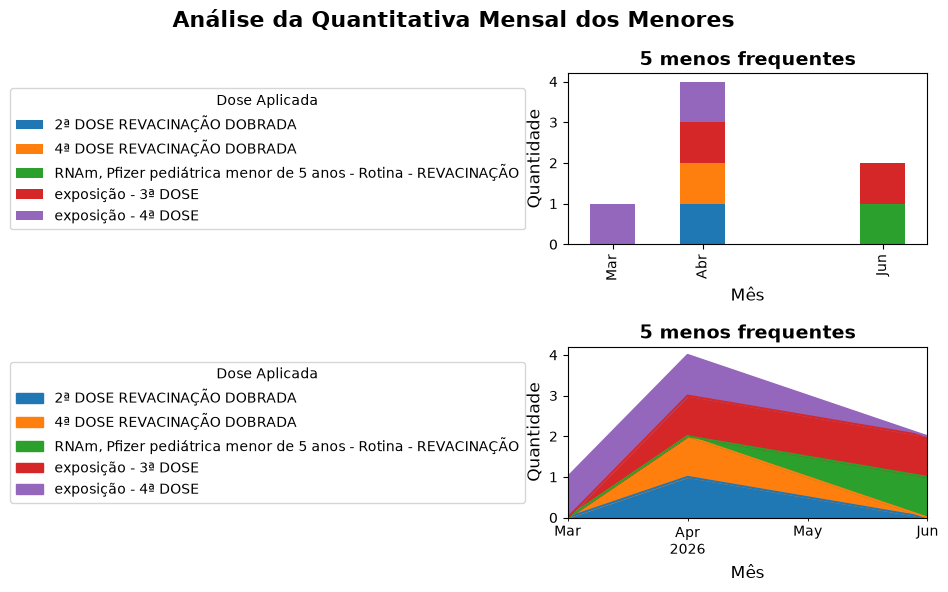

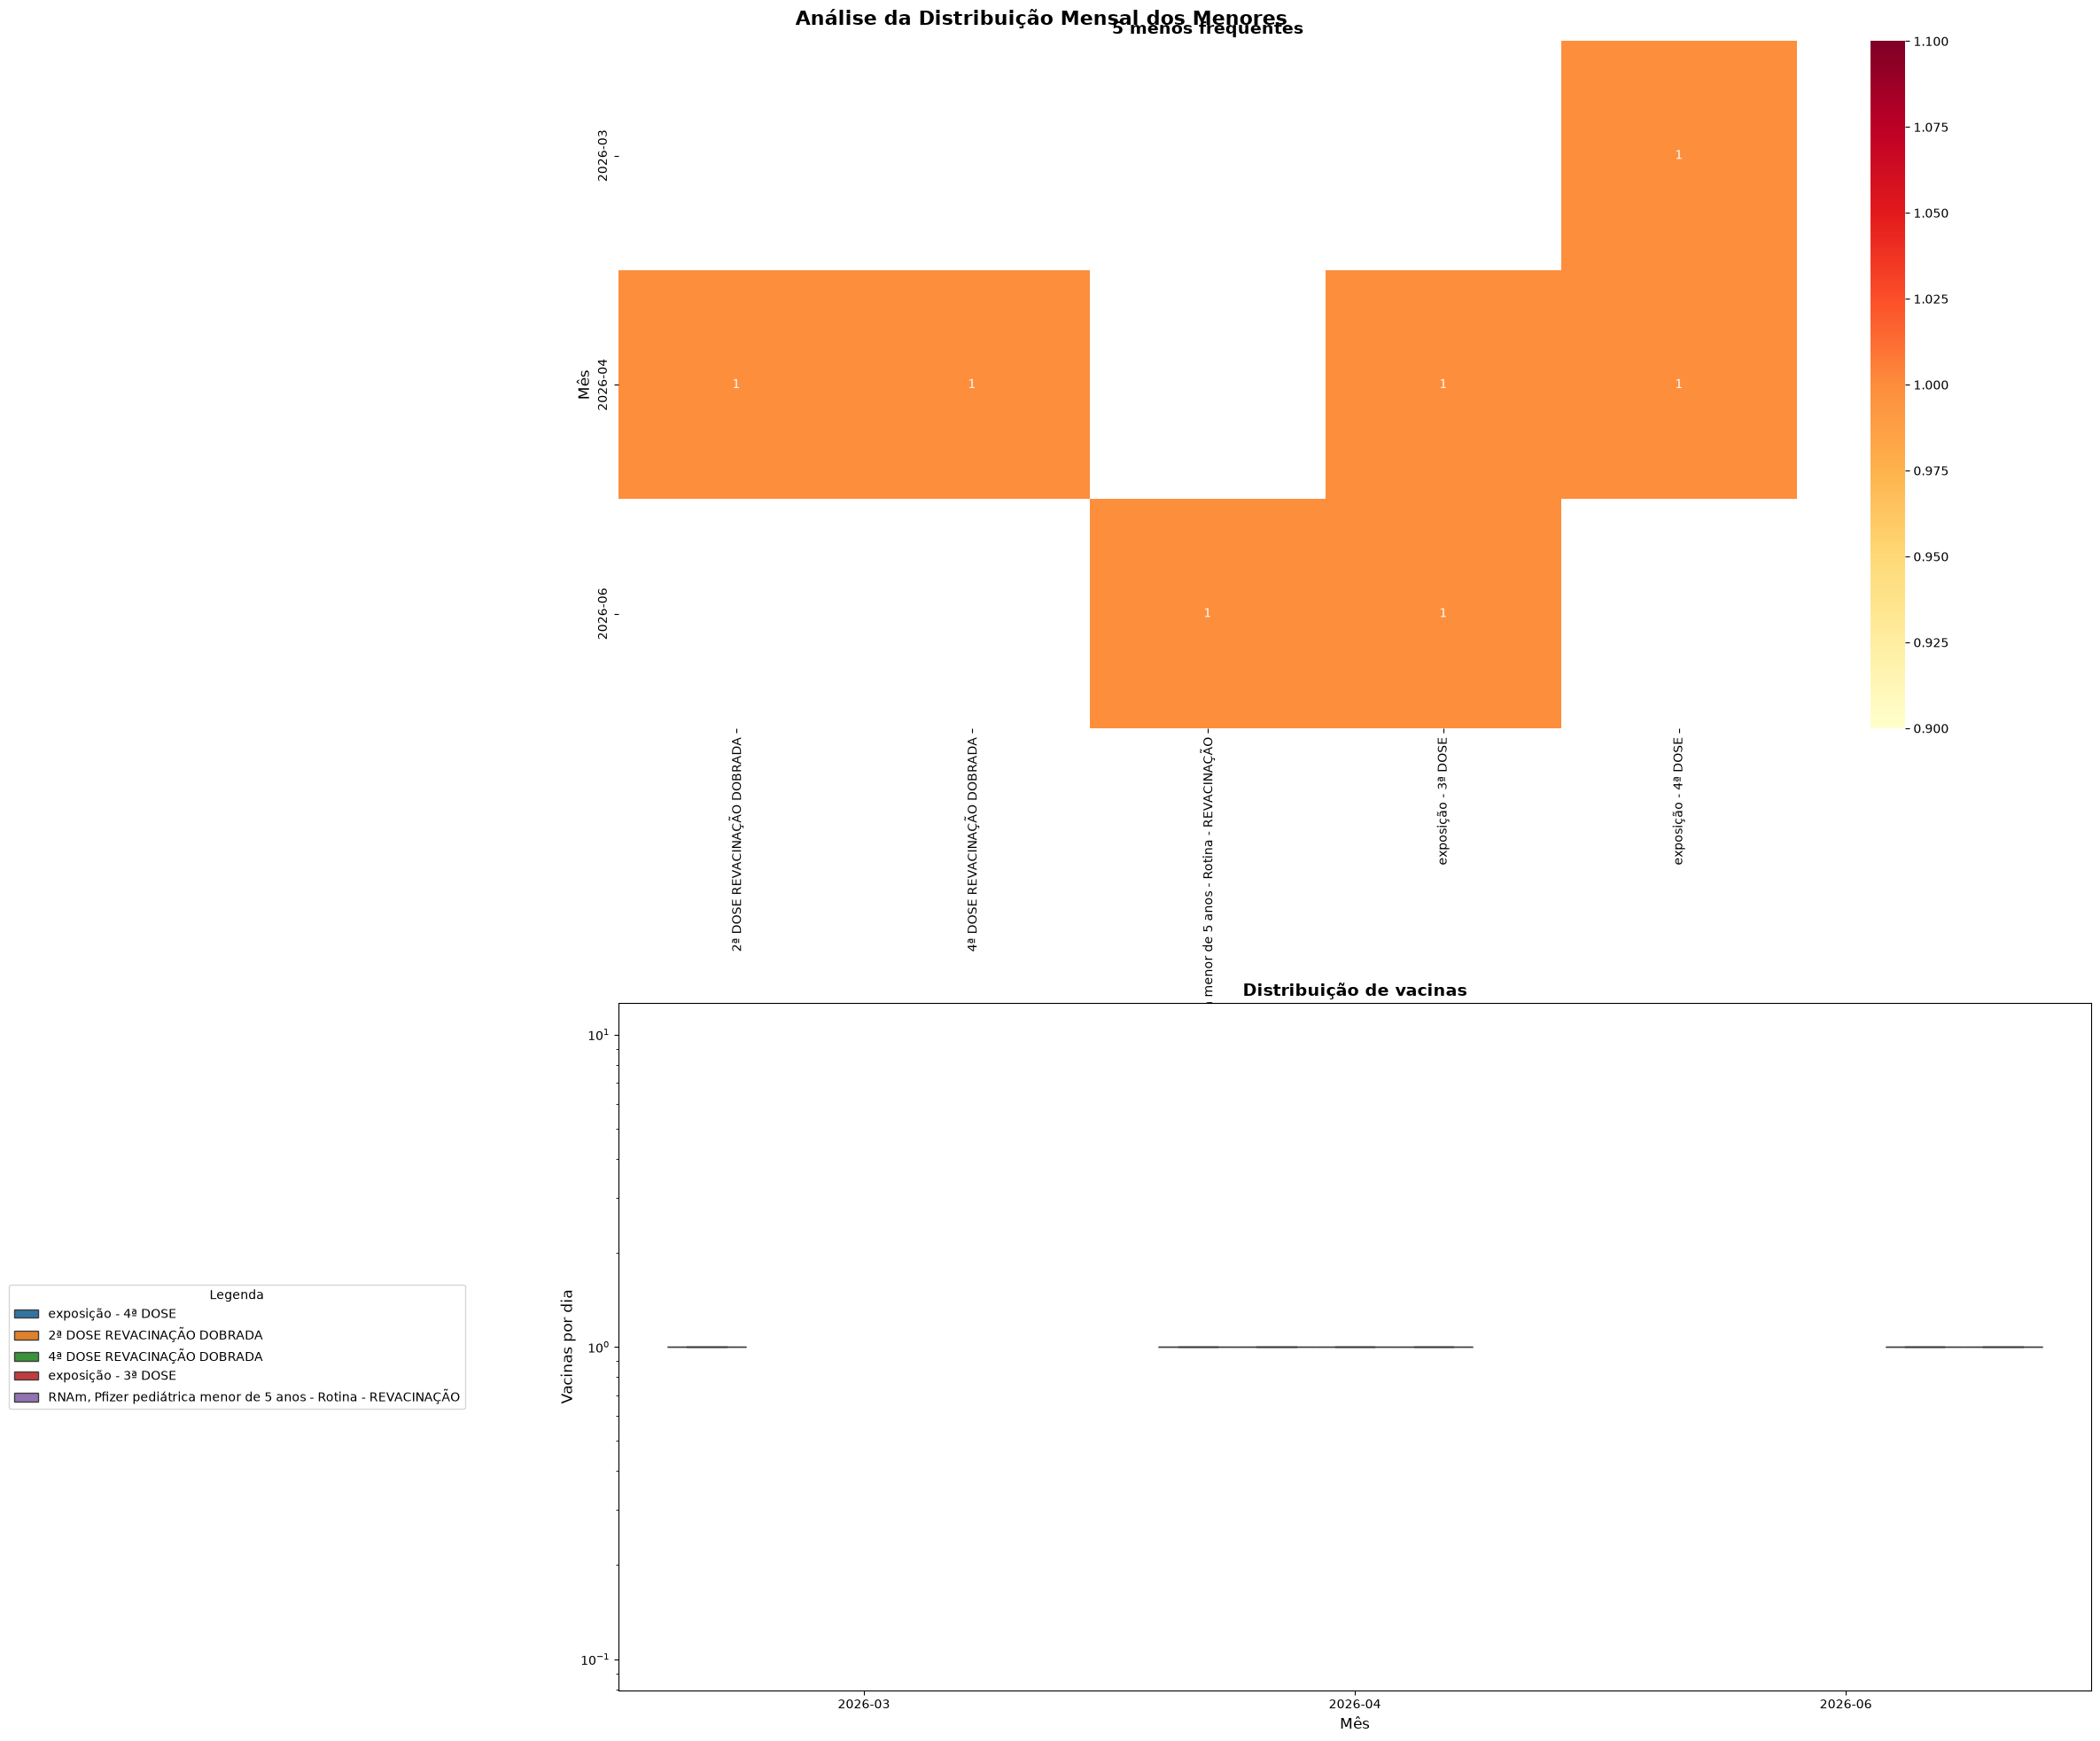

C:\Users\mirel\AppData\Local\Temp\ipykernel_9556\3013971637.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(labels)


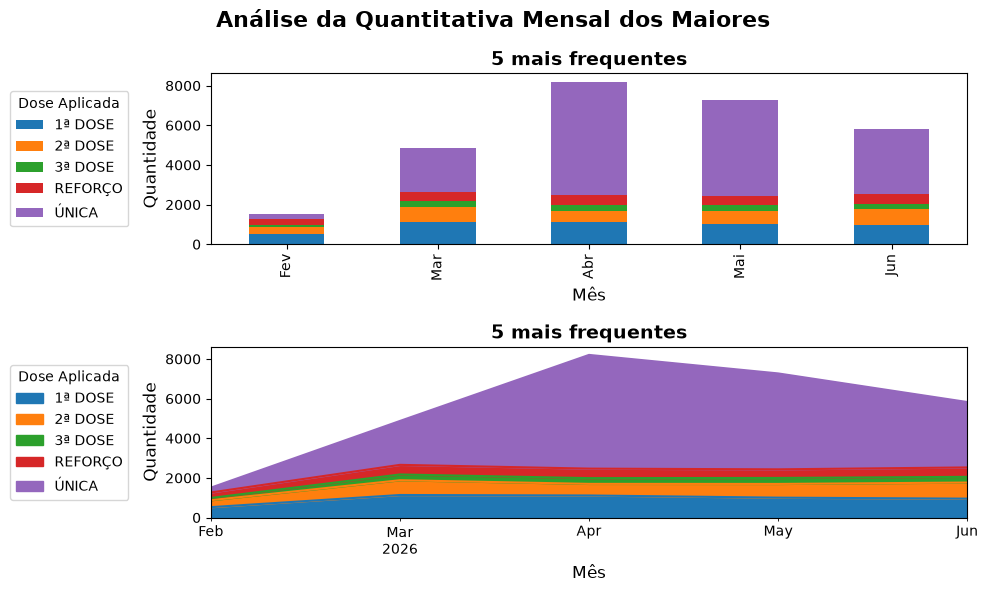

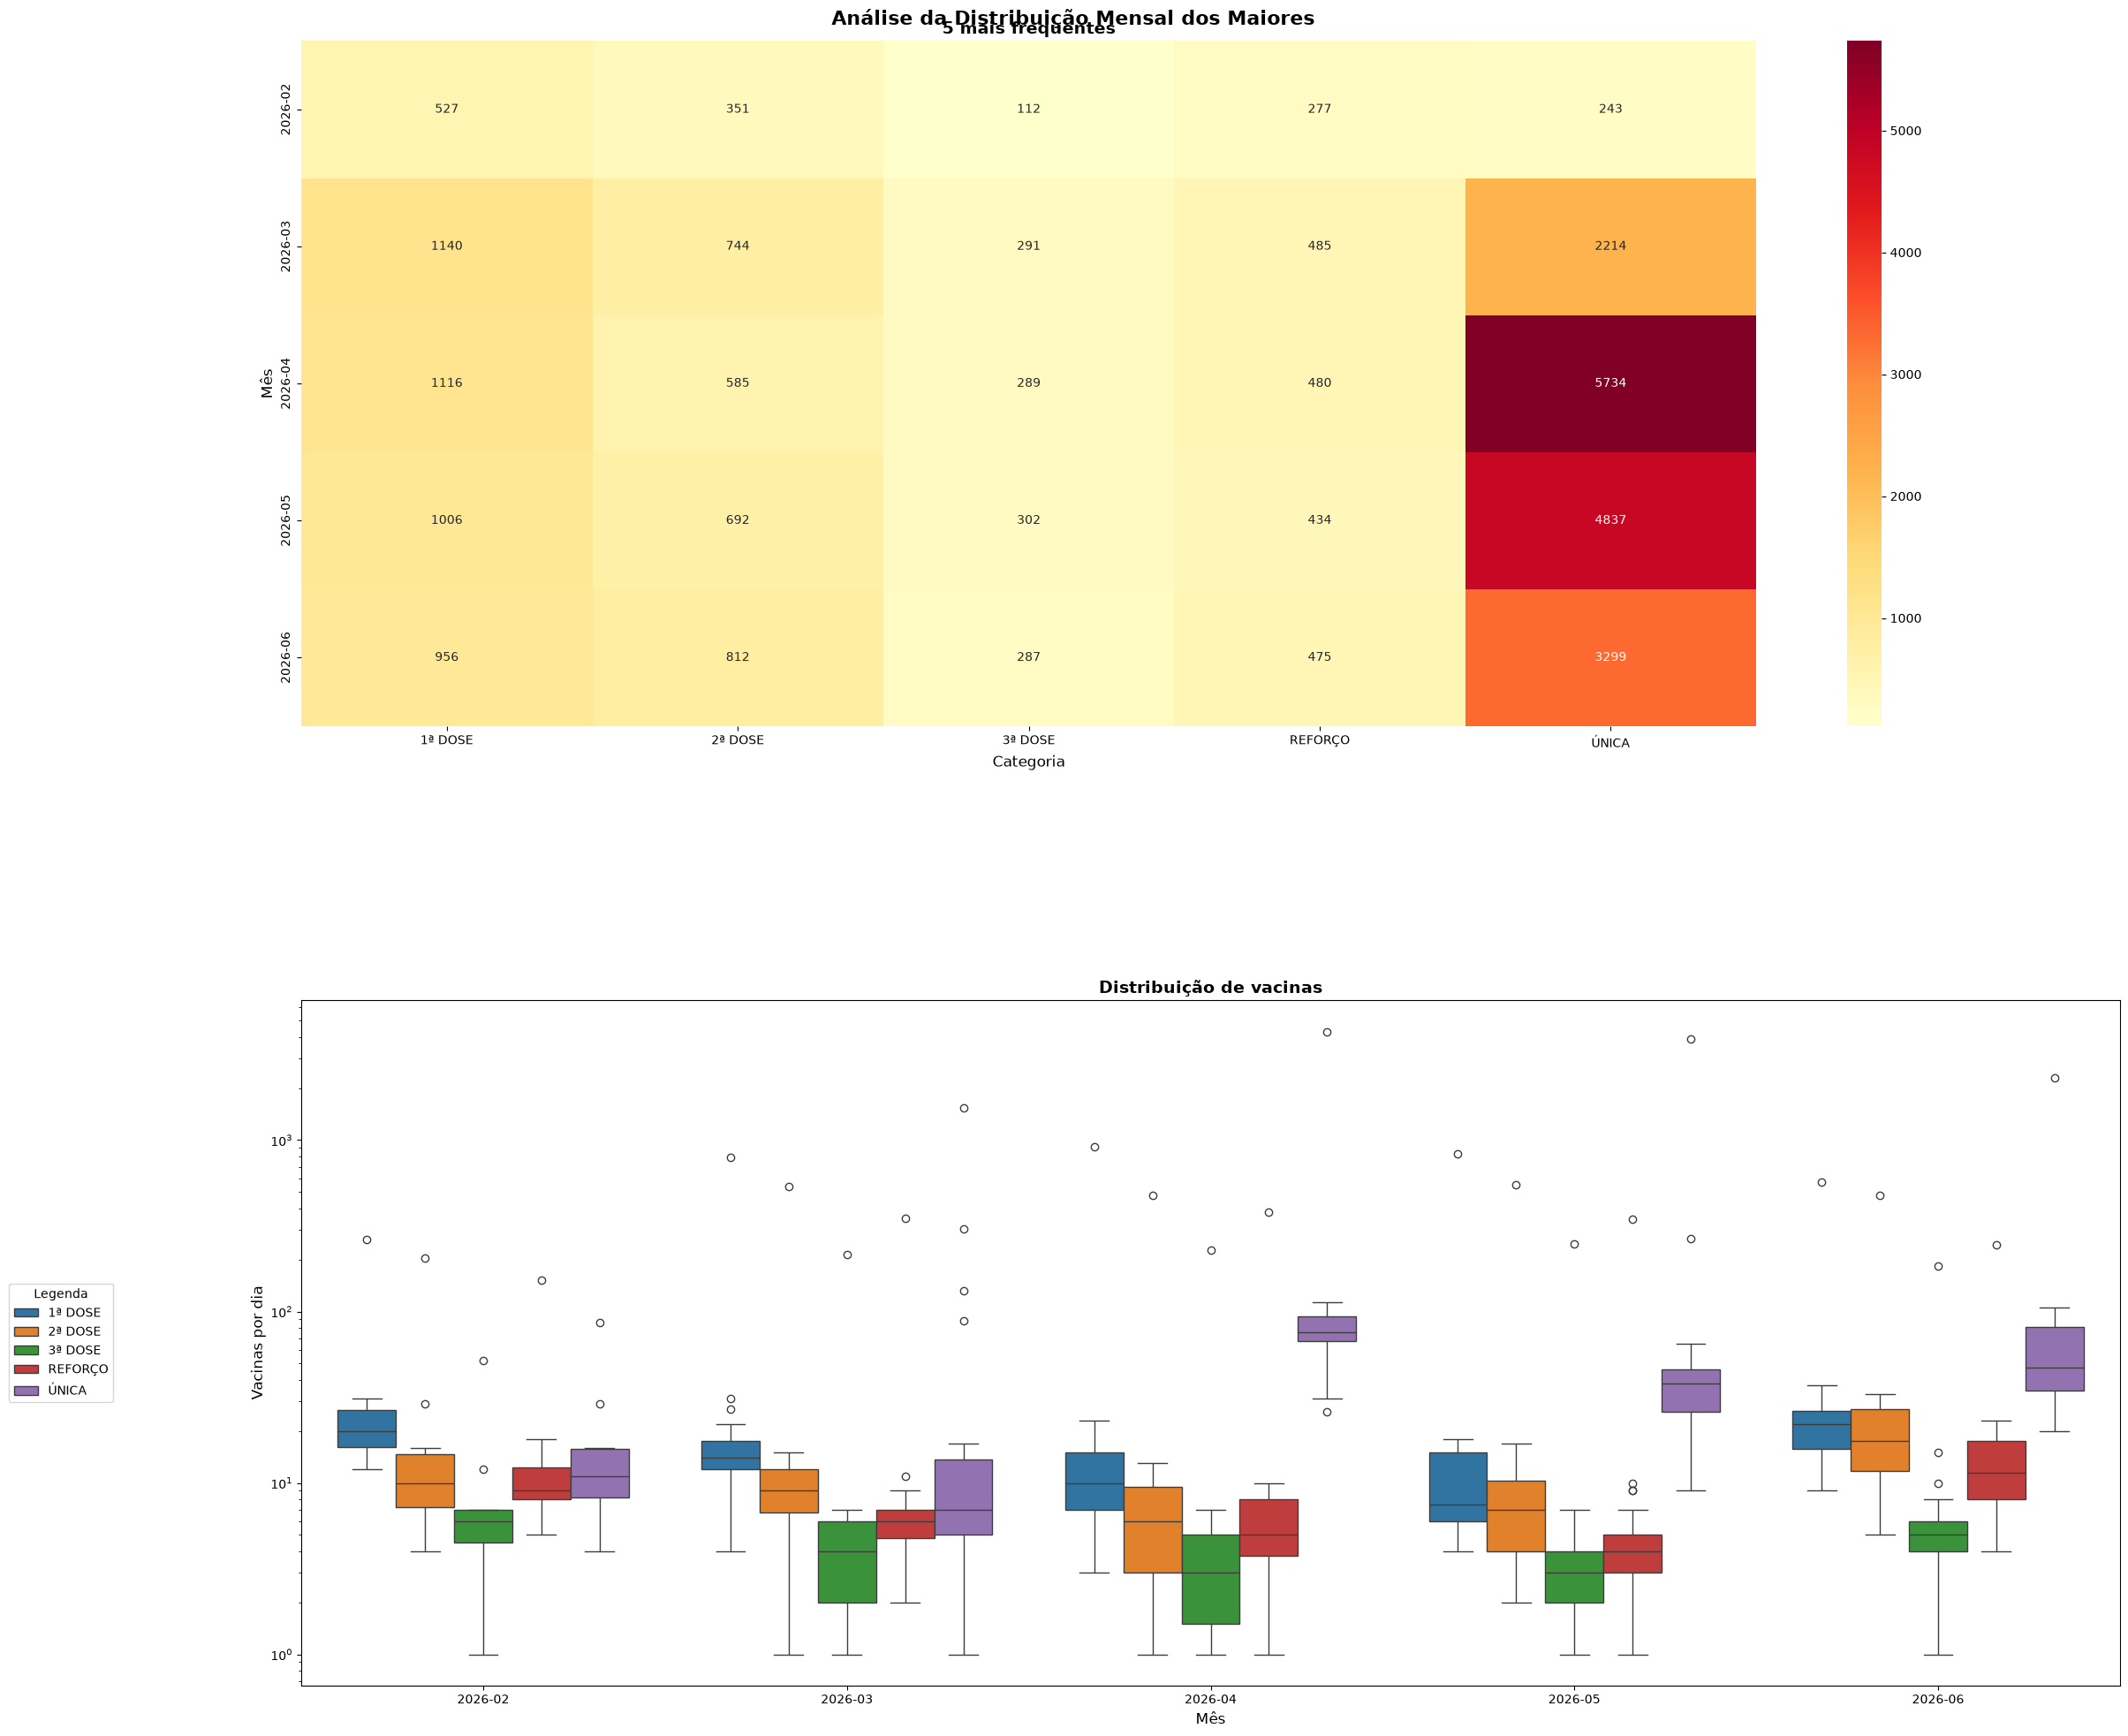

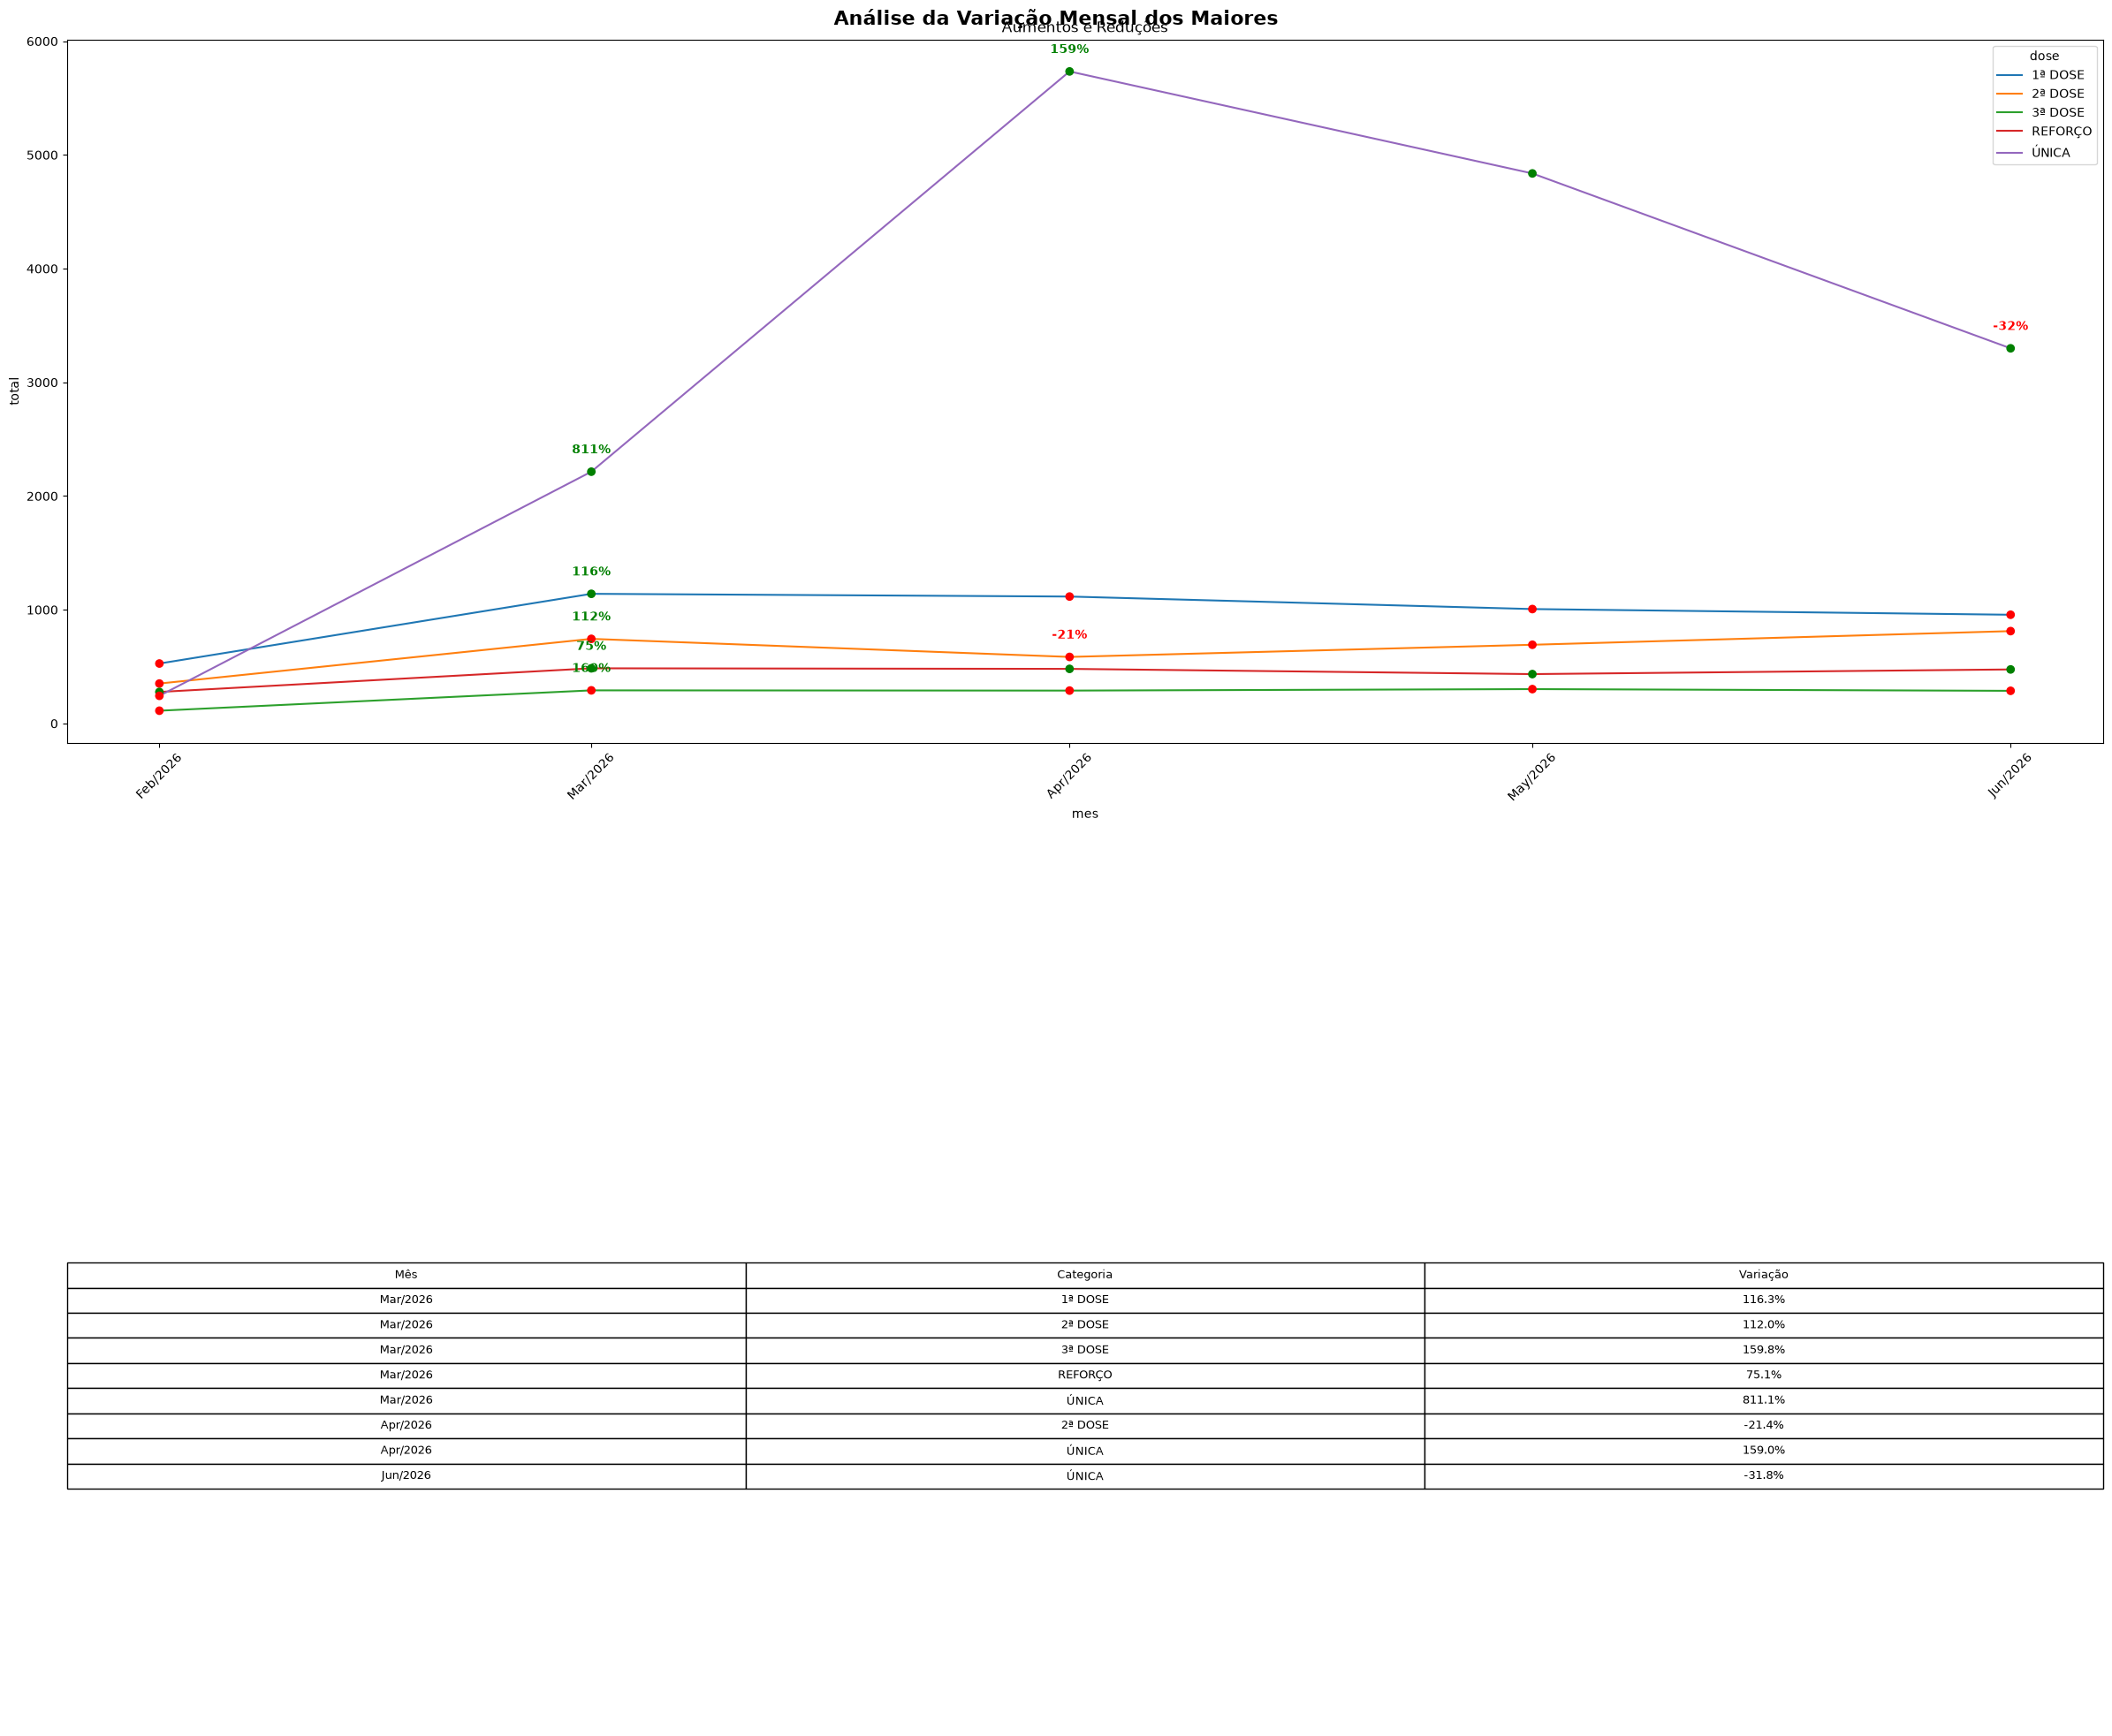

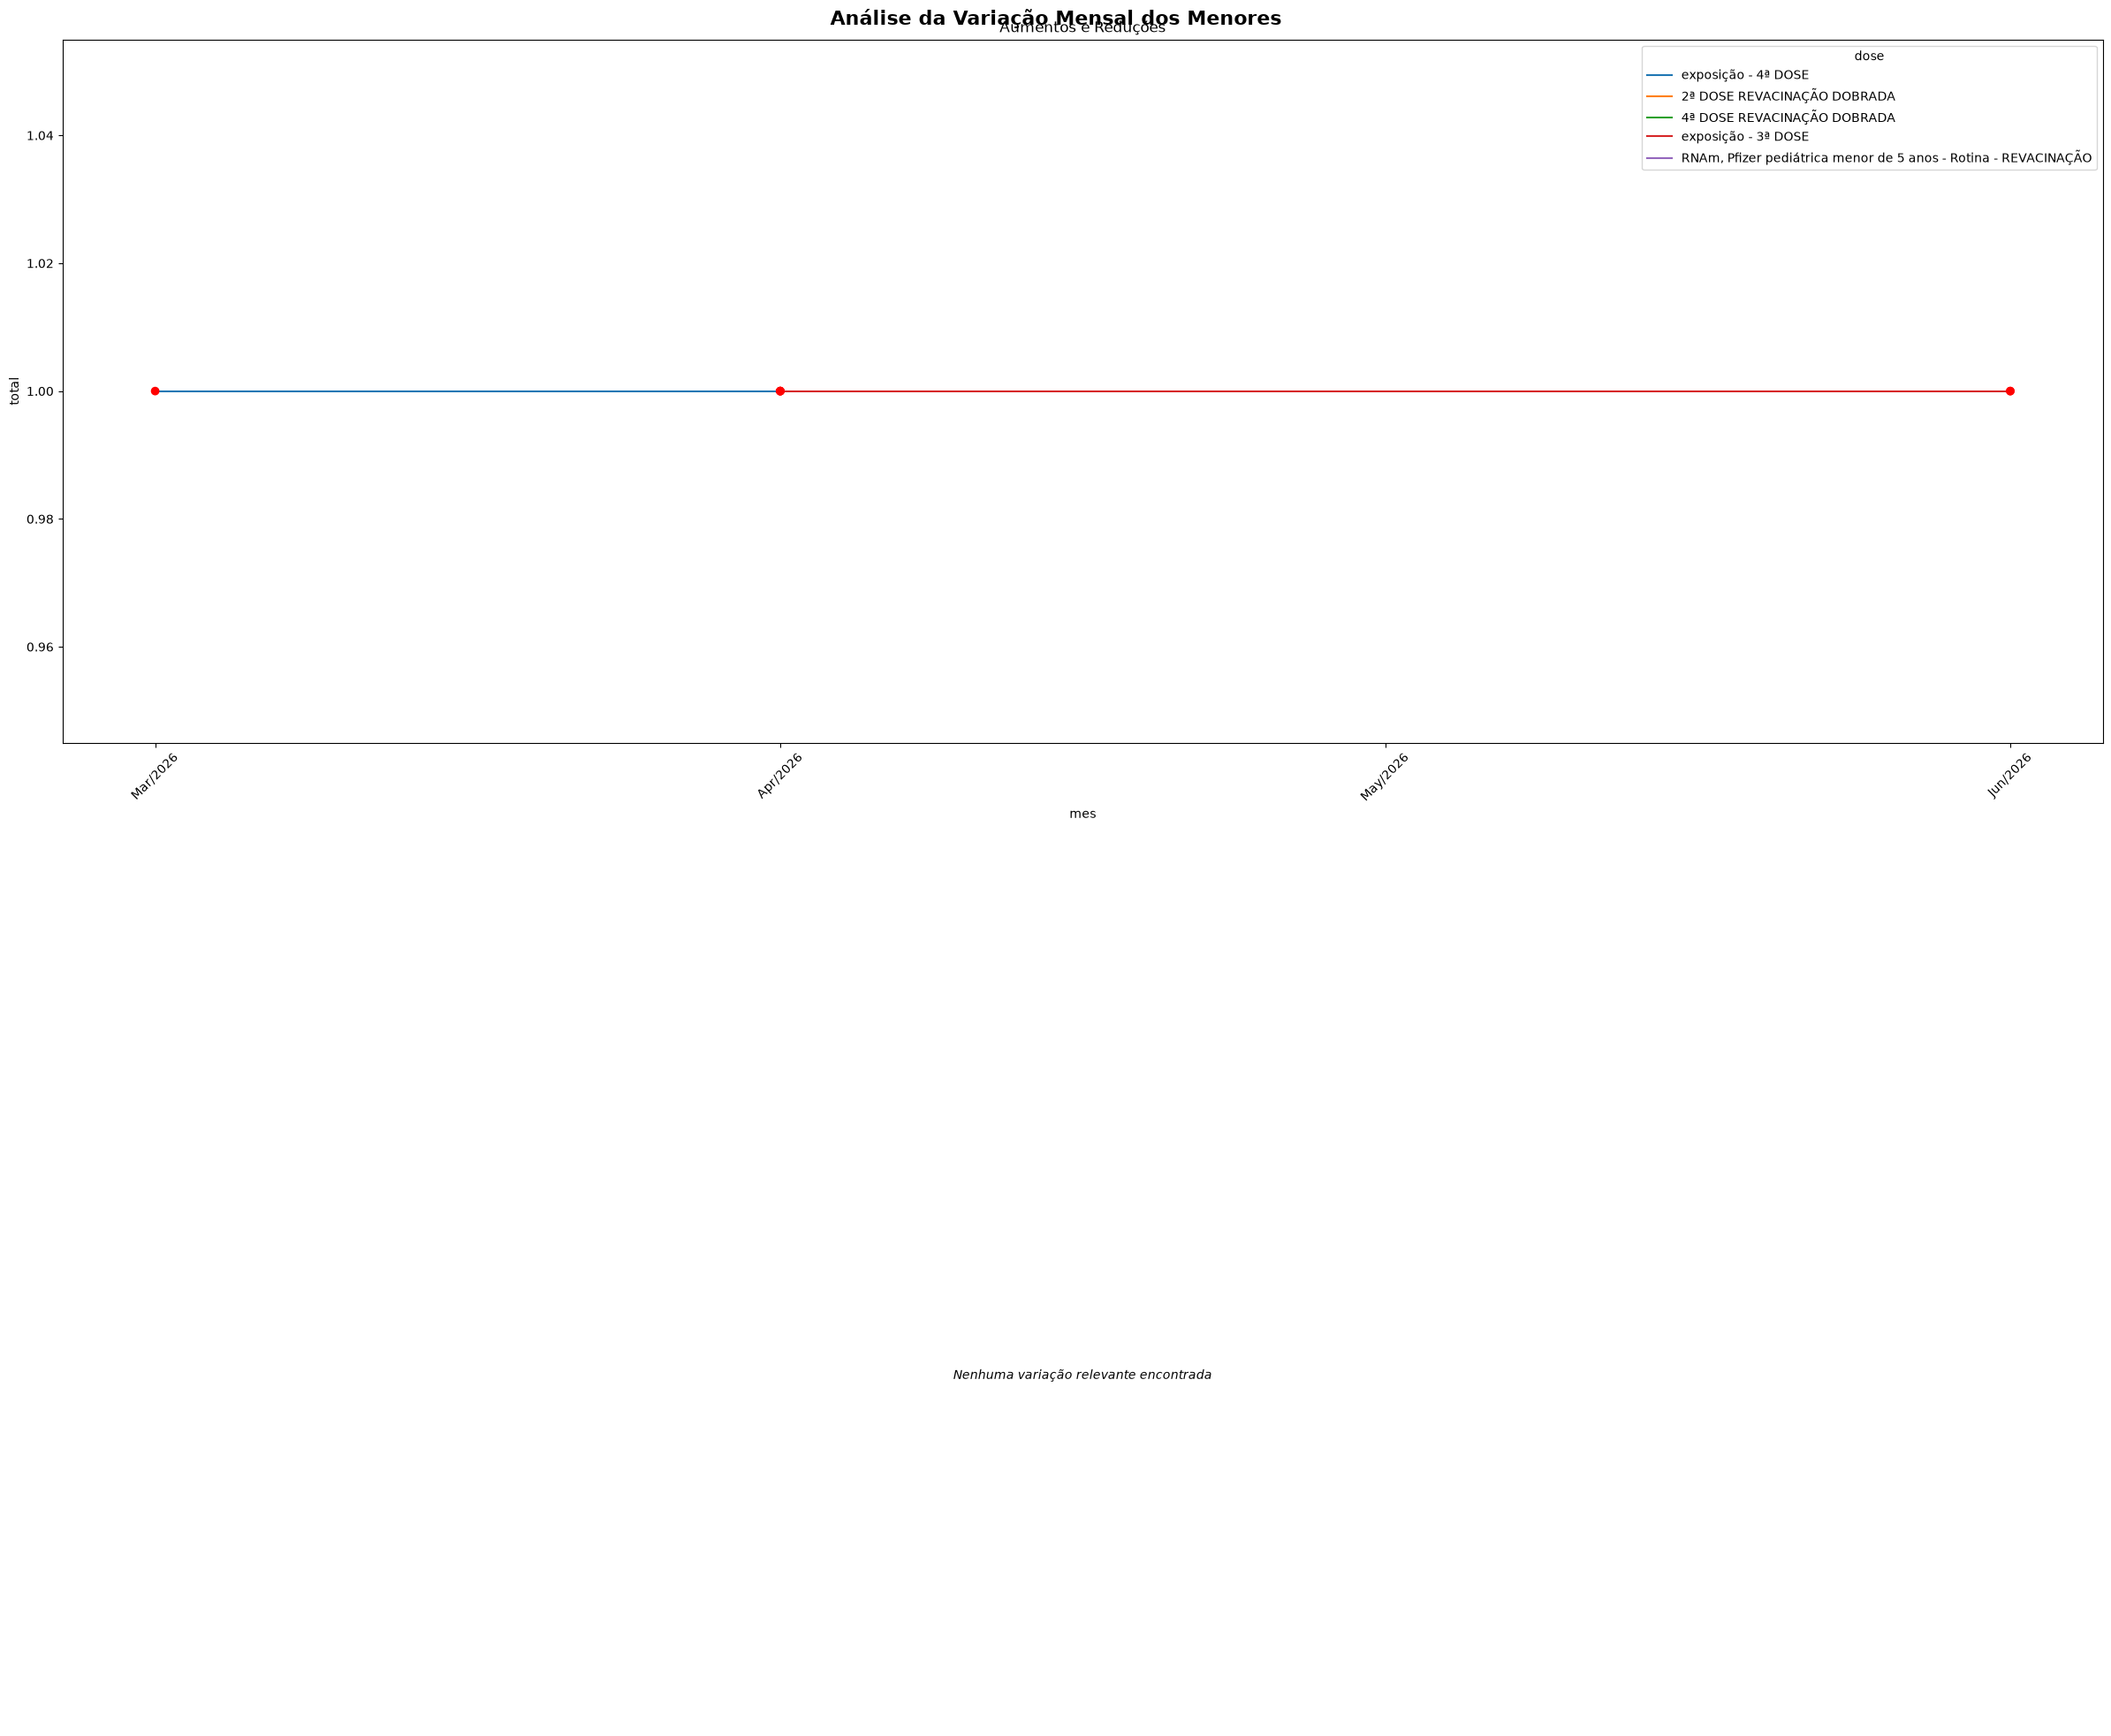

In [35]:
analise_temporal(df, 'dose', 'Dose Aplicada')
distribuicao(df, 'dose', hue = '', index = 'mes', legend_title = 'Legenda', top = 5)
analise_temporal(df, 'dose', 'Dose Aplicada', 5, False)
distribuicao(df, 'dose', hue = '', index = 'mes', legend_title = 'Legenda', top = 5, ascending=False)
plot_mensal(df, 'dose', ascending=False)
plot_mensal(df, 'dose', ascending=True)


Pontos a observar:
* A dose com maior volume é a única, que possui um aumento relevante em abril.
* As outras doses (primeira, segunda, terceira e reforço) mantém uma constancia ao longo do período, porém uma diminuição no volume em relação a próxima dose  (primeira -> segunda -> terceira ...)
* Assim como as vacinas, as doses que possuem menor volume, tem dados baixíssimos, o que impossibilita uma melhor análise temporal.

### ORIGEM

C:\Users\mirel\AppData\Local\Temp\ipykernel_9556\3013971637.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(labels)


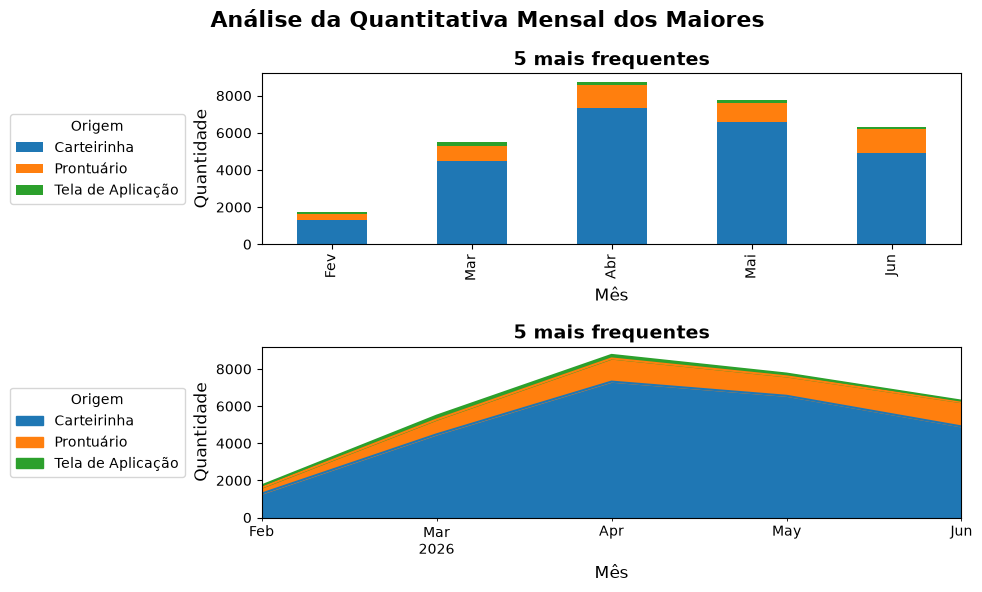

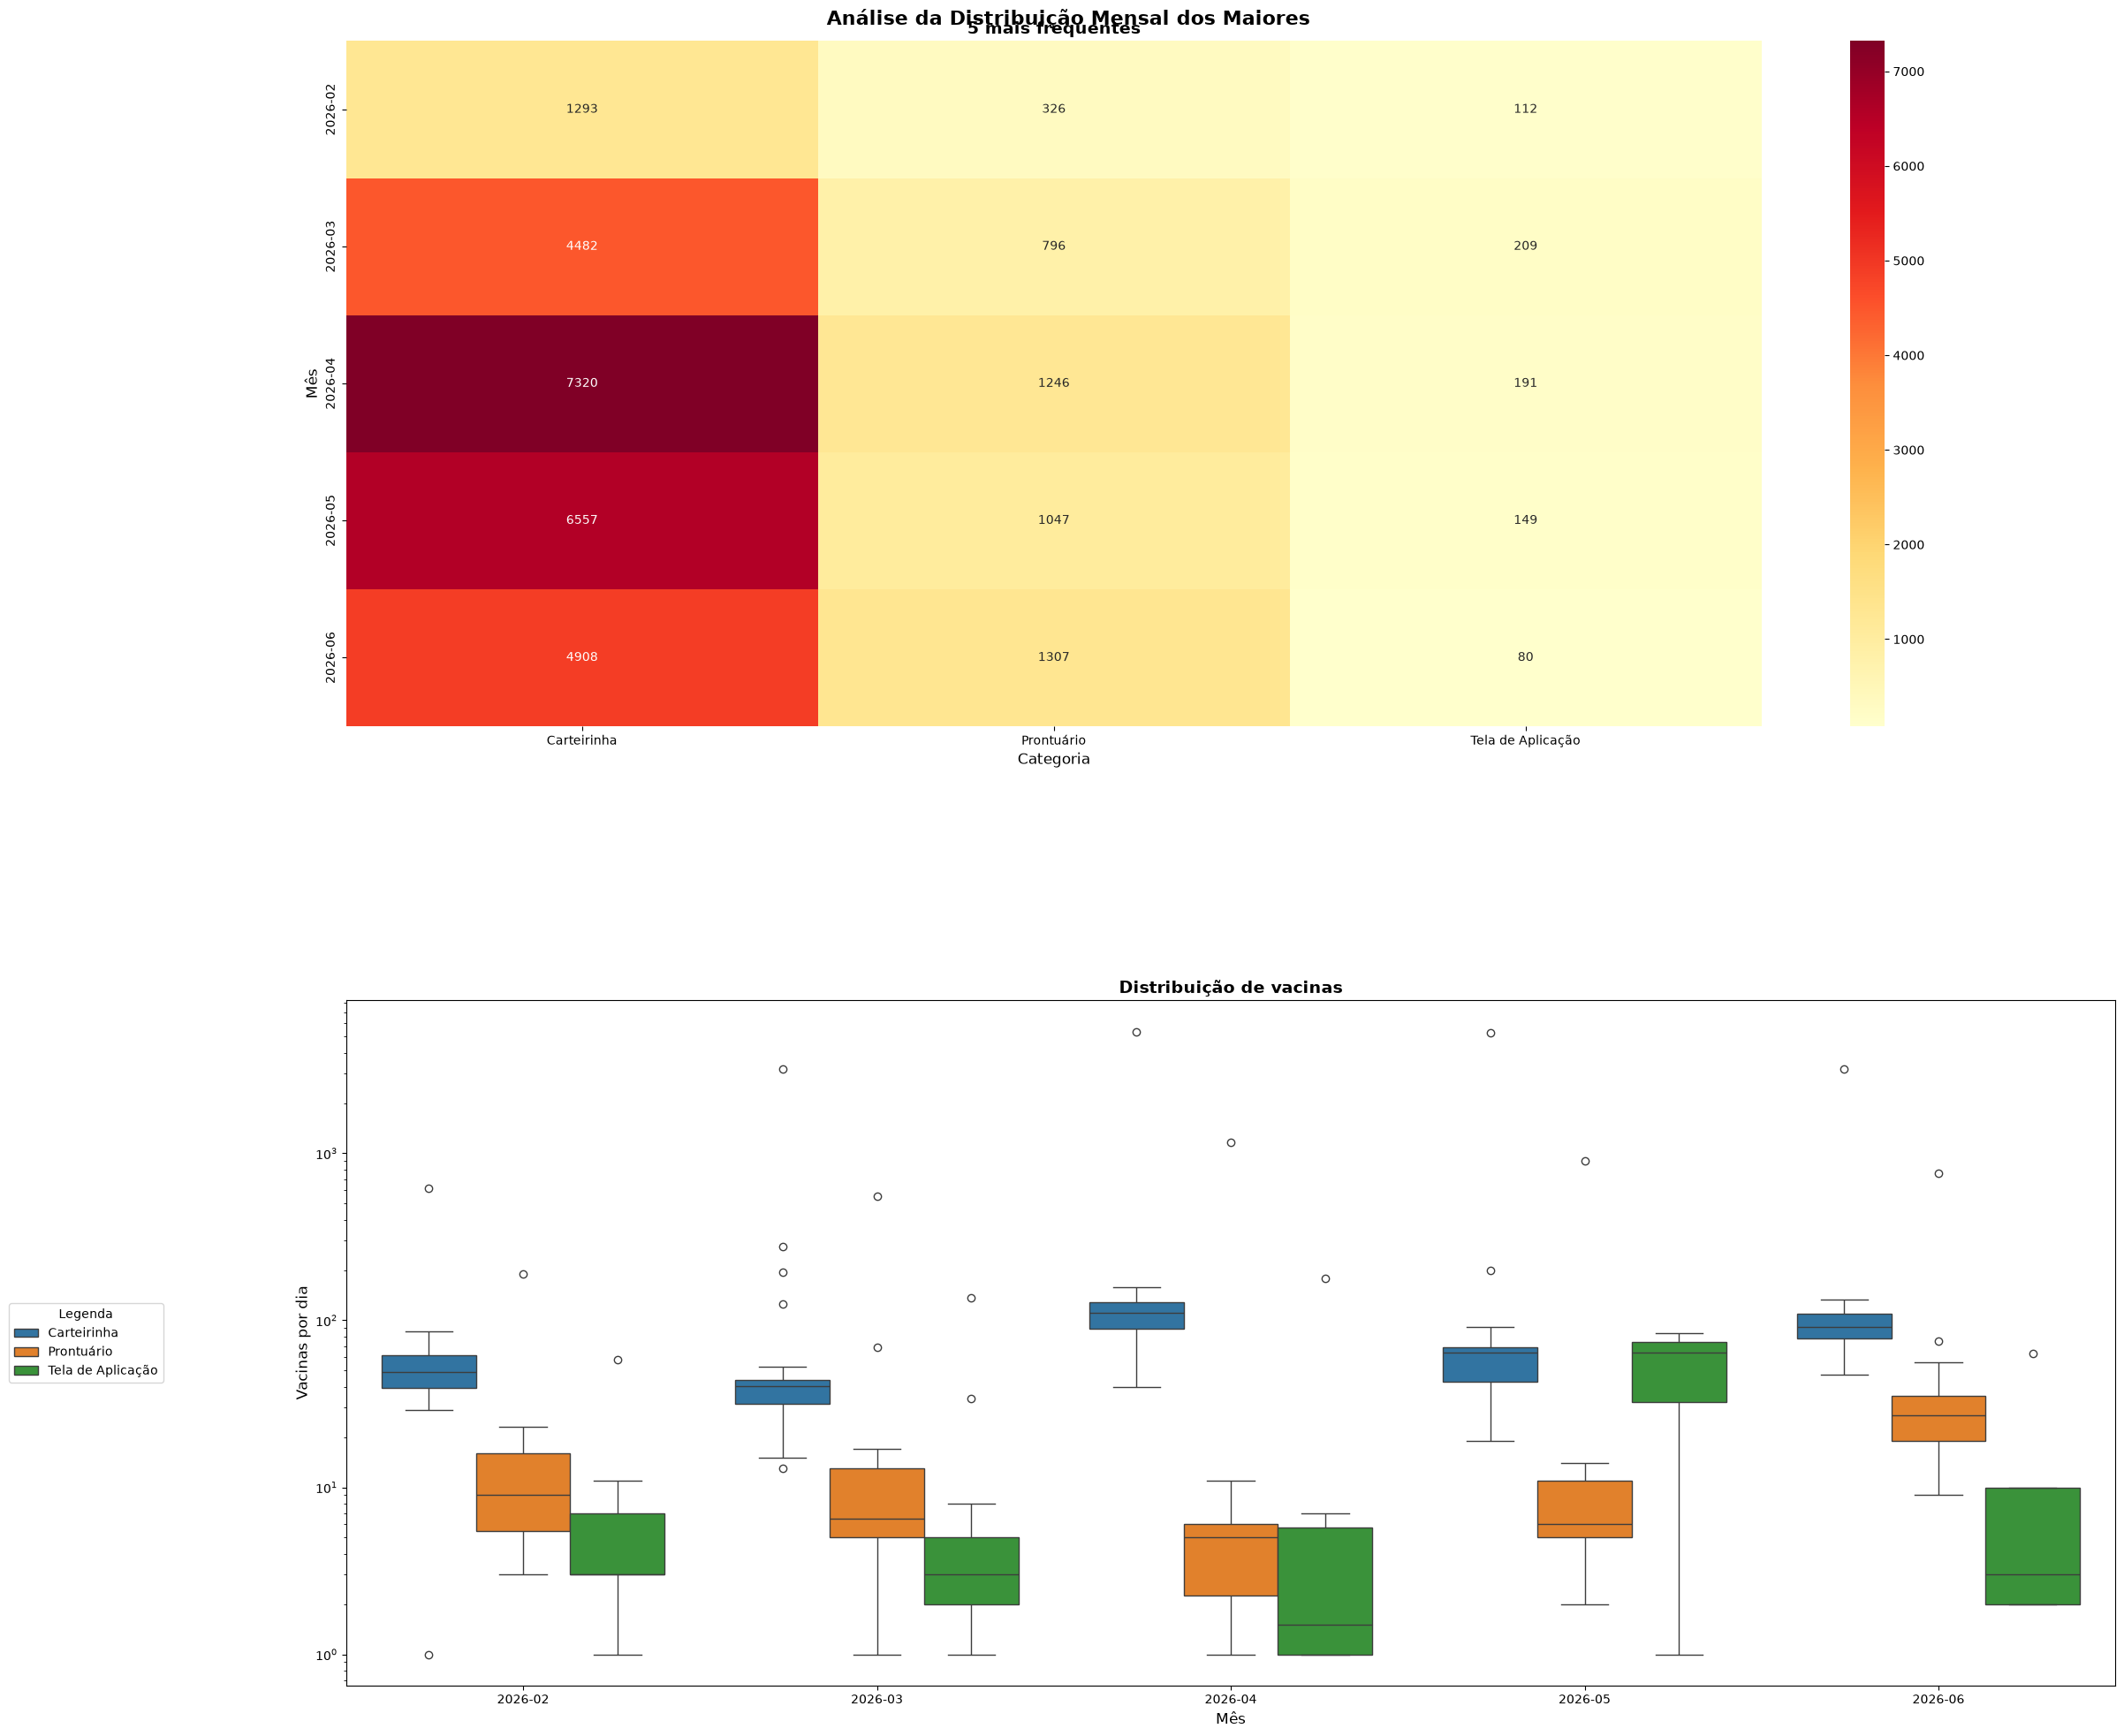

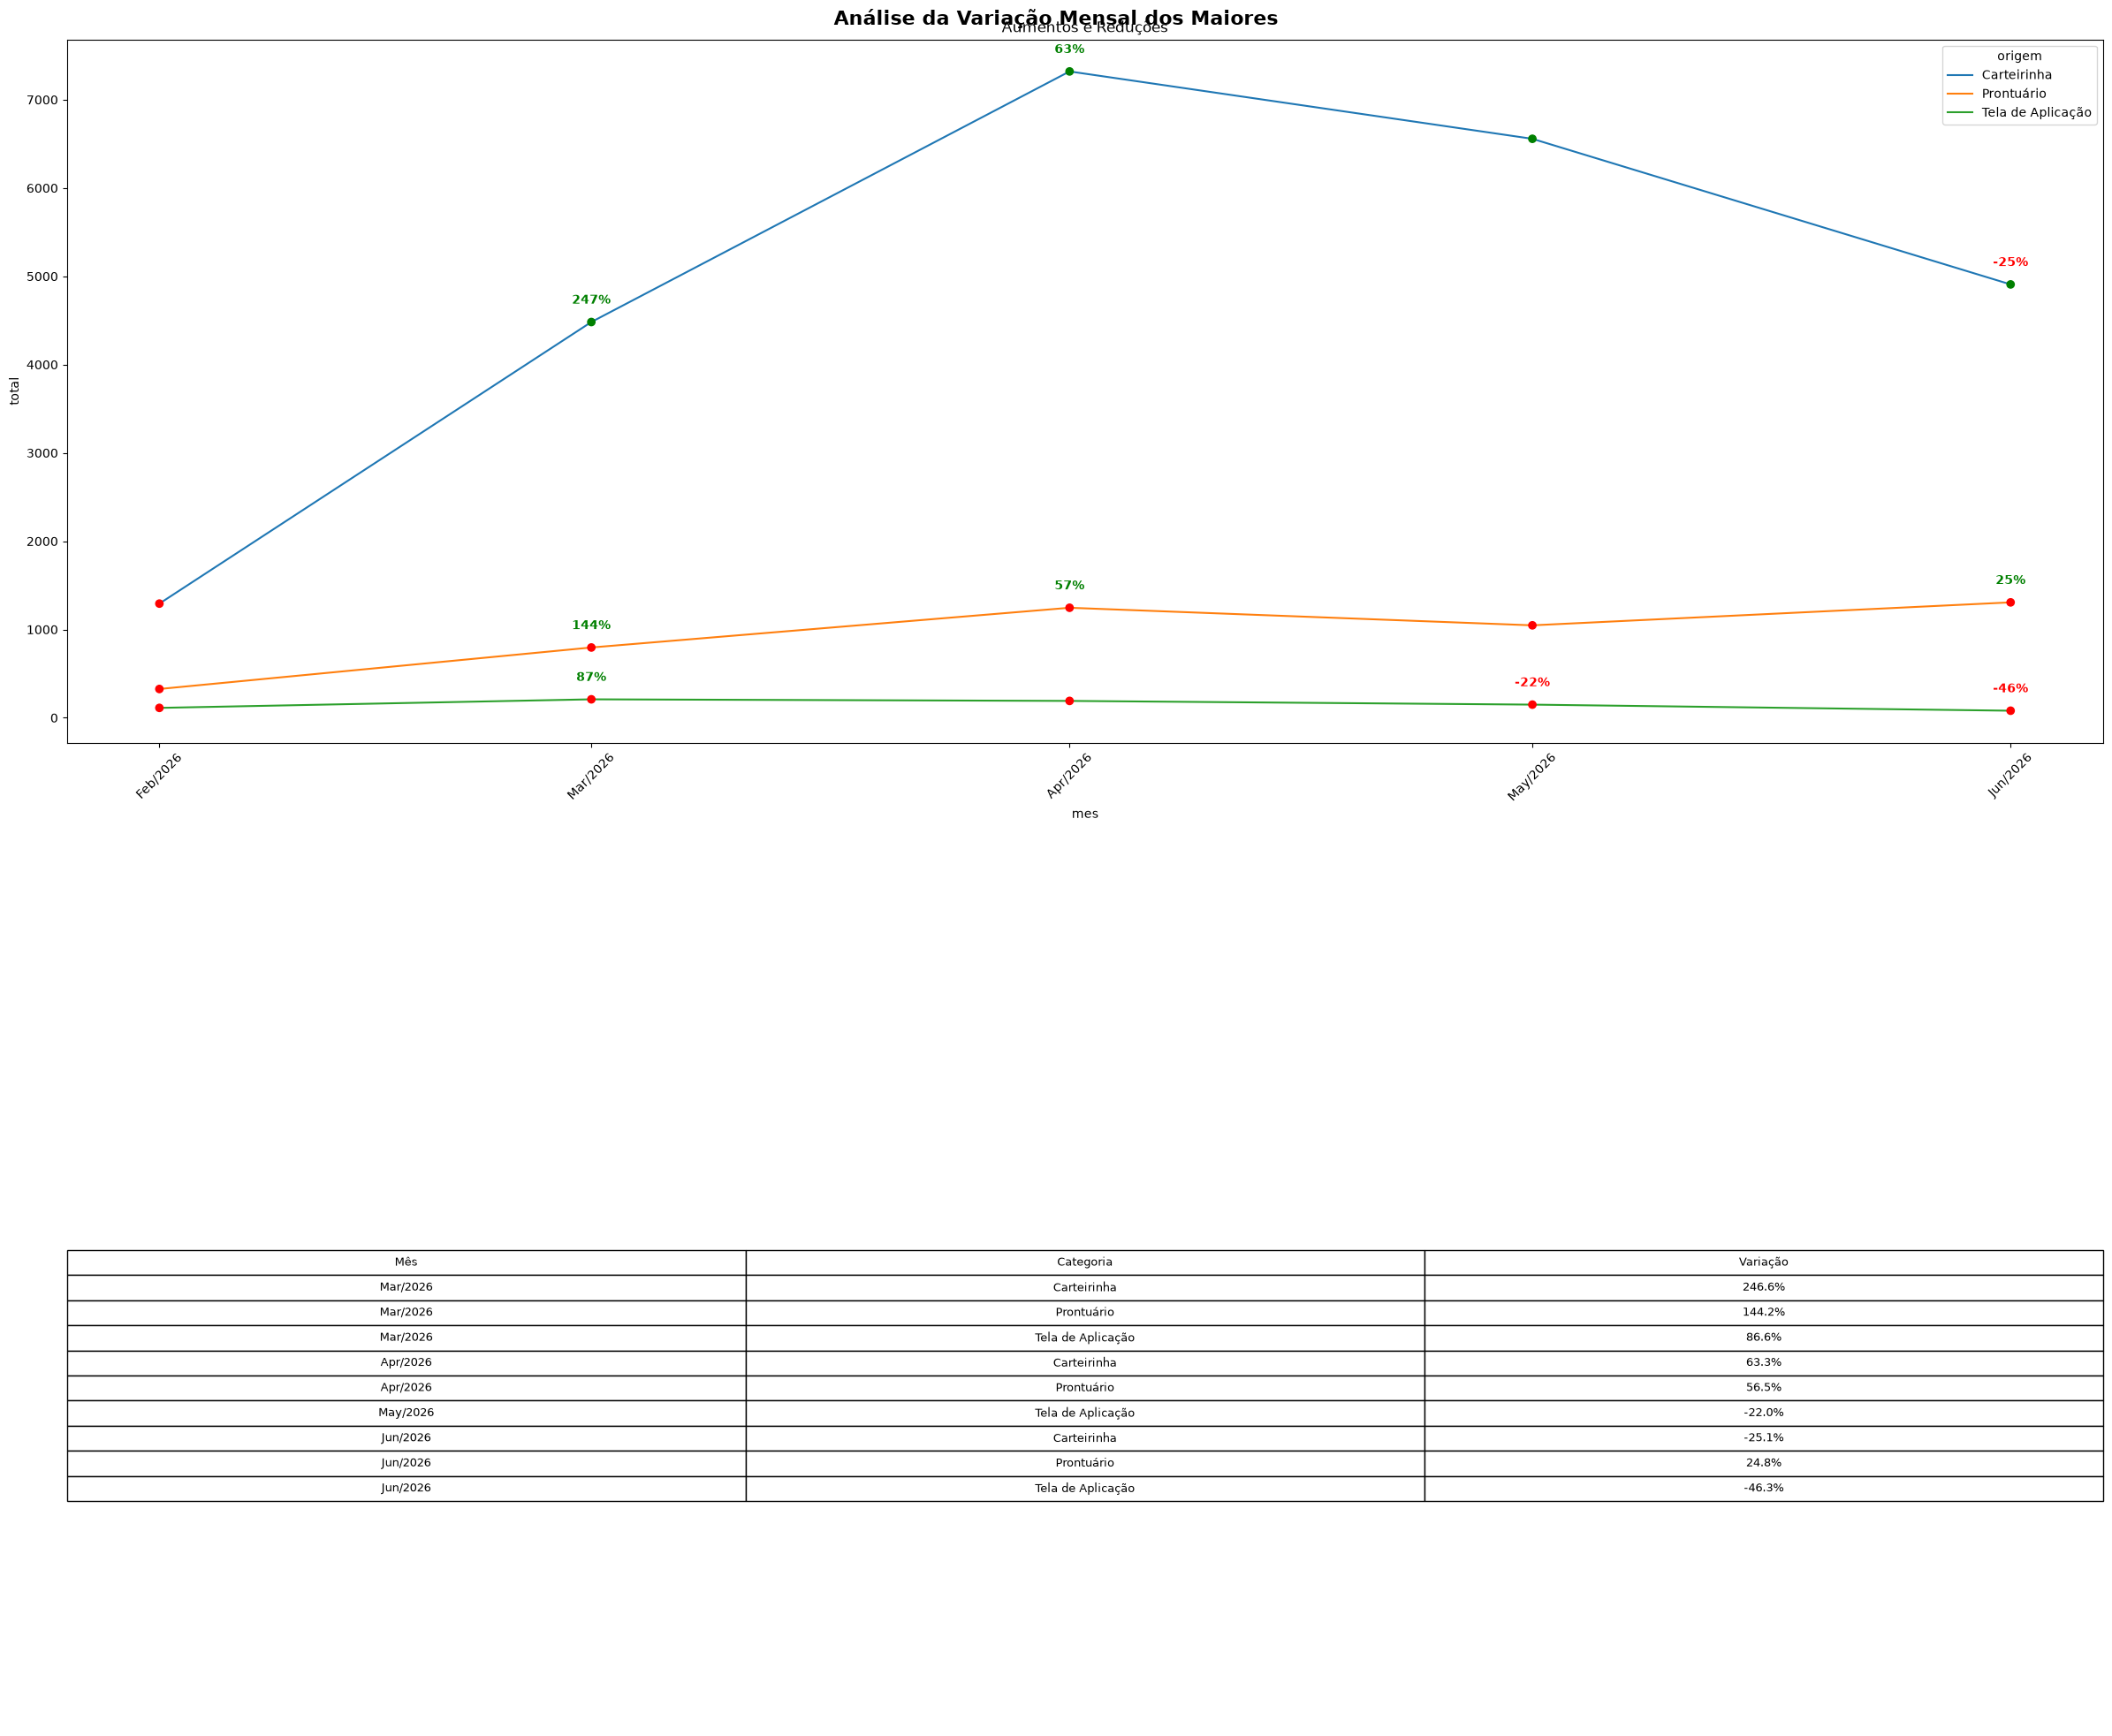

In [37]:
analise_temporal(df, 'origem', 'Origem', 5, False)
distribuicao(df, 'origem', hue = '', index = 'mes', legend_title = 'Legenda', top = 5, ascending=False)
plot_mensal(df, 'origem', ascending=False)

Pontos a observar:
* O fluxo da carteirinha segue o mesmo do fluxo geral
* A constância que a carteirinha apresenta é maior em relação ao prontuário e a Tela de Aplicação
* Nesse perído a carteirinha teve o maior aumento e a tela de aplicação a maior redução
* O prontuário apresentou um aumento constante durante esse período.

## Relatório Resumido

#### Como o volume de aplicações varia ao longo do período

* As aplicações das vacinas tem uma grande variação no mês de abril por conta do início das campanhas de vacinação, mas apresenta um volume baixo durantes os outros meses.
Ao comparar o volume de aplicações e a população total de Araranguá, o volume ainda continua baixo, mesmo com o aumento no inicio do outono.

#### Em quais meses ocorreram aumentos ou reduções relevantes

* Em abril constitui o principal mês do período analisado que tem um aumento bem relevante. Porém, como só a base só possui dados de fevereiro (baixo), março, abril, maio e junho,não é possível fazer uma comparação muito detalhada entre meses.
Talvez a grande redução/baixo volume em fevereiro seja por conta das festividades e menos dias que o mês possui, além das férias.

#### O pico coincide com alguma vacina específica, como a influenza?
 
* Sim, o pico coincide especificamente com a influenza trivalente tendo como principal estratégia a rotina e origem a carteirinha de vacinação. Isso é compreensível por conta do outono, logo após inverno, e as campanhas de vacinação contra o vírus que se propaga mais nessa época do ano.

#### Como diferentes vacinas, salas ou estratégias se comportam no tempo

* Além da influenza, as outras vacinas e estratégias, mantém uma constância no período observado, sem grandes aumentos ou reduções de maneira mais geral.